# Bankruptcy Risk Modeling

Cost-sensitive prediction of next-year corporate bankruptcy from financial statements.

This research project develops financial features, compares model families, and evaluates a frozen decision policy under a 5:1 false-negative/false-positive cost. Adapted from a completed academic project; methodology and recorded findings are preserved. See `docs/METHODOLOGY.md` for evaluation boundaries and `docs/REPRODUCIBILITY.md` for fresh execution evidence.

**Navigation**

- [Business problem](#Business-problem)
- [Evaluation design](#Evaluation-design)
- [Financial feature engineering](#checking-the-financial-ratios-and-preparing-features)
- [Model comparisons](#comparing-models)
- [Nested validation](#checking-the-selection-process-with-nested-validation)
- [Probability checks](#checking-the-predicted-probabilities)
- [Final model](#the-final-model)
- [Final evaluation](#Final-evaluation)

# Business problem

Estimate whether a company will go bankrupt in the following year from financial attributes. Use the prediction to illustrate a financial-risk screening decision: missed bankruptcies carry five cost units and false alarms carry one. These are illustrative relative costs, not observed dollar losses or a deployed credit policy.

# Financial risk context

At the simplest level, a company runs into trouble when the money coming
in isn't enough to cover the money it must pay out.

- **Money coming in**: revenue from sales, and the profit left over after
costs.
- **Money going out**: the costs of doing business, and -- critically --
debts coming due, often with interest attached.
- **The cushion in between**: cash and other liquid resources on hand, and
the equity buffer built up by owners over time.

A company heading toward bankruptcy typically shows some mix of: shrinking
or negative profit, growing obligations, and a thinning cushion. The
dataset gives you dozens of financial attributes that each touch on one
piece of this picture. The analysis examines which signals matter most and how they combine.


# A light glossary of financial terms

A reference for the financial-statement concepts used in this project.

## Revenue & Income (money the company earns)
- **sales** -- total revenue generated from selling products/services
during the year.
- **Gross Profit** -- what's left from sales after subtracting the direct
cost of producing what was sold.
- **Net Profit** -- the bottom line: what's left after *all* expenses,
interest, and taxes are paid.
- **Operating Profit** -- profit from normal day-to-day business, before
financing costs or one-off items.
- **Profit on Sales** -- profit tied specifically to sales activity.
- **EBIT** -- profit before interest and taxes are subtracted, a way to
look at the core business regardless of how it's financed or taxed.
- **EBITDA** -- like EBIT, but also before non-cash accounting charges like
depreciation -- often used as a rough stand-in for cash the business
generates.
- A few other columns are close *flavors of* gross profit -- for example,
with interest or depreciation added back in, or totaled over three years
instead of one. Treat these as closely related variations; the specific
adjustment matters less than recognizing they're all measuring
profitability.

## Costs & Obligations (money the company owes or spends)
- **total_liabilities** -- everything the company owes, both short- and
long-term.
- **short_term_liabilities** -- obligations due within the coming year
(some formulas below call this "current liabilities" -- same thing).
- **Operating Expenses** -- the everyday costs of running the business.
- **Cost of Products Sold** -- the direct cost of producing or acquiring
the goods a company actually sold (sometimes abbreviated COGS).
- **Financial Expenses** -- the cost of financing, mainly interest paid
on borrowed money.
- **Liabilities Net of Cash** -- what the company owes, minus the cash it
has on hand to help pay it off.

## Ownership & Capital (money invested by owners, not borrowed)
- **Owner's Equity** -- the value of the company belonging to its owners
after all debts are subtracted.
- **Retained Earnings** -- accumulated profit kept in the business over
time rather than paid out to owners.
- A couple of other columns are close *flavors of* equity -- one reflects
equity built up from operations rather than what owners first put in,
another (sometimes called "constant capital") combines equity with
long-term borrowing into a single "funds we don't need to repay soon"
figure. These are related capital measures, not fundamentally different
ideas.

## Resources & Assets (what the company has on hand or owns longer-term)
- **total_assets** -- the total value of everything the company owns.
- **Current Assets** -- assets expected to be converted to cash or used up
within a year (things like inventory, receivables, and cash itself).
- **Fixed Assets** -- longer-term physical resources, like property and
equipment, not expected to convert to cash within a year.
- **Inventory** -- the value of goods held for sale.
- **Accounts Receivable** -- money customers owe the company for goods or
services already delivered.
- **Working Capital** -- the cushion left over after covering near-term
bills with short-term assets.
- A couple of other columns are stricter *flavors of* "current assets" --
some assets convert to cash faster than others, so these exclude inventory
(and sometimes receivables too) to focus on the most liquid resources.

A handful of attributes are given to you as ready-made ratios (their
exact formula is listed further below, near where the data is loaded).
Not every provided attribute is necessarily trustworthy -- where you can
cross-check a value against other information you have, it's worth doing.


# Import modules


In [1]:
## Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn

import os
import math

%matplotlib inline


In [2]:
cycler = plt.cycler
from matplotlib.colors import LinearSegmentedColormap

NYU_PURPLE = '#57068C'
NYU_LIGHT_PURPLE = '#AB82C5'
NYU_DARK_PURPLE = '#330662'
NYU_GRAY = '#6D6D6D'
NYU_PURPLES = LinearSegmentedColormap.from_list(
    'nyu_purples', ['#FFFFFF', NYU_LIGHT_PURPLE, NYU_PURPLE, NYU_DARK_PURPLE])
NYU_DIVERGING = LinearSegmentedColormap.from_list(
    'nyu_diverging', [NYU_GRAY, '#FFFFFF', NYU_PURPLE])
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2,
    'axes.prop_cycle': cycler(color=[NYU_PURPLE, NYU_LIGHT_PURPLE, NYU_DARK_PURPLE, NYU_GRAY]),
    'axes.titlecolor': NYU_DARK_PURPLE, 'axes.spines.top': False,
    'axes.spines.right': False, 'figure.facecolor': 'white', 'axes.facecolor': 'white'
})

# Get the data

- Each example is a row of data corresponding to a single company
- The column `Bankrupt` is 1 if the company subsequently went bankrupt; 0
if it did not go bankrupt
- The column `Id` is a Company Identifier
- The other columns (`num_01`, `num_02`, ..., `ratio_01`, `ratio_02`, ...,
`total_assets`, `sales`, `total_liabilities`, `short_term_liabilities`)
are financial attributes for the company; see the glossary above and the
attribute table further below
- `Id` is just a company identifier, not a feature -- don't feed it to
your model


In [3]:
# Data directory
from pathlib import Path

# Set BANKRUPTCY_DATA_DIR or place authorized files in the project data directory.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "notebooks").is_dir() else Path.cwd().parent
DATA_DIR = Path(os.environ.get("BANKRUPTCY_DATA_DIR", PROJECT_ROOT / "data")).resolve()
if not (DATA_DIR / "train" / "companies.csv").is_file():
    raise FileNotFoundError("Training data missing. See data/README.md and set BANKRUPTCY_DATA_DIR.")

data_file = "companies.csv"
data = pd.read_csv( os.path.join(DATA_DIR, "train", data_file) )

target_attr = "Bankrupt"
feature_cols = [c for c in data.columns if c not in (target_attr, "Id")]

n_samples, n_attrs = data.shape
print("Data shape: ", data.shape)


Data shape:  (4818, 68)


I split the labeled data before exploring it, using the specified 80/20 split and random seed. This keeps the test companies out of my feature and model decisions. I also set aside part of the training data to choose a decision threshold later. In the development folds, I keep identical financial profiles together, even if they have different company IDs.

In [4]:
import time
import warnings
# Render tables without importing an extra display package.
class NotebookMarkdown:
    def __init__(self, text):
        self.text = text
    def __str__(self):
        return self.text

def Markdown(text):
    return NotebookMarkdown(text)

def display(*values):
    try:
        shell = get_ipython()
    except NameError:
        shell = None
    for value in values:
        if isinstance(value, (pd.DataFrame, pd.Series)):
            frame = value.to_frame() if isinstance(value, pd.Series) else value
            plain = frame.to_string()
            table = frame.to_html(escape=True, na_rep='Missing / not applicable',
                float_format=lambda x: f'{x:.6g}')
            rendered = ("<style>.bankruptcy-table {overflow-x:auto;max-width:100%;margin:12px 0;}"
                ".bankruptcy-table table {border-collapse:collapse;font-size:13px;}"
                ".bankruptcy-table th {background:#57068C;color:white;padding:8px;white-space:nowrap;}"
                ".bankruptcy-table td {padding:7px;border-bottom:1px solid #e5d9ed;white-space:nowrap;}"
                ".bankruptcy-table tr:nth-child(even) td {background:#f6f0fa;}"
                "</style><div class='bankruptcy-table'>" + table + "</div>")
            if shell is None:
                print(plain)
            else:
                shell.display_pub.publish(data={'text/html': rendered, 'text/plain': plain})
        elif isinstance(value, NotebookMarkdown) and shell is not None:
            shell.display_pub.publish(data={'text/markdown': value.text, 'text/plain': value.text})
        else:
            print(str(value))

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import (train_test_split, StratifiedGroupKFold,
    cross_validate, cross_val_predict, GridSearchCV, learning_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
    roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss,
    make_scorer, precision_recall_curve, roc_curve)

SEED = 42
N_JOBS = 1
X_train, X_test, y_train, y_test = train_test_split(
    data.drop(columns=[target_attr]), data[target_attr], test_size=0.2,
    random_state=42, stratify=data[target_attr])
train_index_locked = X_train.index.copy()
test_index_locked = X_test.index.copy()

def cost(y_true, y_pred, fn_weight=5, fp_weight=1):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return int(fn_weight * np.sum((y_pred == 0) & (y_true == 1))
               + fp_weight * np.sum((y_pred == 1) & (y_true == 0)))

def profile_groups(X):
    # An exact-profile hash uses financial attributes, never Id or labels.
    return pd.util.hash_pandas_object(X.drop(columns='Id'), index=False).to_numpy()

train_groups = profile_groups(X_train)
dev_idx, policy_idx = next(StratifiedGroupKFold(n_splits=4, shuffle=True,
    random_state=SEED).split(X_train, y_train, groups=train_groups))
X_dev, y_dev = X_train.iloc[dev_idx].copy(), y_train.iloc[dev_idx].copy()
X_policy, y_policy = X_train.iloc[policy_idx].copy(), y_train.iloc[policy_idx].copy()
dev_groups = train_groups[dev_idx]
cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
    random_state=SEED).split(X_dev, y_dev, groups=dev_groups))
assert not set(train_groups[dev_idx]) & set(train_groups[policy_idx])
for fit_idx, val_idx in cv:
    assert not set(dev_groups[fit_idx]) & set(dev_groups[val_idx])
print('Development rows:', len(X_dev), '| Threshold-validation rows:', len(X_policy))
print('Development class counts:', y_dev.value_counts().sort_index().to_dict())

Development rows: 2891 | Threshold-validation rows: 963
Development class counts: {0: 2706, 1: 185}


## Have a look at the data

Here's a peek.


The previews below use only development data. Per-company preview outputs are omitted from the distributed notebook; they remain in the ignored local execution report.


In [5]:
display(X_dev.drop(columns='Id').head())


In [6]:
# Original preview: data.info()
X_dev.assign(Bankrupt=y_dev).info()

<class 'pandas.DataFrame'>
Index: 2891 entries, 4618 to 1462
Data columns (total 68 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ratio_03                2887 non-null   float64
 1   ratio_16                2891 non-null   float64
 2   ratio_22                2889 non-null   float64
 3   ratio_15                2886 non-null   float64
 4   ratio_21                2848 non-null   float64
 5   ratio_05                2707 non-null   float64
 6   ratio_19                2841 non-null   float64
 7   ratio_02                2890 non-null   float64
 8   ratio_18                2864 non-null   float64
 9   ratio_11                2890 non-null   float64
 10  ratio_01                1642 non-null   float64
 11  ratio_25                2850 non-null   float64
 12  ratio_08                2891 non-null   float64
 13  ratio_10                2758 non-null   float64
 14  ratio_27                2872 non-null   float64
 15  

## Attributes given as raw figures

Each `num_##` column is a single financial figure for the company. Its
name below tells you which -- look it up in the glossary above for what
it means:

| Attribute | Financial Quantity |
|---|---|
| num_01 | Gross Profit Plus Depreciation |
| num_02 | EBITDA |
| num_03 | Gross Profit |
| num_04 | Operating Profit |
| num_05 | Gross Profit |
| num_06 | Current Assets |
| num_07 | Gross Profit Plus Interest |
| num_08 | Long-Term Capital Base |
| num_09 | Operating Profit |
| num_10 | Inventory |
| num_11 | Gross Profit (3-Year Cumulative) |
| num_12 | Near-Cash Assets |
| num_13 | Net Profit |
| num_14 | Owner's Equity |
| num_15 | Net Profit |
| num_16 | Net Profit Plus Depreciation |
| num_17 | Gross Profit (Adjusted) |
| num_18 | Profit on Sales |
| num_19 | Working Capital |
| num_20 | Retained Earnings |
| num_21 | Operating Expenses |
| num_22 | EBIT |
| num_23 | Current Assets |
| num_24 | EBITDA |
| num_25 | Gross Profit |
| num_26 | Owner's Equity (Beyond Initial Capital) |
| num_27 | Accounts Receivable |
| num_28 | Liabilities Net of Cash |
| num_29 | Owner's Equity |
| num_30 | Gross Profit Plus Interest |
| num_31 | Profit on Sales |
| num_32 | Quick Assets |
| num_33 | Gross Profit |
| num_34 | Gross Profit Plus Depreciation |
| num_35 | Operating Expenses |


## Attributes given as ratios

Some of the attributes are given to you as ready-made ratios. Their
formulas:

| Attribute | Formula |
|---|---|
| ratio_01 | (current assets - inventories) / long-term liabilities |
| ratio_02 | logarithm of total assets |
| ratio_03 | [(cash + short-term securities + receivables - short-term liabilities) / (operating expenses - depreciation)] * 365 |
| ratio_04 | long-term liabilities / equity |
| ratio_05 | profit on operating activities / financial expenses |
| ratio_06 | equity / fixed assets |
| ratio_07 | sales / fixed assets |
| ratio_08 | rotation receivables + inventory turnover in days |
| ratio_09 | total costs / total sales |
| ratio_10 | net profit / inventory |
| ratio_11 | total sales / total assets |
| ratio_12 | (short-term liabilities * 365) / cost of products sold |
| ratio_13 | (short-term liabilities * 365) / sales |
| ratio_14 | constant capital / fixed assets |
| ratio_15 | total assets / total liabilities |
| ratio_16 | sales / total assets |
| ratio_17 | sales / receivables |
| ratio_18 | (current liabilities * 365) / cost of products sold |
| ratio_19 | working capital / fixed assets |
| ratio_20 | sales / short-term liabilities |
| ratio_21 | sales (n) / sales (n-1) |
| ratio_22 | (total liabilities * 365) / (gross profit + depreciation) |
| ratio_23 | (current assets - inventory - short-term liabilities) / (sales - gross profit - depreciation) |
| ratio_24 | sales / inventory |
| ratio_25 | total liabilities / ((profit on operating activities + depreciation) * (12/365)) |
| ratio_26 | working capital |
| ratio_27 | (inventory * 365) / cost of products sold |


# Evaluation design

The labeled file is split into training and test populations before exploration. A separate unlabeled file supports prediction-contract and distribution checks only; it cannot establish accuracy, recall, calibration, or cost.

I define the holdout loader here so it is ready for the final prediction check. I do not load or explore those companies while developing the model.

In [7]:
def load_holdout_data():
    holdout_data = pd.read_csv( os.path.join(DATA_DIR, "holdout", data_file) )

    print("Data shape: ", holdout_data.shape)

    return holdout_data

The primary decision metric is **cost = 5 × false negatives + false positives**. Report recall, precision, average precision (AP), ROC-AUC, Brier score, and accuracy alongside cost. AP here is `average_precision_score`, not trapezoidal precision-recall area. For perfectly calibrated probabilities, the theoretical cutoff under these relative costs is 1/6; the final empirical cutoff of 0.15 is selected using training validation.

# Establish a baseline

The majority classifier predicts healthy for every company. It illustrates why high accuracy is insufficient under class imbalance. Both the baseline and final model use the same frozen 80/20 stratified split and 5:1 cost.

The majority baseline predicts that no company will go bankrupt. Its accuracy might look good, but it misses every bankruptcy. For that reason, I compare models using the specified cost: five units for each missed bankruptcy and one for each false alarm. I fit the baseline here and compare it with the other models in development cross-validation. I calculate its test cost in the final evaluation, once the final model is fixed.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

X_train, X_test, y_train, y_test = train_test_split(
    data.drop(columns=[target_attr]), data[target_attr], test_size=0.2,
    random_state=42, stratify=data[target_attr])

def cost(y_true, y_pred, fn_weight=5, fp_weight=1):
    """Relative decision cost: five units per miss, one per false alarm."""
    fn = ((y_pred == 0) & (y_true == 1)).sum()
    fp = ((y_pred == 1) & (y_true == 0)).sum()
    return fn_weight * fn + fp_weight * fp

baseline_pipeline = DummyClassifier(strategy="most_frequent")
baseline_pipeline.fit(X_train, y_train)  # The majority baseline ignores all features.

def evaluate_test_baseline():
    baseline_cost = cost(y_test, baseline_pipeline.predict(X_test))
    print(f"Baseline cost (always predicts the majority class): {baseline_cost}")

    return baseline_cost


<a id="my-approach"></a>

# Model development

## Approach

I first separate the test data, then explore training distributions, missing values and financial relationships. I check the units before constructing monetary ratios, compare ways to fill blanks, compare model families, tune the promising ones, and study their mistakes. The later experiments test specific ideas from those mistakes. I give both final feature versions the same tuning budget before choosing the final pipeline.

I tried several exploratory ideas on the same training population. I use training validation for every new choice and keep test evaluation in the final report.

Every learned replacement, filter and scaling step stays inside the fitting folds. I check the supplied amounts against their financial relationships before building new features. These input checks use no validation outcomes and cannot independently verify the accounts. The research notebook uses the scientific Python stack and keeps fitted models and predictions in memory.


<a id="exploring-the-training-companies"></a>

## Exploring the training companies

I start with class counts, missing values, repeated financial profiles, and the ranges of the amounts. I keep negative profits and equity because they can describe a company in trouble. A very large amount could simply belong to a large company, so I want to compare ratios with the raw amounts too.

I look at the distributions and relationships first so I can explain which changes are worth trying.

Development data: 2,891 companies, 67 input columns.


,missing_fraction,unique_nonmissing,median,p01,p99
ratio_01,0.43203,1609,3.46855,0.0880695,1306.54
ratio_05,0.0636458,2479,1.0187,-55.4817,4335.3
ratio_10,0.0460048,2685,0.264005,-10.4911,20.2272
ratio_24,0.0460048,2673,9.166,1.28924,498.509
num_11,0.0242131,2781,10.606,-65.3576,177.2
ratio_14,0.0172951,2711,1.4418,-3.49972,66.7146
ratio_19,0.0172951,2787,0.54195,-4.41754,65.9628
ratio_06,0.0172951,2752,1.2737,-4.7415,63.0156
ratio_07,0.0172951,2769,4.1646,0.11867,290.516
ratio_21,0.0148737,2437,1.1209,0.409473,2.68205


Duplicate financial profiles: 24
Duplicate company IDs: 0
Infinite values: 0


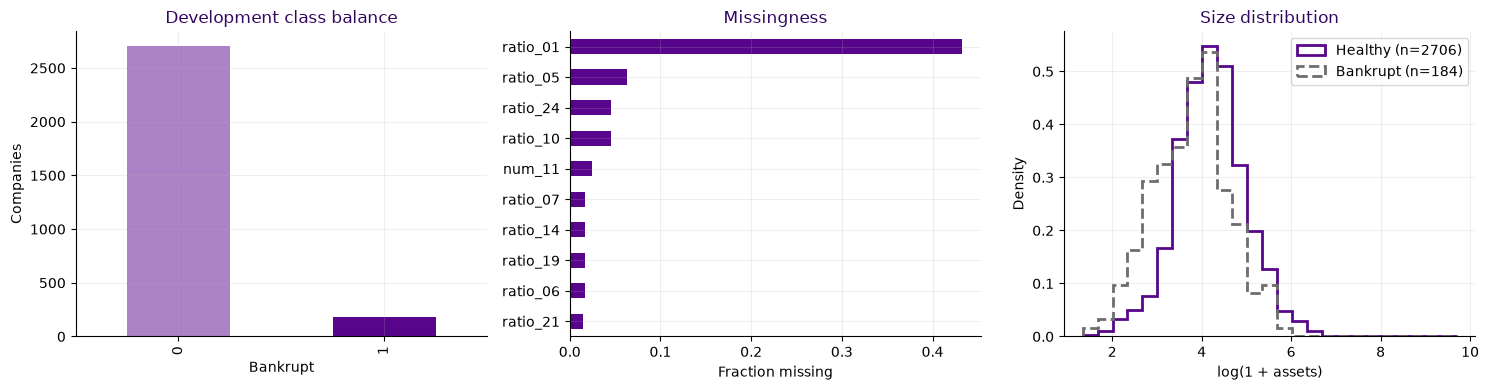

Bankrupt,Healthy,Bankrupt
ratio_03,3.12915,-63.806
ratio_16,1.14755,1.0982
ratio_22,928.73,-531.76
ratio_15,2.2874,1.3421
ratio_21,1.1265,0.92791
ratio_05,1.0634,-1.1628
ratio_19,0.5837,-0.090595
ratio_02,4.1917,3.8047
ratio_18,77.192,132.52
ratio_11,1.5561,1.46215


Development bankruptcies are **6.40%**. The most incomplete feature is **ratio_01** (43.2% missing). Majority accuracy can therefore look excellent while missing every bankruptcy.

In [9]:
display(X_dev.drop(columns='Id').head())
print(f'Development data: {len(X_dev):,} companies, {X_dev.shape[1]} input columns.')
dev_financial = X_dev.drop(columns='Id')
quality = pd.DataFrame({'missing_fraction': dev_financial.isna().mean(),
    'unique_nonmissing': dev_financial.nunique(),
    'median': dev_financial.median(), 'p01': dev_financial.quantile(.01),
    'p99': dev_financial.quantile(.99)})
display(quality.sort_values('missing_fraction', ascending=False).head(15))
print('Duplicate financial profiles:', dev_financial.duplicated().sum())
print('Duplicate company IDs:', X_dev.Id.duplicated().sum())
print('Infinite values:', np.isinf(dev_financial.to_numpy()).sum())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
y_dev.value_counts().sort_index().plot.bar(ax=ax[0], color=[NYU_LIGHT_PURPLE, NYU_PURPLE])
ax[0].set(title='Development class balance', xlabel='Bankrupt', ylabel='Companies')
quality.missing_fraction.nlargest(10).sort_values().plot.barh(ax=ax[1], color=NYU_PURPLE)
ax[1].set(title='Missingness', xlabel='Fraction missing')
size_values = np.log1p(X_dev.total_assets.clip(lower=0))
size_edges = np.histogram_bin_edges(size_values.dropna(), bins=25)
for label, name, color, line in [(0, 'Healthy', NYU_PURPLE, '-'),
                                 (1, 'Bankrupt', NYU_GRAY, '--')]:
    z = size_values.loc[y_dev == label].dropna()
    ax[2].hist(z, bins=size_edges, density=True, histtype='step', linewidth=2,
        linestyle=line, color=color, label=f'{name} (n={len(z)})')
ax[2].set(title='Size distribution', xlabel='log(1 + assets)', ylabel='Density')
ax[2].legend(); plt.tight_layout(); plt.show()
display(dev_financial.groupby(y_dev).median().T.rename(columns={0:'Healthy',1:'Bankrupt'}).head(15))
display(Markdown(f'Development bankruptcies are **{y_dev.mean():.2%}**. '
    f'The most incomplete feature is **{quality.missing_fraction.idxmax()}** '
    f'({quality.missing_fraction.max():.1%} missing). Majority accuracy can therefore '
    'look excellent while missing every bankruptcy.'))

About 6.4% of the development companies went bankrupt. Predicting “healthy” for everyone could therefore look accurate while missing every bankruptcy. I need to look at missed cases, false alarms, and cost as well as accuracy.

`ratio_01` is missing for roughly 43% of these companies. Dropping incomplete rows would remove too much information. I will check the missing values more closely before comparing fill methods. I also found identical financial profiles, which I keep together in the validation folds.

<a id="checking-the-scales-of-inventory-and-receivables"></a>

### Checking the scales of inventory and receivables

I want to compare companies using financial proportions, since an amount by itself also reflects company size. Before creating these features, I check whether the amounts fit together. Inventory and receivables should usually be components of current assets; short-term debt should usually fit within total liabilities. I calculate these relationships first to see whether the stored values support that interpretation. These checks use training inputs only.


In [10]:
unit_checks = []
for label, numerator, denominator in [
    ('Inventory <= current assets', 'num_10', 'num_06'),
    ('Receivables <= current assets', 'num_27', 'num_06'),
    ('Quick assets <= current assets', 'num_32', 'num_06'),
    ('Near cash <= quick assets', 'num_12', 'num_32'),
    ('Short-term debt <= total liabilities', 'short_term_liabilities', 'total_liabilities')]:
    pair = X_dev[[numerator, denominator]].replace([np.inf, -np.inf], np.nan).dropna()
    unit_checks.append(dict(Relationship=label, Observed_pairs=len(pair),
        Fraction_consistent=float((pair[numerator] <= pair[denominator]+1e-8).mean()),
        Median_computed_ratio=float((pair[numerator] / pair[denominator].where(pair[denominator].abs() > 1e-12)).median())))
liquidity_unit_audit = pd.DataFrame(unit_checks).set_index('Relationship')
display(liquidity_unit_audit)


,Observed_pairs,Fraction_consistent,Median_computed_ratio
Relationship,,,
Inventory <= current assets,2885,0.0540728,97.0376
Receivables <= current assets,2885,0.00242634,148.659
Quick assets <= current assets,2884,0.989598,0.685079
Near cash <= quick assets,2884,0.999653,0.204568
Short-term debt <= total liabilities,2890,0.999654,0.912133


**Following up on the unexpected amounts**

Only about 5.4% of inventory amounts and 0.2% of receivable amounts fit within current assets, while the other component checks mostly make sense. The median raw inventory/current-assets ratio is about 97, which would mean inventory is 97 times current assets. That makes me question the scale before treating it as a useful financial share.

There is another way to check these amounts. If `ratio_24` is sales/inventory, then sales/ratio_24 gives an implied inventory amount. I do the same for receivables using `ratio_17`. I compare each stored amount with its implied amount and look at how consistent the difference is across companies. This should show whether I am dealing with a common scale mismatch or a few unusual observations.


,Comparable_rows,Factor_P10,Factor_median,Factor_P90
Quantity,,,,
Inventory,3666,364.992,365,365.009
Receivables,3843,364.993,365,365.006


The middle 80% of stored-to-implied factors are very close to **365** for both amounts. I therefore check a 365 conversion against alternative scales, including the dollars-versus-millions explanation.

Comparable_rows  Matches  Match_percent
Quantity    Divisor                                         
Inventory   1                   3666        0       0.000000
            100                 3666        0       0.000000
            365                 3666     3665      99.972722
            1000                3666        0       0.000000
            1000000             3666        0       0.000000
Receivables 1                   3843        0       0.000000
            100                 3843        0       0.000000
            365                 3843     3842      99.973979
            1000                3843        0       0.000000
            1000000             3843        0       0.000000

Median inventory percentage of current assets after /365: 26.621290824829057
Median approximate DSO in days (stored num_27 / sales): 58.6005


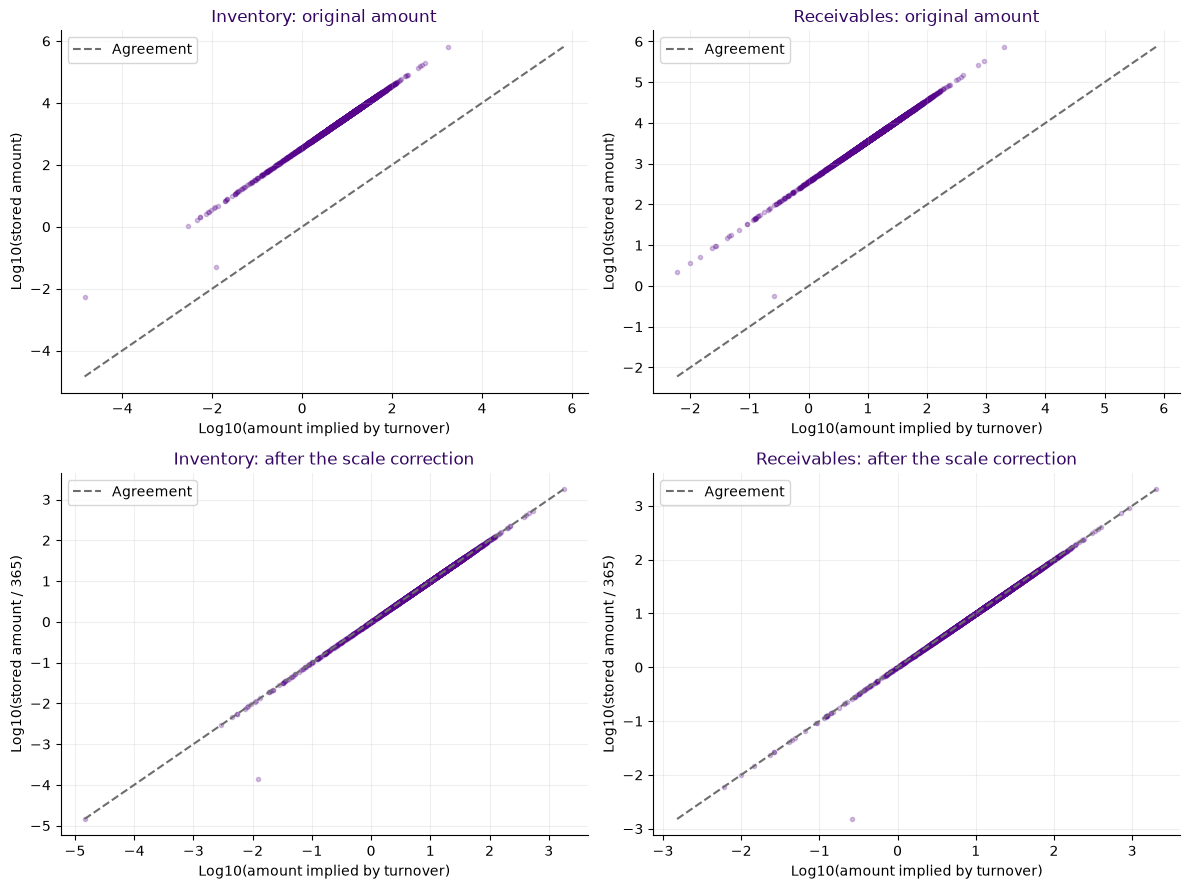

,Quantity,Divisor,Rows,Median_share,Percent_exceeding_current_assets
0,Inventory,1,3844,97.1677,94.3288
1,Inventory,365,3844,0.266213,0.936524
2,Receivables,1,3844,148.925,99.7919
3,Receivables,365,3844,0.408013,1.84703


In [11]:
scale_audit_rows = []
scale_factor_rows = []
amount_comparisons = []
for quantity, stored, implied in [
    ('Inventory', X_train.num_10, X_train.sales / X_train.ratio_24.where(X_train.ratio_24.abs() > 1e-8)),
    ('Receivables', X_train.num_27, X_train.sales / X_train.ratio_17.where(X_train.ratio_17.abs() > 1e-8))]:
    valid = np.isfinite(stored) & np.isfinite(implied) & stored.gt(0) & implied.gt(1e-8)
    relative_scale = stored[valid] / implied[valid]
    scale_factor_rows.append(dict(Quantity=quantity, Comparable_rows=int(valid.sum()),
        Factor_P10=float(relative_scale.quantile(.1)),
        Factor_median=float(relative_scale.median()), Factor_P90=float(relative_scale.quantile(.9))))
    amount_comparisons.append((quantity, stored, implied, valid))

display(pd.DataFrame(scale_factor_rows).set_index('Quantity'))
display(Markdown('The middle 80% of stored-to-implied factors are very close to **365** for both amounts. '
    'I therefore check a 365 conversion against alternative scales, including the dollars-versus-millions explanation.'))
for quantity, stored, implied, valid in amount_comparisons:
    for divisor in [1, 100, 365, 1000, 1000000]:
        matches = np.isclose(stored[valid] / divisor, implied[valid], rtol=.01, atol=1e-6)
        scale_audit_rows.append(dict(Quantity=quantity, Divisor=divisor,
            Comparable_rows=int(valid.sum()), Matches=int(matches.sum()),
            Match_percent=100*float(matches.mean())))
display(pd.DataFrame(scale_audit_rows).set_index(['Quantity', 'Divisor']))
inventory_share = 100 * (X_train.num_10 / 365) / X_train.num_06.where(X_train.num_06 > 0)
dso_proxy = X_train.num_27 / X_train.sales.where(X_train.sales > 0)
print('Median inventory percentage of current assets after /365:',
    inventory_share.replace([np.inf, -np.inf], np.nan).median())
print('Median approximate DSO in days (stored num_27 / sales):',
    dso_proxy.replace([np.inf, -np.inf], np.nan).median())

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for column, (quantity, stored, implied, _) in enumerate(amount_comparisons):
    usable = np.isfinite(stored) & np.isfinite(implied) & stored.gt(0) & implied.gt(0)
    x = np.log10(implied[usable])
    for row, divisor in enumerate([1, 365]):
        ax = axes[row, column]
        z = np.log10(stored[usable] / divisor)
        ax.scatter(x, z, s=9, alpha=.25, color=NYU_PURPLE)
        lo, hi = min(x.min(), z.min()), max(x.max(), z.max())
        ax.plot([lo, hi], [lo, hi], '--', color=NYU_GRAY, label='Agreement')
        stage = 'original amount' if divisor == 1 else 'after the scale correction'
        ax.set(title=f'{quantity}: {stage}', xlabel='Log10(amount implied by turnover)',
            ylabel='Log10(stored amount)' if divisor == 1 else 'Log10(stored amount / 365)')
        ax.legend()
plt.tight_layout(); plt.show()

component_rows = []
for name, raw in [('Inventory', X_train.num_10), ('Receivables', X_train.num_27)]:
    valid = raw.notna() & X_train.num_06.gt(0) & np.isfinite(raw)
    for divisor in [1, 365]:
        shares = (raw[valid] / divisor) / X_train.loc[valid, 'num_06']
        component_rows.append(dict(Quantity=name, Divisor=divisor, Rows=int(valid.sum()),
            Median_share=float(shares.median()), Percent_exceeding_current_assets=100*float(shares.gt(1).mean())))
display(pd.DataFrame(component_rows))


The stored-to-implied factors cluster around 365. Dividing by 365 agrees with the turnover-based amounts in about 99.97% of comparable positive training rows; dividing by one million does not. This is internal consistency with `ratio_24` and `ratio_17`, which may share the same source figures. It does not independently verify the accounting records.

I apply the conversion inside the calculated-feature pipelines. Approximate DSO is `365 * (num_27 / 365) / sales`, so the factors cancel; positive annual sales are required, and credit sales are not separately available. Zero denominators produce missing values. A few component inconsistencies remain, including one negative inventory and one negative receivable amount. I keep these visible rather than remove companies or force an accounting identity.

Shares enter the model as fractions; I multiply by 100 only when displaying percentages.

| Feature | Calculation from the original inputs | Interpretation |
|---|---|---|
| Inventory/assets | `(num_10 / 365) / total_assets` | Inventory share of assets |
| Inventory/sales | `(num_10 / 365) / sales` | Inventory relative to sales |
| Inventory/current-assets | `(num_10 / 365) / num_06` | Inventory share of current assets |
| Receivables/assets | `(num_27 / 365) / total_assets` | Receivable share of assets |
| Approximate DSO | `365 * (num_27 / 365) / sales` | Approximate collection days |

In [12]:
def safe_divide(a, b):
    return a / b.where(b.abs() > 1e-12)

class FinancialFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, mode='normalized'):
        self.mode = mode

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.output_columns_ = self.transform(X.iloc[:1]).columns.to_numpy()
        return self

    def transform(self, X):
        f = X.drop(columns=['Id', 'Bankrupt'], errors='ignore').astype(float).copy()
        f = f.replace([np.inf, -np.inf], np.nan)
        if self.mode == 'raw':
            return f
        # The provided turnover ratios support this internally consistent 365 conversion.
        # This does not independently verify the underlying accounting figures.
        # This is row-wise arithmetic: it learns nothing from validation or test rows.
        f[['num_10', 'num_27']] = f[['num_10', 'num_27']] / 365
        monetary = f.copy()
        # These use the stated formulas as an alternative representation.
        # The audit shows that not every supplied ratio agrees with its reconstruction.
        f['ratio_02'] = np.log(f.total_assets.where(f.total_assets > 0))
        f['ratio_15'] = safe_divide(f.total_assets, f.total_liabilities)
        f['ratio_16'] = safe_divide(f.sales, f.total_assets)
        f['ratio_13'] = 365 * safe_divide(f.short_term_liabilities, f.sales)
        f['ratio_20'] = safe_divide(f.sales, f.short_term_liabilities)
        f['ratio_26'] = f.num_19
        if self.mode == 'normalized':
            assets = f.total_assets.where(f.total_assets > 0)
            for col in [c for c in f.columns if c.startswith('num_')]:
                f[col + '_to_assets'] = safe_divide(f[col], assets)
                f = f.drop(columns=col)
            f['liabilities_to_assets'] = safe_divide(f.total_liabilities, assets)
            f['short_liabilities_to_assets'] = safe_divide(f.short_term_liabilities, assets)
            f['working_capital_to_assets'] = safe_divide(f.ratio_26, assets)
            f['current_ratio'] = safe_divide(X.num_06, X.short_term_liabilities)
            f['net_margin'] = safe_divide(X.num_13, X.sales)
            f['inventory_to_sales'] = safe_divide(monetary.num_10, monetary.sales)
            f = f.drop(columns=['total_assets', 'sales', 'total_liabilities',
                'short_term_liabilities', 'ratio_26'])
        return f.replace([np.inf, -np.inf], np.nan)

    def get_feature_names_out(self, input_features=None):
        return self.output_columns_

class CorrelationFilter(TransformerMixin, BaseEstimator):
    def __init__(self, limit=0.995):
        self.limit = limit

    def fit(self, X, y=None):
        # The deterministic column order decides which member is retained.
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        corr = X.corr().abs()
        kept = []
        for c in X.columns:
            if X[c].nunique(dropna=True) > 1 and (not kept or
                not (corr.loc[c, kept] > self.limit).any()):
                kept.append(c)
        self.columns_ = kept
        return self

    def transform(self, X):
        return X.loc[:, self.columns_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)

def signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

class FixedThresholdClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator, threshold=1/6):
        self.estimator = estimator
        self.threshold = threshold

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator).fit(X, y)
        self.classes_ = self.estimator_.classes_
        self.n_features_in_ = self.estimator_.n_features_in_
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)

def make_model(family, mode='normalized', pca=False, **params):
    factories = {
        'LogisticRegression': lambda: LogisticRegression(C=1, solver='lbfgs',
            max_iter=3000, random_state=SEED),
        'GaussianNB': GaussianNB,
        'KNeighborsClassifier': lambda: KNeighborsClassifier(n_neighbors=21),
        'DecisionTreeClassifier': lambda: DecisionTreeClassifier(max_depth=5,
            min_samples_leaf=15, random_state=SEED),
        'RandomForestClassifier': lambda: RandomForestClassifier(n_estimators=200,
            max_depth=10, min_samples_leaf=3, n_jobs=1, random_state=SEED),
        'HistGradientBoostingClassifier': lambda: HistGradientBoostingClassifier(
            max_iter=150, max_leaf_nodes=15, min_samples_leaf=20,
            l2_regularization=1, early_stopping=False, random_state=SEED)
    }
    estimator = factories[family]().set_params(**params)
    steps = [('features', FinancialFeatures(mode)), ('correlations', CorrelationFilter()),
        ('imputer', SimpleImputer(strategy='median', add_indicator=True,
                                 keep_empty_features=True)),
        ('signed_log', FunctionTransformer(signed_log, feature_names_out='one-to-one'))]
    if family in ['LogisticRegression', 'GaussianNB', 'KNeighborsClassifier']:
        steps.append(('scale', RobustScaler()))
    if pca:
        steps.append(('pca', PCA(n_components=0.95, svd_solver='full')))
    steps.append(('classifier', estimator))
    return Pipeline(steps)

def metric_row(y, pred, prob):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, pred), Recall=recall_score(y, pred,
        zero_division=0), Precision=precision_score(y, pred, zero_division=0),
        ROC_AUC=roc_auc_score(y, prob), AP=average_precision_score(y, prob),
        Brier=brier_score_loss(y, prob), TN=int(tn), FP=int(fp), FN=int(fn),
        TP=int(tp), Cost=cost(y, pred), Cost_per_company=cost(y, pred)/len(y))

def fixed_cost_score(estimator, X, y):
    pred = (estimator.predict_proba(X)[:, 1] >= 1/6).astype(int)
    return -cost(y, pred)/len(y)

scoring = {'neg_cost': fixed_cost_score, 'AP': 'average_precision',
    'ROC_AUC': 'roc_auc', 'Accuracy': 'accuracy',
    'Recall': make_scorer(recall_score, zero_division=0),
    'Precision': make_scorer(precision_score, zero_division=0)}

# Alternative feature construction, defined with the other preparation tools.
class ExtendedFinancialFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, representation='combined'):
        self.representation=representation

    def fit(self,X,y=None):
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.n_features_in_=X.shape[1]
        self.output_columns_=self.transform(X.iloc[:1]).columns.to_numpy()
        return self

    def transform(self,X):
        if self.representation=='combined':
            levels=FinancialFeatures('audited').transform(X)
            ratios=FinancialFeatures('normalized').transform(X)
            f=pd.concat([levels,ratios.loc[:,~ratios.columns.isin(levels.columns)]],axis=1)
        else:
            f=FinancialFeatures(self.representation).transform(X)
        if self.representation=='combined':
            f['near_cash_to_short_debt']=safe_divide(X.num_12,X.short_term_liabilities)
            f['short_debt_share']=safe_divide(X.short_term_liabilities,X.total_liabilities)
            f['EBITDA_to_debt']=safe_divide(X.num_02,X.total_liabilities)
            f['working_capital_to_sales']=safe_divide(X.num_19,X.sales)
            f['debt_to_sales']=safe_divide(X.total_liabilities,X.sales)
        return f.replace([np.inf,-np.inf],np.nan)

    def get_feature_names_out(self,input_features=None):
        return self.output_columns_


class ProfitDistressFeatures(FinancialFeatures):
    # Targeted follow-up candidate: profit may look reassuring despite debt/liquidity trouble.
    def transform(self, X):
        f = super().transform(X)
        profit = X.num_13.astype(float).replace([np.inf, -np.inf], np.nan)
        nonnegative_profit = profit.ge(0).astype(float).where(profit.notna())
        f['nonnegative_profit_x_leverage'] = nonnegative_profit * f.liabilities_to_assets
        f['nonnegative_profit_x_short_debt'] = nonnegative_profit * f.short_liabilities_to_assets
        f['nonnegative_profit_x_liquidity_gap'] = nonnegative_profit * (1-f.current_ratio).clip(lower=0)
        return f.replace([np.inf, -np.inf], np.nan)


class LiquidityQualityFeatures(FinancialFeatures):
    # Follow-up feature bundle: compare liquid resources with near-term obligations.
    def transform(self, X):
        f = super().transform(X)
        f['near_cash_to_short_debt'] = safe_divide(X.num_12, X.short_term_liabilities)
        f['quick_assets_to_short_debt'] = safe_divide(X.num_32, X.short_term_liabilities)
        f['inventory_share_current_assets'] = safe_divide(X.num_10 / 365, X.num_06)
        f['short_debt_share'] = safe_divide(X.short_term_liabilities, X.total_liabilities)
        f['dso_days'] = 365 * safe_divide(X.num_27 / 365, X.sales.where(X.sales > 0))
        positive_wc = X.num_19.ge(0).astype(float).where(X.num_19.notna())
        quick_gap = (1-f.quick_assets_to_short_debt).clip(lower=0)
        f['nonnegative_working_capital_x_quick_gap'] = positive_wc * quick_gap
        return f.replace([np.inf, -np.inf], np.nan)


class LiquidityCheckedFeatures(LiquidityQualityFeatures):
    # Ablation: omit inventory concentration and collection days from the bundle.
    def transform(self, X):
        return super().transform(X).drop(columns=[
            'inventory_share_current_assets', 'dso_days'])


# A targeted alternative: estimate ratio_21 only and retain all original missingness flags.
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

class Ratio21RegressionImputer(TransformerMixin, BaseEstimator):
    def __init__(self, n_estimators=150, max_depth=10, min_samples_leaf=10,
                 max_features=0.7, random_state=42):
        self.n_estimators=n_estimators
        self.max_depth=max_depth
        self.min_samples_leaf=min_samples_leaf
        self.max_features=max_features
        self.random_state=random_state

    def fit(self, X, y=None):
        # y is deliberately unused: the imputation target is sales growth, not bankruptcy.
        self.feature_names_in_=np.asarray(X.columns, dtype=object)
        self.n_features_in_=X.shape[1]
        self.target_position_=X.columns.get_loc('ratio_21')
        self.predictor_columns_=[col for col in X if col != 'ratio_21']
        self.median_=SimpleImputer(strategy='median', add_indicator=True,
            keep_empty_features=True).fit(X)
        self.indicator_=self.median_.indicator_
        observed=X.ratio_21.notna()
        assert observed.sum() > 2
        self.regressor_=Pipeline([
            ('signed_log', FunctionTransformer(signed_log)),
            ('predictor_fill', SimpleImputer(strategy='median', add_indicator=True,
                keep_empty_features=True)),
            ('regression', RandomForestRegressor(n_estimators=self.n_estimators,
                max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                max_features=self.max_features, random_state=self.random_state, n_jobs=1))])
        self.regressor_.fit(X.loc[observed,self.predictor_columns_],
            signed_log(X.loc[observed,'ratio_21'].to_numpy()))
        return self

    def predict_ratio21(self, X):
        estimated_log=self.regressor_.predict(X.loc[:,self.predictor_columns_])
        return np.sign(estimated_log)*np.expm1(np.abs(estimated_log))

    def transform(self, X):
        output=self.median_.transform(X)
        absent=X.ratio_21.isna().to_numpy()
        if absent.any():
            output[absent,self.target_position_]=self.predict_ratio21(X.loc[absent])
        return output

    def get_feature_names_out(self, input_features=None):
        return self.median_.get_feature_names_out(input_features)


<a id="checking-the-financial-ratios-and-preparing-features"></a>

## Checking the financial ratios and preparing features

I check formulas that can be calculated from the supplied financial amounts, allowing for rounding. When a formula does not match, I cannot assume that the supplied ratio is wrong: the units or definition might differ. For example, `ratio_11` refers to total sales, while `ratio_16` refers to sales.

These checks help me decide which alternative representations are worth comparing. They do not justify changing the source data.

,Pairs,Formula_match,Spearman,Median_abs_difference
Attribute,,,,
ratio_02,2890,1,1,0
ratio_15,2885,1,1,3.21594e-05
ratio_16,2890,1,1,0
ratio_13,2890,0.627336,0.847374,0.00274411
ratio_20,2884,0.626907,0.84642,0.000182061
ratio_26,2890,0,0.890784,2792.1
num_19,2885,1,1,0.000400682


,,Absolute correlation
num_22_to_assets,num_33_to_assets,1
num_30_to_assets,num_33_to_assets,1
num_22_to_assets,num_30_to_assets,1
num_19_to_assets,working_capital_to_assets,1
num_33_to_assets,num_25_to_assets,1
num_22_to_assets,num_25_to_assets,1
num_30_to_assets,num_25_to_assets,1
num_14_to_assets,num_29_to_assets,1
num_06_to_assets,num_23_to_assets,1
ratio_19,ratio_14,0.998897


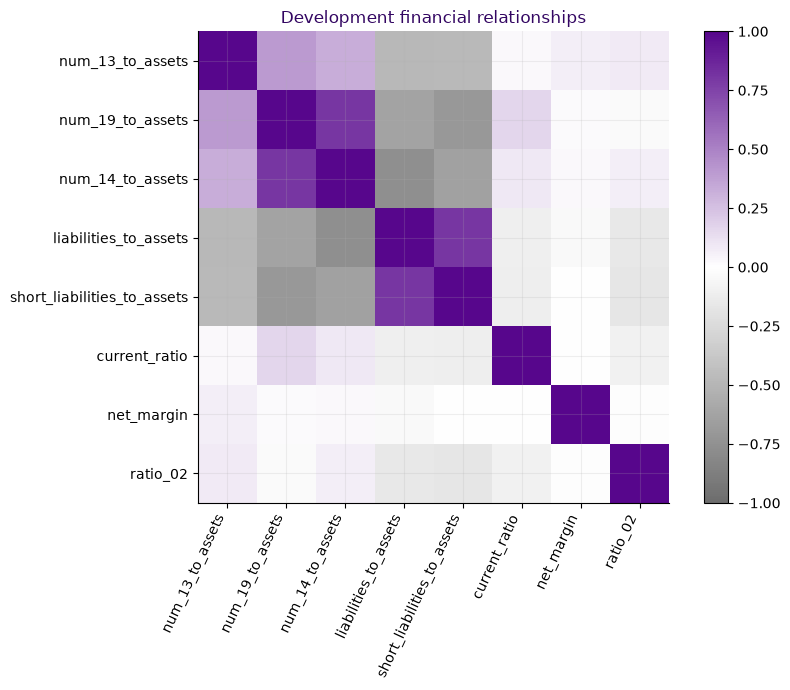

The table above documents exactly which formulas disagree. We test deterministic reconstruction rather than inferring a label-based correction. Near-redundant columns are filtered at |correlation| > 0.995 inside each fit; regularization and tree capacity controls address the remaining redundancy.

In [13]:
a = X_dev
identities = {
    'ratio_02': np.log(a.total_assets.where(a.total_assets>0)),
    'ratio_15': safe_divide(a.total_assets,a.total_liabilities),
    'ratio_16': safe_divide(a.sales,a.total_assets),
    'ratio_13': 365*safe_divide(a.short_term_liabilities,a.sales),
    'ratio_20': safe_divide(a.sales,a.short_term_liabilities),
    'ratio_26': a.num_19,
    'num_19': a.num_06-a.short_term_liabilities}
audit_rows=[]
for name, expected in identities.items():
    actual=a[name]; usable=actual.notna() & expected.notna() & np.isfinite(expected)
    audit_rows.append({'Attribute':name,'Pairs':int(usable.sum()),
        'Formula_match':np.isclose(actual[usable],expected[usable],rtol=.002,atol=.002).mean(),
        'Spearman':actual[usable].corr(expected[usable],method='spearman'),
        'Median_abs_difference':(actual[usable]-expected[usable]).abs().median()})
audit_table=pd.DataFrame(audit_rows).set_index('Attribute')
display(audit_table)
amounts = FinancialFeatures('normalized').fit_transform(X_dev)
corr_dev = amounts.corr().abs()
upper = corr_dev.where(np.triu(np.ones(corr_dev.shape), k=1).astype(bool))
display(upper.stack().sort_values(ascending=False).head(12).rename('Absolute correlation'))
fig, ax=plt.subplots(figsize=(9,7))
important_cols=['num_13_to_assets','num_19_to_assets','num_14_to_assets',
    'liabilities_to_assets','short_liabilities_to_assets','current_ratio','net_margin','ratio_02']
image=ax.imshow(amounts[important_cols].corr(),vmin=-1,vmax=1,cmap=NYU_DIVERGING)
ax.set_xticks(range(len(important_cols)),important_cols,rotation=65,ha='right')
ax.set_yticks(range(len(important_cols)),important_cols)
ax.set_title('Development financial relationships');fig.colorbar(image,ax=ax)
plt.tight_layout();plt.show()
display(Markdown('The table above documents exactly which formulas disagree. '
    'We test deterministic reconstruction rather than inferring a label-based correction. '
    'Near-redundant columns are filtered at |correlation| > 0.995 inside each fit; '
    'regularization and tree capacity controls address the remaining redundancy.'))

Log-assets and sales/assets match the supplied ratios. The calculations for `ratio_13` and `ratio_20` match only about 62.7% of development companies. `ratio_26` does not match the raw working-capital amount, while `num_19` closely matches current assets minus short-term liabilities.

I keep three feature versions for the later model comparison: the original columns; a version that recalculates six ratios from the stated formulas; and a version that also divides financial amounts by assets and adds debt, liquidity, and margin ratios. The recalculated versions are alternatives to test, rather than corrections I know are right. Dividing amounts by assets helps compare companies of different sizes. A zero denominator gives a missing value rather than a made-up zero.

Several profit and equity columns are almost duplicates. The pipeline will remove constant columns and correlations above 0.995 using only the fitting fold. It also uses a signed log to reduce the influence of extreme values while keeping negative amounts. Linear and distance-based models get robust scaling. I define the calculations here, but fit any learned parameters only on the fitting rows.

<a id="looking-closely-at-missing-values"></a>

## Looking closely at missing values

Before settling on a fill method, I look at how much is missing, the observed distributions, and whether blanks are more common among bankrupt companies. I check both the original columns and the calculated features, since a ratio can become missing when its denominator is zero.

I use the 3,854 training companies for these descriptive checks. The model-family comparison uses a smaller development subset; later grouped comparisons use the full training pool. I keep the test and actual holdout out of exploration and fitting in this execution.

Raw financial columns: missingness and value ranges


,Observed,Missing,Missing_fraction,Missing_healthy,Missing_bankrupt,Bankrupt_when_missing,Rate_when_missing,Rate_when_observed,Minimum,P01,Median,Mean,P99,Maximum,Negative,Zero
Feature,,,,,,,,,,,,,,,,
ratio_01,2186,1668,0.432797,0.427661,0.50813,125,0.07494,0.0553522,-4.3258,0.0898158,3.51995,111.209,1370.09,40559,1,2
ratio_05,3597,257,0.066684,0.0504435,0.304878,75,0.291829,0.0475396,-85788,-99.4877,1.0089,481.824,4360.75,565940,541,243
ratio_10,3669,185,0.0480021,0.0454545,0.0853659,21,0.113514,0.0613246,-3037.3,-9.95734,0.26715,101.707,31.9468,366030,743,28
ratio_24,3669,185,0.0480021,0.0454545,0.0853659,21,0.113514,0.0613246,-12.44,1.23776,9.0817,1367.98,557.891,4.8187e+06,1,0
num_11,3758,96,0.0249092,0.0263304,0.00406504,1,0.0104167,0.0651943,-1325.11,-66.1185,10.7282,18.1557,165.515,1829.68,794,8
ratio_14,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-1088.7,-3.33435,1.42025,9.96968,89.5063,8309.6,131,1
ratio_19,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-1089.7,-4.066,0.52285,7.20172,92.6403,5534,733,1
ratio_06,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-1088.7,-4.2803,1.2625,8.73482,85.5671,8309.6,195,1
ratio_07,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-3.7265,0.142607,4.0121,40.0481,420.718,28999,1,1


Normalized/engineered columns: missingness and value ranges


,Observed,Missing,Missing_fraction,Missing_healthy,Missing_bankrupt,Bankrupt_when_missing,Rate_when_missing,Rate_when_observed,Minimum,P01,Median,Mean,P99,Maximum,Negative,Zero
Feature,,,,,,,,,,,,,,,,
ratio_01,2186,1668,0.432797,0.427661,0.50813,125,0.07494,0.0553522,-4.3258,0.0898158,3.51995,111.209,1370.09,40559,1,2
ratio_05,3597,257,0.066684,0.0504435,0.304878,75,0.291829,0.0475396,-85788,-99.4877,1.0089,481.824,4360.75,565940,541,243
ratio_10,3669,185,0.0480021,0.0454545,0.0853659,21,0.113514,0.0613246,-3037.3,-9.95734,0.26715,101.707,31.9468,366030,743,28
ratio_24,3669,185,0.0480021,0.0454545,0.0853659,21,0.113514,0.0613246,-12.44,1.23776,9.0817,1367.98,557.891,4.8187e+06,1,0
num_11_to_assets,3758,96,0.0249092,0.0263304,0.00406504,1,0.0104167,0.0651943,-463.89,-1.10539,0.163755,0.100478,1.59112,99.942,794,8
ratio_07,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-3.7265,0.142607,4.0121,40.0481,420.718,28999,1,1
ratio_06,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-1088.7,-4.2803,1.2625,8.73482,85.5671,8309.6,195,1
ratio_19,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-1089.7,-4.066,0.52285,7.20172,92.6403,5534,733,1
ratio_14,3782,72,0.0186819,0.0166297,0.0487805,12,0.166667,0.061872,-1088.7,-3.33435,1.42025,9.96968,89.5063,8309.6,131,1


Rows missing total_assets: 2
Rows with nonpositive total_assets: 0
Rows with zero sales: 0
Rows with zero short-term liabilities: 9


,Companies
Missing columns,
No missing values,1957
ratio_01,1288
"ratio_05, ratio_01",99
"ratio_01, ratio_10, ratio_24",82
ratio_05,72
"ratio_01, num_11",40
num_11,40
"ratio_10, ratio_24",36
"ratio_21, ratio_01",25


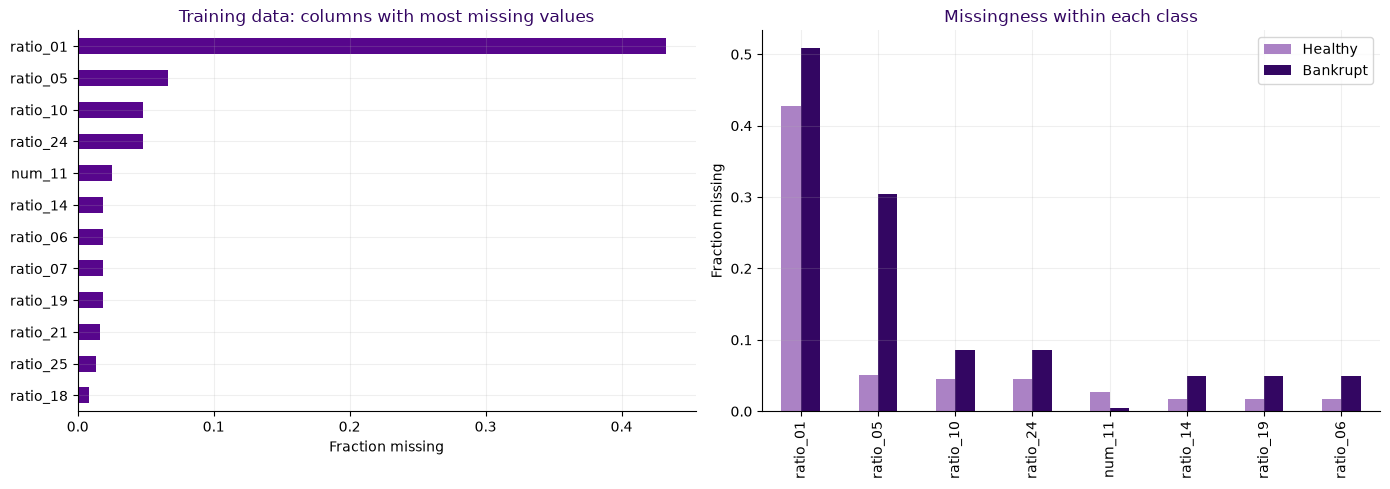

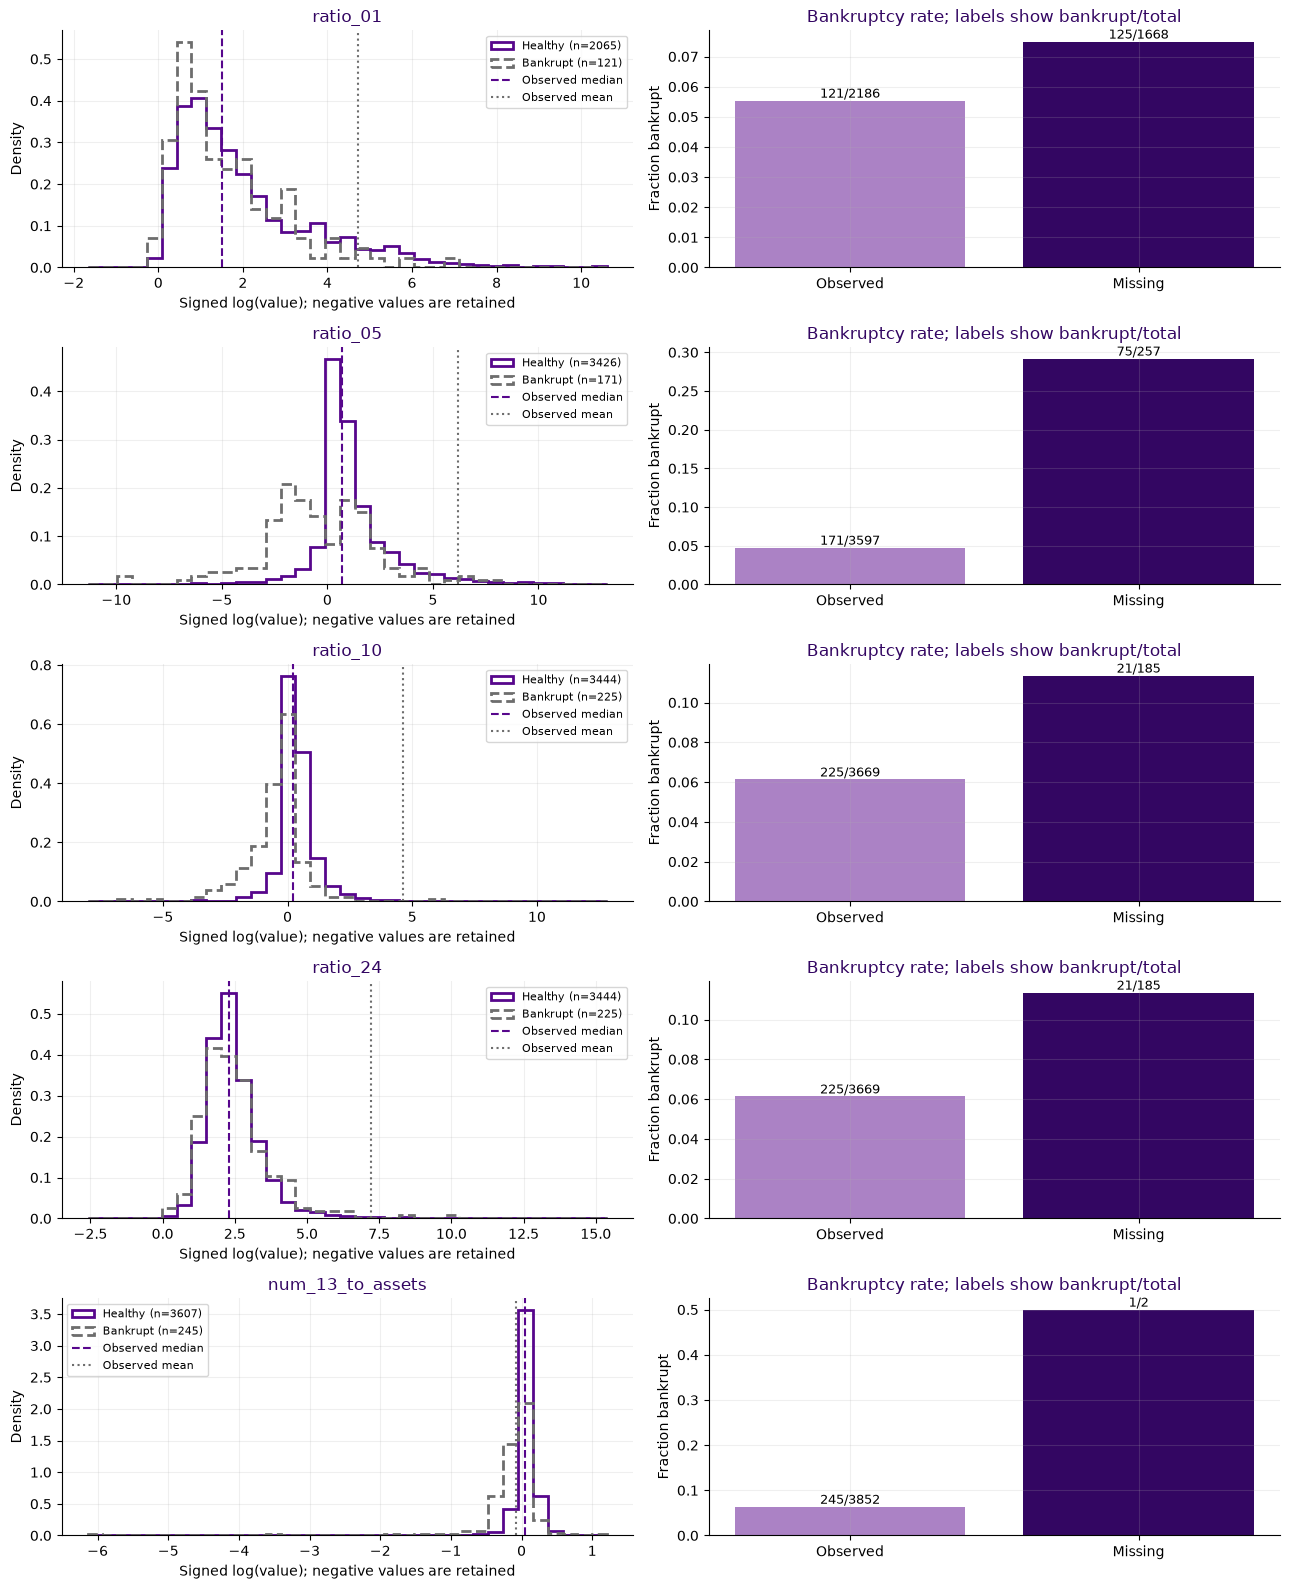

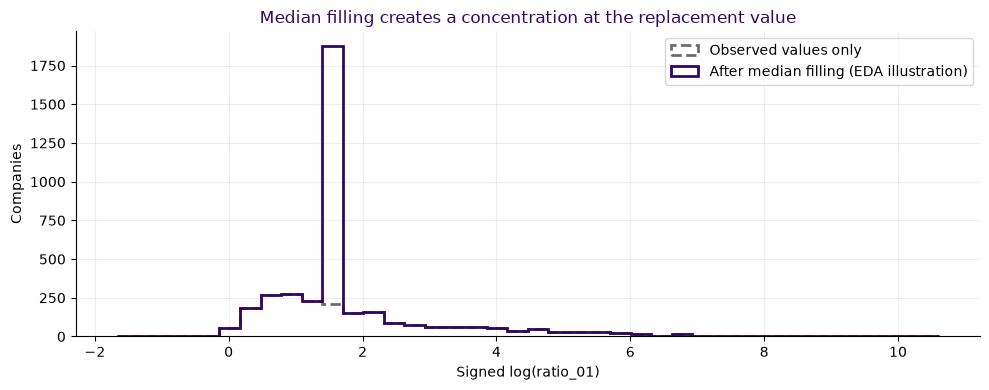

In [14]:
# Financial feature construction is row-wise; no imputer/filter is fitted for these plots.
raw_missing_review = X_train.drop(columns='Id').replace([np.inf, -np.inf], np.nan)
engineered_missing_review = FinancialFeatures('normalized').transform(X_train)
def describe_missing_values(frame):
    missing = frame.isna()
    observed = frame.notna()
    quantiles = frame.quantile([.01, .5, .99])
    rows = []
    target = np.asarray(y_train)
    for col in frame.columns:
        absent = missing[col].to_numpy()
        values = frame[col].dropna()
        rows.append(dict(Feature=col, Observed=len(values), Missing=int(absent.sum()),
            Missing_fraction=float(absent.mean()),
            Missing_healthy=float(absent[target == 0].mean()),
            Missing_bankrupt=float(absent[target == 1].mean()),
            Bankrupt_when_missing=int(target[absent].sum()),
            Rate_when_missing=float(target[absent].mean()) if absent.any() else np.nan,
            Rate_when_observed=float(target[~absent].mean()) if (~absent).any() else np.nan,
            Minimum=values.min(), P01=quantiles.loc[.01, col], Median=quantiles.loc[.5, col],
            Mean=values.mean(), P99=quantiles.loc[.99, col], Maximum=values.max(),
            Negative=int((values < 0).sum()), Zero=int((values == 0).sum())))
    return pd.DataFrame(rows).set_index('Feature').sort_values('Missing_fraction', ascending=False)
raw_missing_table = describe_missing_values(raw_missing_review)
engineered_missing_table = describe_missing_values(engineered_missing_review)
print('Raw financial columns: missingness and value ranges')
with pd.option_context('display.max_rows', 80, 'display.max_columns', 20):
    display(raw_missing_table)
print('Normalized/engineered columns: missingness and value ranges')
with pd.option_context('display.max_rows', 80, 'display.max_columns', 20):
    display(engineered_missing_table)
print('Rows missing total_assets:', int(raw_missing_review.total_assets.isna().sum()))
print('Rows with nonpositive total_assets:', int((raw_missing_review.total_assets <= 0).sum()))
print('Rows with zero sales:', int((raw_missing_review.sales == 0).sum()))
print('Rows with zero short-term liabilities:', int((raw_missing_review.short_term_liabilities == 0).sum()))
pattern_table = raw_missing_review.isna().apply(
    lambda row: ', '.join(row.index[row]) if row.any() else 'No missing values', axis=1
).value_counts().rename_axis('Missing columns').to_frame('Companies')
display(pattern_table.head(10))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
raw_missing_table.head(12).Missing_fraction.sort_values().plot.barh(ax=ax[0], color=NYU_PURPLE)
ax[0].set(title='Training data: columns with most missing values', xlabel='Fraction missing', ylabel='')
columns = raw_missing_table.head(8).index
raw_missing_table.loc[columns, ['Missing_healthy', 'Missing_bankrupt']].rename(
    columns={'Missing_healthy': 'Healthy', 'Missing_bankrupt': 'Bankrupt'}).plot.bar(
        ax=ax[1], color=[NYU_LIGHT_PURPLE, NYU_DARK_PURPLE])
ax[1].set(title='Missingness within each class', ylabel='Fraction missing', xlabel='')
plt.tight_layout(); plt.show()
# Top missing columns plus profit/assets: missingness and skew are different questions.
plot_features = list(engineered_missing_table.head(4).index)
if 'num_13_to_assets' not in plot_features: plot_features.append('num_13_to_assets')
fig, axes = plt.subplots(len(plot_features), 2, figsize=(13, 3.2*len(plot_features)), squeeze=False)
observed_plot_stats = []
for row, col in enumerate(plot_features):
    values = engineered_missing_review[col]
    observed = values.dropna()
    transformed = signed_log(observed.to_numpy())
    edges = np.histogram_bin_edges(transformed, bins=35)
    for label, color in [(0, NYU_PURPLE), (1, NYU_GRAY)]:
        subset = values[(y_train == label) & values.notna()]
        axes[row, 0].hist(signed_log(subset.to_numpy()), bins=edges, density=True, histtype='step', linewidth=2,
            linestyle='-' if label == 0 else '--', color=color, label=('Healthy' if label == 0 else 'Bankrupt') + f' (n={len(subset)})')
    axes[row, 0].axvline(signed_log(observed.median()), color=NYU_PURPLE, ls='--', label='Observed median')
    axes[row, 0].axvline(signed_log(observed.mean()), color=NYU_GRAY, ls=':', label='Observed mean')
    axes[row, 0].set(title=col, xlabel='Signed log(value); negative values are retained', ylabel='Density')
    axes[row, 0].legend(fontsize=8)
    absent = values.isna().to_numpy()
    groups = []
    for name, mask in [('Observed', ~absent), ('Missing', absent)]:
        count = int(mask.sum()); cases = int(np.asarray(y_train)[mask].sum())
        groups.append((name, count, cases, cases/count if count else np.nan))
    axes[row, 1].bar([g[0] for g in groups], [g[3] for g in groups], color=[NYU_LIGHT_PURPLE, NYU_DARK_PURPLE])
    for i, (_, count, cases, rate) in enumerate(groups):
        if count: axes[row, 1].text(i, rate, f'{cases}/{count}', ha='center', va='bottom', fontsize=9)
    axes[row, 1].set(title='Bankruptcy rate; labels show bankrupt/total', ylabel='Fraction bankrupt')
    observed_plot_stats.append(dict(Feature=col, Missing=int(absent.sum()),
        Median=float(observed.median()), Mean=float(observed.mean())))
plt.tight_layout(); plt.show()
# Illustration only: the statistics below must not be passed to CV model fits.
col = 'ratio_01'
observed = engineered_missing_review[col].dropna()
median_filled = engineered_missing_review[col].fillna(observed.median())
edges = np.histogram_bin_edges(signed_log(median_filled.to_numpy()), bins=40)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(signed_log(observed.to_numpy()), bins=edges, histtype='step', linewidth=2, linestyle='--', color=NYU_GRAY, label='Observed values only')
ax.hist(signed_log(median_filled.to_numpy()), bins=edges, histtype='step', linewidth=2,
    color=NYU_DARK_PURPLE, label='After median filling (EDA illustration)')
ax.set(title='Median filling creates a concentration at the replacement value',
    xlabel='Signed log(ratio_01)', ylabel='Companies')
ax.legend(); plt.tight_layout(); plt.show()

<a id="checking-missing-sales-growth"></a>

**Does missing sales growth carry useful information?**

`ratio_21` is sales this year divided by sales last year. Its blanks stand out in the table above, so I check the counts and whether the association appears in each of the grouped validation folds used for the later matched comparisons. I do not fit another model here.

Missing prior-year sales, an undefined denominator, or how the records were collected could explain this pattern. I do not have the prior-year sales or collection history needed to tell which explanation is right. The fold tables describe how this association varies within the same training population; they are not independent new evidence. Keeping duplicate profiles together helps with repeated records, but cannot rule out a data-collection artifact.

In [15]:
# Training labels only; reuse the two existing outer-fold arrangements.
ratio21_absent = X_train.ratio_21.replace([np.inf, -np.inf], np.nan).isna().to_numpy()
training_labels = np.asarray(y_train)
ratio21_groups = []
for name, mask in [('Missing', ratio21_absent), ('Observed', ~ratio21_absent)]:
    ratio21_groups.append({'ratio_21': name, 'Companies': int(mask.sum()),
        'Unique_profiles': int(np.unique(train_groups[mask]).size),
        'Bankrupt': int(training_labels[mask].sum()),
        'Bankruptcy_pct': 100 * training_labels[mask].mean()})
display(pd.DataFrame(ratio21_groups).set_index('ratio_21').round(2))
ratio21_fold_rows = []
for seed in (20261004, 20261011):
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for fold, (fit_rows, validation_rows) in enumerate(
            folds.split(X_train, y_train, groups=train_groups), 1):
        assert not set(train_groups[fit_rows]) & set(train_groups[validation_rows])
        absent = ratio21_absent[validation_rows]
        labels = training_labels[validation_rows]
        ratio21_fold_rows.append({'Arrangement': seed, 'Fold': fold,
            'Missing': int(absent.sum()), 'Bankrupt_missing': int(labels[absent].sum()),
            'Missing_bankruptcy_pct': 100 * labels[absent].mean() if absent.any() else np.nan,
            'Observed_bankruptcy_pct': 100 * labels[~absent].mean() if (~absent).any() else np.nan})
ratio21_fold_table = pd.DataFrame(ratio21_fold_rows)
display(ratio21_fold_table.round(2))
print('The association appears in every fold, but each missing group has only 10-16 rows.')
print('The second arrangement reuses the same companies; it does not double the evidence.')
print('I keep the existing missingness flags. This check does not establish the cause or guarantee portability.')


,Companies,Unique_profiles,Bankrupt,Bankruptcy_pct
ratio_21,,,,
Missing,63,63,59,93.65
Observed,3791,3759,187,4.93


,Arrangement,Fold,Missing,Bankrupt_missing,Missing_bankruptcy_pct,Observed_bankruptcy_pct
0,20261004,1,13,13,100,4.75
1,20261004,2,13,12,92.31,4.88
2,20261004,3,11,11,100,5.13
3,20261004,4,12,10,83.33,5.14
4,20261004,5,14,13,92.86,4.76
5,20261011,1,15,14,93.33,4.63
6,20261011,2,16,16,100,4.37
7,20261011,3,10,8,80,5.52
8,20261011,4,11,10,90.91,5.13
9,20261011,5,11,11,100,5.01


The association appears in every fold, but each missing group has only 10-16 rows.
The second arrangement reuses the same companies; it does not double the evidence.
I keep the existing missingness flags. This check does not establish the cause or guarantee portability.


In [16]:
inventory_zero = X_train.num_10.eq(0)
inventory_denominator_check = pd.DataFrame({
    'Missing_rows': [int(X_train[col].isna().sum()) for col in ['ratio_10', 'ratio_24']],
    'Missing_with_zero_inventory': [int((X_train[col].isna() & inventory_zero).sum())
        for col in ['ratio_10', 'ratio_24']],
    'Observed_with_zero_inventory': [int((X_train[col].notna() & inventory_zero).sum())
        for col in ['ratio_10', 'ratio_24']]
}, index=['ratio_10', 'ratio_24'])
display(inventory_denominator_check)
print('Companies with zero inventory:', int(inventory_zero.sum()))
print('Both ratios have identical missingness:', X_train.ratio_10.isna().equals(X_train.ratio_24.isna()))


,Missing_rows,Missing_with_zero_inventory,Observed_with_zero_inventory
ratio_10,185,185,0
ratio_24,185,185,0


Companies with zero inventory: 185
Both ratios have identical missingness: True


All 185 missing values in `ratio_10` and all 185 in `ratio_24` occur where inventory is zero. Their listed formulas divide by inventory, so a finite ratio is undefined in those cases. A filled number is just something the model can use; it is not the company's true ratio. A missingness flag records that distinction.

I cannot explain every blank this way. The denominator of `ratio_05` cannot be fully reconstructed from the supplied columns. Also, profit/assets is missing for just two companies, one bankrupt: the plotted 50% bankruptcy rate is one case out of two, not a reliable pattern.

`ratio_01` is missing for 1,668 training companies (43.3%). Its observed median is 3.52, but its mean is 111.21 and its maximum is 40,559. For `ratio_05`, the median is 1.01 and the mean is 481.82. The very large values pull the means far from a typical company, which gives me a reason to compare medians with means.

The blanks may also contain information. `ratio_05` is missing for 30.5% of bankrupt companies and 5.0% of healthy companies. Among the 257 companies missing it, 75 went bankrupt (29.2%); the rate is 4.8% when it is observed. I therefore want to keep a flag that says the value was missing. Counts are shown alongside rates so I do not overinterpret a tiny group.

The filled histogram shows another issue: median filling puts many companies at exactly the same value. That is useful for making an input usable, but it does not recreate the original distribution or tell me why the values were absent.

<a id="can-other-columns-explain-the-blanks"></a>

## Can other columns explain the blanks?

I separate three possibilities: an undefined ratio, a missing number that an accounting identity can recover, and a number I can only estimate. Regression cannot recover a finite true value for an undefined ratio.

I first check each proposed formula against observed training values, allowing relative and absolute differences of 0.001 for rounding. Then I count actual missing entries with the needed inputs available. A close match on observed rows is not enough if the inputs are also missing wherever I need them. A correlation is a reason to try an estimate, not an accounting identity.

,Formula,Observed_pairs,Match_fraction,Missing,Available_formula_candidates
Column,,,,,
ratio_02,log(total assets),3852,1,2,0
total_assets,exp(ratio_02),3852,1,2,0
ratio_15,assets / liabilities,3844,0.99974,9,0
ratio_16,sales / assets,3852,1,0,0
num_19,current assets - short liabilities,3844,0.998439,2,0
ratio_01,(current assets - inventory) / (total - short liabilities): proxy denominator,2186,0.177036,1668,643
ratio_04,(total - short liabilities) / equity: proxy numerator,3851,0.632303,2,0
ratio_10,net profit / inventory,3667,0.617944,185,0
ratio_24,sales / converted inventory,3667,0.999455,185,0


,Denominator,Missing,Missing_with_zero_denominator,Missing_with_absent_denominator,Other_missing
Column,,,,,
ratio_10,num_10,185,185,0,0
ratio_24,num_10,185,185,0,0
ratio_15,total_liabilities,9,8,1,0
ratio_04,num_14,2,1,1,0
ratio_16,total_assets,0,0,0,0


Companies missing every supplied financial amount: 2
Missing three-year gross profit with current net profit available: 94


,Target,Predictor,Spearman,Observed_pairs,Predictor_available_when_target_missing
0,ratio_01,ratio_04,-0.725896,2186,1666
1,ratio_01,ratio_06,0.605737,2179,1603
2,ratio_01,ratio_07,0.425498,2179,1603
3,ratio_01,num_32,0.412824,2185,1658
4,ratio_01,ratio_15,0.394655,2186,1659
5,ratio_05,num_24,0.690182,3596,256
6,ratio_05,num_04,0.686759,3596,256
7,ratio_05,num_02,0.652673,3596,256
8,ratio_05,ratio_10,0.638433,3448,221
9,ratio_05,num_09,0.618214,3596,256


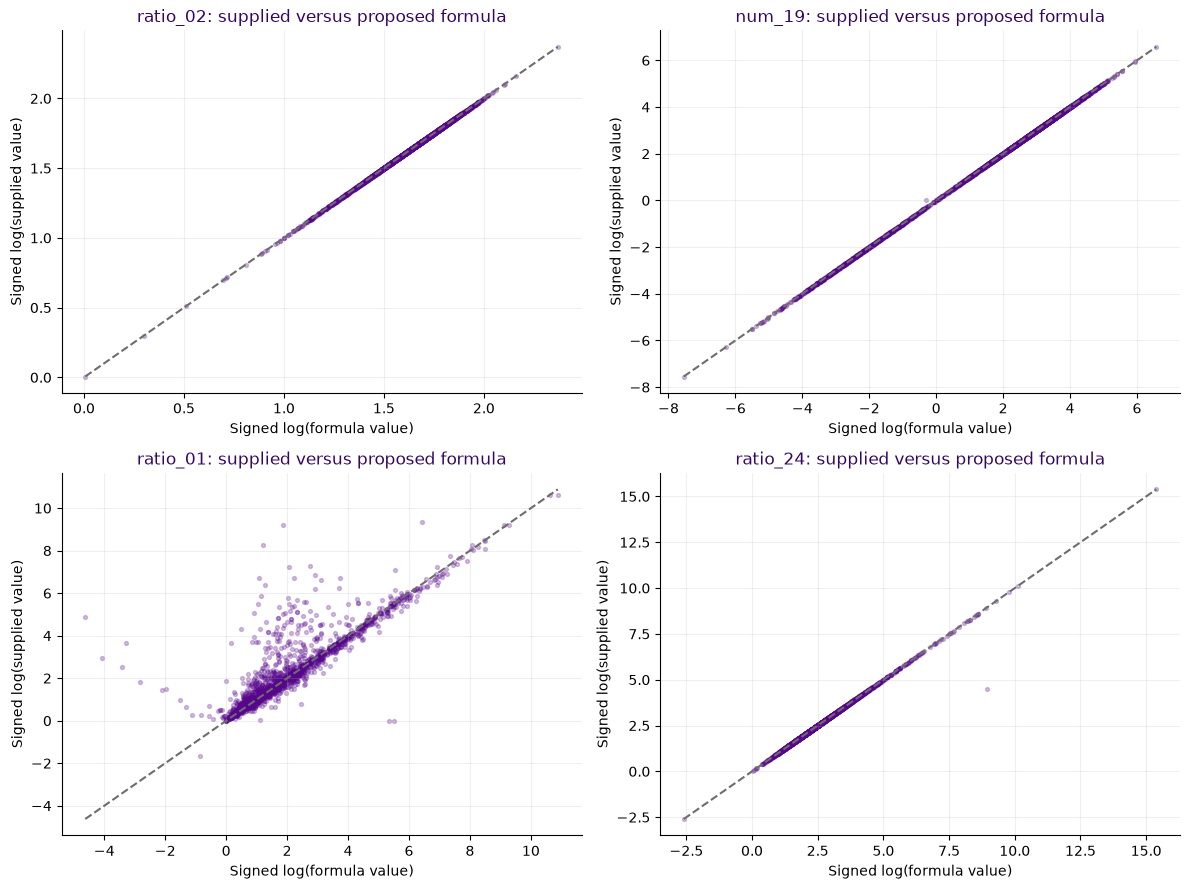

In [17]:
def audit_divide(a, b):
    return (a / b.where(b.abs() > 1e-8)).replace([np.inf, -np.inf], np.nan)
a = X_train.copy()
a[['num_10', 'num_27']] = a[['num_10', 'num_27']] / 365
formula_candidates = {
    'ratio_02': np.log(a.total_assets.where(a.total_assets > 0)),
    'total_assets': np.exp(a.ratio_02),
    'ratio_15': audit_divide(a.total_assets, a.total_liabilities),
    'ratio_16': audit_divide(a.sales, a.total_assets),
    'num_19': a.num_06 - a.short_term_liabilities,
    'ratio_01': audit_divide(a.num_06-a.num_10, a.total_liabilities-a.short_term_liabilities),
    'ratio_04': audit_divide(a.total_liabilities-a.short_term_liabilities, a.num_14),
    'ratio_10': audit_divide(a.num_13, a.num_10),
    'ratio_24': audit_divide(a.sales, a.num_10),
    'ratio_17': audit_divide(a.sales, a.num_27)}
formula_descriptions = {
    'ratio_02': 'log(total assets)', 'total_assets': 'exp(ratio_02)',
    'ratio_15': 'assets / liabilities', 'ratio_16': 'sales / assets',
    'num_19': 'current assets - short liabilities',
    'ratio_01': '(current assets - inventory) / (total - short liabilities): proxy denominator',
    'ratio_04': '(total - short liabilities) / equity: proxy numerator',
    'ratio_10': 'net profit / inventory', 'ratio_24': 'sales / converted inventory',
    'ratio_17': 'sales / converted receivables'}
formula_rows = []
for col, predicted in formula_candidates.items():
    usable = predicted.notna() & np.isfinite(predicted)
    observed_pairs = a[col].notna() & usable
    matches = np.isclose(a.loc[observed_pairs, col], predicted.loc[observed_pairs], rtol=.001, atol=.001)
    recoverable = a[col].isna() & usable
    formula_rows.append(dict(Column=col, Formula=formula_descriptions[col],
        Observed_pairs=int(observed_pairs.sum()), Match_fraction=float(matches.mean()),
        Missing=int(a[col].isna().sum()), Available_formula_candidates=int(recoverable.sum())))
formula_recovery_table = pd.DataFrame(formula_rows).set_index('Column')
display(formula_recovery_table)
explanation_rows = []
for col, denominator in [('ratio_10', 'num_10'), ('ratio_24', 'num_10'),
    ('ratio_15', 'total_liabilities'), ('ratio_04', 'num_14'), ('ratio_16', 'total_assets')]:
    missing = a[col].isna()
    zero = a[denominator].eq(0)
    absent = a[denominator].isna()
    explanation_rows.append(dict(Column=col, Denominator=denominator, Missing=int(missing.sum()),
        Missing_with_zero_denominator=int((missing & zero).sum()),
        Missing_with_absent_denominator=int((missing & absent).sum()),
        Other_missing=int((missing & ~(zero | absent)).sum())))
missing_explanation_table = pd.DataFrame(explanation_rows).set_index('Column')
display(missing_explanation_table)
financial_amounts = [c for c in a.columns if c.startswith('num_')] + [
    'total_assets', 'sales', 'total_liabilities', 'short_term_liabilities']
print('Companies missing every supplied financial amount:', int(a[financial_amounts].isna().all(axis=1).sum()))
print('Missing three-year gross profit with current net profit available:',
    int((a.num_11.isna() & a.num_13.notna()).sum()))
raw_financial = a.drop(columns='Id')
relationship_rows = []
for col in ['ratio_01', 'ratio_05', 'num_11']:
    relationships = raw_financial.corrwith(raw_financial[col], method='spearman').drop(col).dropna()
    for predictor in relationships.abs().nlargest(5).index:
        relationship_rows.append(dict(Target=col, Predictor=predictor,
            Spearman=float(relationships[predictor]),
            Observed_pairs=int((a[col].notna() & a[predictor].notna()).sum()),
            Predictor_available_when_target_missing=int((a[col].isna() & a[predictor].notna()).sum())))
relationship_table = pd.DataFrame(relationship_rows)
display(relationship_table)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), ['ratio_02', 'num_19', 'ratio_01', 'ratio_24']):
    predicted = formula_candidates[col]
    usable = a[col].notna() & predicted.notna() & np.isfinite(predicted)
    x_plot, y_plot = signed_log(predicted[usable]), signed_log(a.loc[usable, col])
    ax.scatter(x_plot, y_plot, s=8, alpha=.25, color=NYU_PURPLE)
    lo, hi = min(x_plot.min(), y_plot.min()), max(x_plot.max(), y_plot.max())
    ax.plot([lo, hi], [lo, hi], '--', color=NYU_GRAY)
    ax.set(title=col + ': supplied versus proposed formula',
        xlabel='Signed log(formula value)', ylabel='Signed log(supplied value)')
plt.tight_layout(); plt.show()

The formula checks distinguish recoverable amounts from undefined ratios. Converting inventory by 365 makes the sales/inventory relationship agree closely with the supplied turnover ratio. However, where inventory is zero the turnover is still undefined: conversion cannot turn those blanks into real measurements. The profit/inventory and long-term-debt proxies need separate checks because their stated financial definitions may differ from the available amounts.

The model representations also recalculate six columns from the stated formulas. Where the earlier audit finds disagreement, these are alternative financial features rather than exact recovery of the supplied values. For other blanks, I compare median filling, missingness flags and estimates from other columns below. A correlation by itself does not justify treating an estimate as an observed financial value.


<a id="comparing-ways-to-fill-missing-values"></a>

## Comparing ways to fill missing values

I compare median filling with and without flags, mean filling with flags, and boosting's native missing-value handling with and without flags. I keep incomplete companies: missing debt or profit is different from a real zero.

For a fair comparison, I use the same features, five grouped training folds and a fixed boosting reference: seven leaves, 150 iterations and cutoff 1/6. I use this fixed reference to isolate the filling method, before comparing classifier families. Each fold learns its own filter, replacements and flags. The median-filled EDA table never enters model fitting.

I compare total cost and paired fold results. A plausible-looking filled value is useful only if it also supports better bankruptcy predictions.

In [18]:
# Fixed reference for the later missing-value studies; no model is selected here.
IMPUTATION_REFERENCE_PARAMS = dict(max_iter=150, max_leaf_nodes=7,
    learning_rate=.1, l2_regularization=1, min_samples_leaf=20,
    early_stopping=False, random_state=42)
outer_groups = profile_groups(X_train)
outer_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
    random_state=20261004).split(X_train, y_train, groups=outer_groups))
for fit_idx, val_idx in outer_folds:
    assert not set(outer_groups[fit_idx]) & set(outer_groups[val_idx])
print('Missing-value comparison: five grouped training folds; classifier settings fixed.')

Missing-value comparison: five grouped training folds; classifier settings fixed.


Completed: Median + flags


Completed: Median without flags


Completed: Mean + flags


Completed: Native missing + flags


Completed: Native missing without flags


,Cost,FN,FP,Recall,Precision,AP,Brier
Median + flags,468,74,98,0.699187,0.637037,0.761423,0.0280221
Median without flags,517,82,107,0.666667,0.605166,0.723966,0.0309066
Mean + flags,478,76,98,0.691057,0.634328,0.760373,0.0277984
Native missing + flags,484,76,104,0.691057,0.620438,0.743358,0.0290788
Native missing without flags,484,76,104,0.691057,0.620438,0.743358,0.0290788


Approach,Mean + flags,Median + flags,Median without flags,Native missing + flags,Native missing without flags
Fold,,,,,
1,67,66,56,69,69
2,104,100,101,101,101
3,101,109,115,107,107
4,111,93,132,103,103
5,95,100,113,104,104


Cost saved relative to median + flags (positive is better):


Approach,Mean + flags,Median + flags,Median without flags,Native missing + flags,Native missing without flags
Fold,,,,,
1,-1,0,10,-3,-3
2,-4,0,-1,-1,-1
3,8,0,-6,2,2
4,-18,0,-39,-10,-10
5,5,0,-13,-4,-4


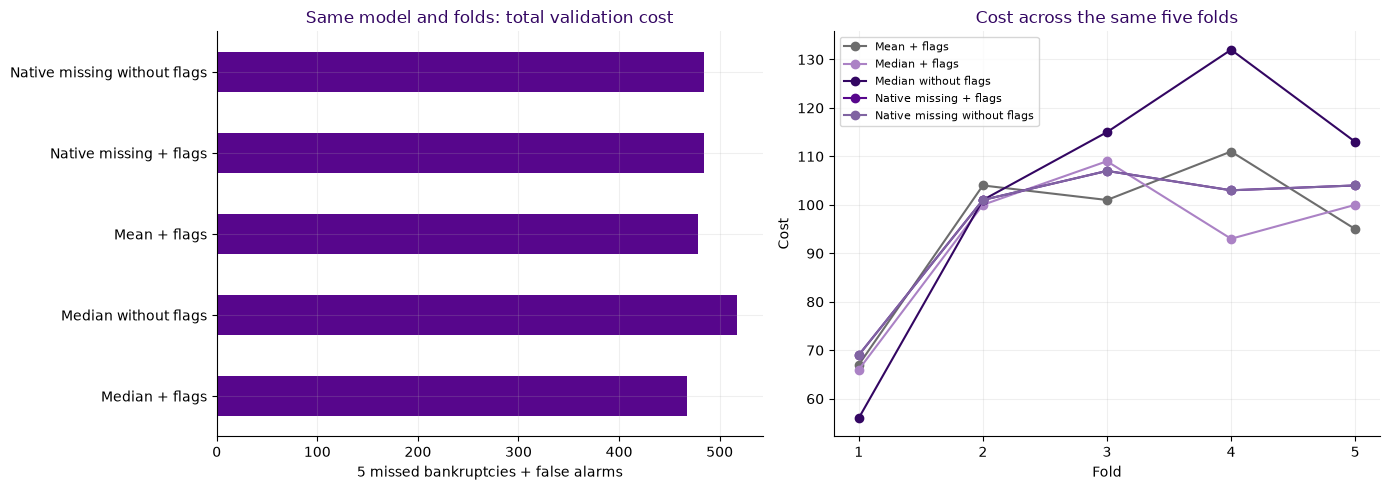

This imputation comparison uses training validation only; the final feature comparison comes later.


In [19]:
from threadpoolctl import threadpool_limits

class NativeMissingFlags(TransformerMixin, BaseEstimator):
    def __init__(self, add_indicator=True): self.add_indicator = add_indicator
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        self.missing_columns_ = np.flatnonzero(X.isna().any(axis=0).to_numpy())
        return self
    def transform(self, X):
        values = X.to_numpy(dtype=float)
        if self.add_indicator:
            flags = np.isnan(values[:, self.missing_columns_]).astype(float)
            return np.column_stack([values, flags])
        return values

imputation_approaches = [('Median + flags', 'median', True), ('Median without flags', 'median', False),
    ('Mean + flags', 'mean', True), ('Native missing + flags', 'native', True),
    ('Native missing without flags', 'native', False)]
def make_imputation_comparison(strategy, add_flags):
    missing_step = (NativeMissingFlags(add_indicator=add_flags) if strategy == 'native' else
        SimpleImputer(strategy=strategy, add_indicator=add_flags, keep_empty_features=True))
    return Pipeline([('features', FinancialFeatures('normalized')),
        ('correlations', CorrelationFilter(limit=.995)), ('missing', missing_step),
        ('signed_log', FunctionTransformer(signed_log)),
        ('classifier', HistGradientBoostingClassifier(**IMPUTATION_REFERENCE_PARAMS))])
imputation_fold_rows = []
imputation_probabilities = {}
imputation_predictions = {}
with threadpool_limits(limits=1):
    for name, strategy, flags in imputation_approaches:
        probabilities = np.empty(len(y_train))
        for fold_number, (fit_idx, val_idx) in enumerate(outer_folds, 1):
            assert not set(outer_groups[fit_idx]) & set(outer_groups[val_idx])
            model = make_imputation_comparison(strategy, flags).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            p = model.predict_proba(X_train.iloc[val_idx])[:, 1]
            probabilities[val_idx] = p
            metrics = metric_row(y_train.iloc[val_idx], (p >= 1/6).astype(int), p)
            metrics.update(Approach=name, Fold=fold_number)
            imputation_fold_rows.append(metrics)
        imputation_probabilities[name] = probabilities
        imputation_predictions[name] = (probabilities >= 1/6).astype(int)
        print('Completed:', name, flush=True)
imputation_summary = pd.DataFrame({name: metric_row(y_train, imputation_predictions[name], p)
    for name, p in imputation_probabilities.items()}).T
display(imputation_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
imputation_fold_table = pd.DataFrame(imputation_fold_rows)
imputation_paired_costs = imputation_fold_table.pivot(index='Fold', columns='Approach', values='Cost')
display(imputation_paired_costs)
imputation_cost_saved = imputation_paired_costs.rsub(imputation_paired_costs['Median + flags'], axis=0)
print('Cost saved relative to median + flags (positive is better):')
display(imputation_cost_saved)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imputation_summary.Cost.plot.barh(ax=ax[0], color=NYU_PURPLE)
ax[0].set(title='Same model and folds: total validation cost', xlabel='5 missed bankruptcies + false alarms', ylabel='')
imputation_paired_costs.plot(ax=ax[1], marker='o',
    color=[NYU_GRAY, NYU_LIGHT_PURPLE, NYU_DARK_PURPLE, NYU_PURPLE, '#8064A2'])
ax[1].set(title='Cost across the same five folds', xlabel='Fold', ylabel='Cost', xticks=range(1, 6))
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('This imputation comparison uses training validation only; the final feature comparison comes later.')

Median filling with flags costs 468, compared with 517 without flags, 478 with mean filling, and 484 with native missing-value handling. The median is a reasonable reference for these skewed inputs, and the flags preserve the difference between a missing value and a real value near the median. This comparison supports the choice for this model; it does not prove median filling is best for every column or model.


<a id="estimating-missing-values-from-other-columns"></a>

### Estimating missing values from other columns

I use Bayesian ridge regression inside [IterativeImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html) to estimate incomplete features from other financial columns. It starts with medians and updates the estimates for up to 20 rounds, using at most 15 predictors and a fixed seed. Id and the bankruptcy label are excluded.

Signed logs and robust scaling handle the different ranges. Both are fitted within each fitting fold and reversed after estimation; only missing entries are replaced. Estimates are limited to that fold's observed range, although future real values could fall outside it.

Classifier settings, features, flags, folds and cutoff match the median comparison. I change the imputer alone, then check whether the estimated values and bankruptcy decisions improve.

In [20]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from threadpoolctl import threadpool_limits
from sklearn.exceptions import ConvergenceWarning

class FinancialRegressionImputer(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        self.missing_columns_ = np.flatnonzero(X.isna().any(axis=0).to_numpy())
        values = signed_log(X.to_numpy(dtype=float))
        self.scale_ = RobustScaler().fit(values)
        scaled = self.scale_.transform(values)
        self.imputer_ = IterativeImputer(estimator=BayesianRidge(), initial_strategy='median',
            max_iter=20, tol=.001, n_nearest_features=min(15, X.shape[1]-1),
            skip_complete=True, random_state=20261010, sample_posterior=False,
            min_value=np.nanmin(scaled, axis=0), max_value=np.nanmax(scaled, axis=0),
            keep_empty_features=True)
        self.imputer_.fit(scaled)
        self.n_iter_ = self.imputer_.n_iter_
        return self
    def transform(self, X):
        raw = X.to_numpy(dtype=float)
        missing = np.isnan(raw)
        scaled = self.scale_.transform(signed_log(raw))
        estimated_log = self.scale_.inverse_transform(self.imputer_.transform(scaled))
        estimates = np.sign(estimated_log) * np.expm1(np.abs(estimated_log))
        output = raw.copy()
        output[missing] = estimates[missing]
        flags = missing[:, self.missing_columns_].astype(float)
        return np.column_stack([output, flags])

def make_relationship_imputation_model(kind):
    imputer = (SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)
        if kind == 'median' else FinancialRegressionImputer())
    return Pipeline([('features', FinancialFeatures('normalized')),
        ('correlations', CorrelationFilter(.995)), ('missing', imputer),
        ('signed_log', FunctionTransformer(signed_log)),
        ('classifier', HistGradientBoostingClassifier(**IMPUTATION_REFERENCE_PARAMS))])
regression_imputation_probabilities = {}
regression_imputation_fold_rows = []
regression_imputation_iterations = []
regression_imputation_models = {}
with threadpool_limits(limits=1):
    for name, kind in [('Median + flags', 'median'), ('Regression estimates + flags', 'regression')]:
        p_all = np.empty(len(y_train))
        for fold_number, (fit_idx, val_idx) in enumerate(outer_folds, 1):
            assert not set(outer_groups[fit_idx]) & set(outer_groups[val_idx])
            model = make_relationship_imputation_model(kind)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always', ConvergenceWarning)
                model.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            if kind == 'regression':
                regression_imputation_iterations.append(dict(Fold=fold_number,
                    Iterations=model.named_steps['missing'].n_iter_,
                    Convergence_warnings=sum(issubclass(w.category, ConvergenceWarning) for w in caught)))
            p = model.predict_proba(X_train.iloc[val_idx])[:, 1]
            p_all[val_idx] = p
            row = metric_row(y_train.iloc[val_idx], (p >= 1/6).astype(int), p)
            row.update(Approach=name, Fold=fold_number)
            regression_imputation_fold_rows.append(row)
            regression_imputation_models[(name, fold_number)] = model
            print(name, 'fold', fold_number, 'complete', flush=True)
        regression_imputation_probabilities[name] = p_all
regression_imputation_summary = pd.DataFrame({name: metric_row(y_train,
    (p >= 1/6).astype(int), p) for name, p in regression_imputation_probabilities.items()}).T
display(regression_imputation_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
regression_imputation_fold_table = pd.DataFrame(regression_imputation_fold_rows)
display(regression_imputation_fold_table[['Fold', 'Approach', 'Cost', 'FN', 'FP', 'AP', 'Brier']])
display(pd.DataFrame(regression_imputation_iterations))
print('This regression-imputation experiment uses training folds only; it does not evaluate the test or holdout.')

Median + flags fold 1 complete


Median + flags fold 2 complete


Median + flags fold 3 complete


Median + flags fold 4 complete


Median + flags fold 5 complete


Regression estimates + flags fold 1 complete


... (4 outputs left out)

,Cost,FN,FP,Recall,Precision,AP,Brier
Median + flags,468,74,98,0.699187,0.637037,0.761423,0.0280221
Regression estimates + flags,458,72,98,0.707317,0.639706,0.76286,0.0276609


,Fold,Approach,Cost,FN,FP,AP,Brier
0,1,Median + flags,66,10,16,0.845776,0.0219734
1,2,Median + flags,100,15,25,0.733954,0.0284892
2,3,Median + flags,109,18,19,0.767771,0.0299889
3,4,Median + flags,93,16,13,0.731408,0.0307449
4,5,Median + flags,100,15,25,0.741643,0.0289152
5,1,Regression estimates + flags,66,9,21,0.86925,0.0201742
6,2,Regression estimates + flags,104,17,19,0.731994,0.0285417
7,3,Regression estimates + flags,98,16,18,0.777229,0.029641
8,4,Regression estimates + flags,106,18,16,0.712812,0.0311865
9,5,Regression estimates + flags,84,12,24,0.741193,0.0287624


,Fold,Iterations,Convergence_warnings
0,1,20,1
1,2,20,1
2,3,20,1
3,4,20,1
4,5,20,1


This regression-imputation experiment uses training folds only; it does not evaluate the test or holdout.


<a id="checking-estimates-by-hiding-known-values"></a>

### Checking estimates by hiding known values

I also want to know whether the filled financial values are plausible. I randomly hide 20% of the observed validation entries in `ratio_01`, `ratio_05`, and three-year profit/assets, one column at a time. Both fitted imputers see the same blanks. I keep the real values aside so I can measure their errors without fitting on the validation rows.

I show errors in the original units and on the signed-log scale, where extreme values have less influence. This tests one missing feature at a time, not a whole missing block of raw amounts. Real blanks may differ from observed values, so this is a useful check rather than proof that every naturally missing value is estimated accurately.

Hidden_values     Raw_MAE  Raw_median_error  Signed_log_MAE
Column           Approach                                                                                 
num_11_to_assets Median + flags                          601    0.284772          0.168067        0.209722
                 Regression estimates + flags            601    0.148723          0.082244        0.106541
ratio_01         Median + flags                          436   63.294979          2.720205        1.098107
                 Regression estimates + flags            436   61.475293          4.150903        0.857855
ratio_05         Median + flags                          716  581.134360          1.093838        1.328399
                 Regression estimates + flags            716  583.069164          1.567146        0.965181

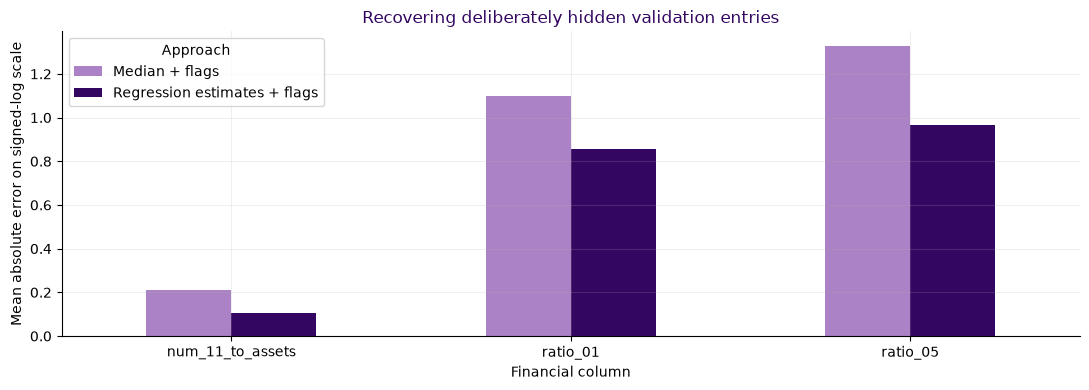

In [21]:
masked_imputation_errors = []
for fold_number, (fit_idx, val_idx) in enumerate(outer_folds, 1):
    reference_model = regression_imputation_models[('Median + flags', fold_number)]
    reference_features = reference_model.named_steps['correlations'].transform(
        reference_model.named_steps['features'].transform(X_train.iloc[val_idx]))
    for target_number, col in enumerate(['ratio_01', 'ratio_05', 'num_11_to_assets']):
        if col not in reference_features.columns: continue
        available = np.flatnonzero(reference_features[col].notna().to_numpy())
        rng = np.random.default_rng(20261010 + 10*fold_number + target_number)
        hidden = rng.choice(available, size=max(1, int(.2*len(available))), replace=False)
        truth = reference_features[col].iloc[hidden].to_numpy()
        masked = reference_features.copy()
        masked.iloc[hidden, masked.columns.get_loc(col)] = np.nan
        for name in ['Median + flags', 'Regression estimates + flags']:
            model = regression_imputation_models[(name, fold_number)]
            own_features = model.named_steps['correlations'].transform(
                model.named_steps['features'].transform(X_train.iloc[val_idx]))
            assert list(own_features.columns) == list(reference_features.columns)
            imputed = model.named_steps['missing'].transform(masked)
            estimate = imputed[hidden, masked.columns.get_loc(col)]
            for actual, predicted in zip(truth, estimate):
                masked_imputation_errors.append(dict(Column=col, Approach=name, Fold=fold_number,
                    Absolute_error=float(abs(actual-predicted)),
                    Signed_log_absolute_error=float(abs(signed_log(actual)-signed_log(predicted)))))
masked_imputation_table = pd.DataFrame(masked_imputation_errors).groupby(
    ['Column', 'Approach']).agg(Hidden_values=('Absolute_error', 'size'),
    Raw_MAE=('Absolute_error', 'mean'), Raw_median_error=('Absolute_error', 'median'),
    Signed_log_MAE=('Signed_log_absolute_error', 'mean'))
display(masked_imputation_table)
fig, ax = plt.subplots(figsize=(11, 4))
masked_imputation_table.Signed_log_MAE.unstack().plot.bar(ax=ax,
    color=[NYU_LIGHT_PURPLE, NYU_DARK_PURPLE])
ax.set(title='Recovering deliberately hidden validation entries',
    ylabel='Mean absolute error on signed-log scale', xlabel='Financial column')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

Regression filling reduces cost from 468 to 458, about 2.1%, by missing two fewer bankruptcies with the same number of false alarms. It improves two folds, worsens two and ties one. All five imputers reach the 20-round limit with a convergence warning, so I do not treat this small gain as a settled result.

The masked-value check shows a clearer benefit for three-year profit/assets, while the median absolute errors for `ratio_01` and `ratio_05` increase. Estimating an individual column more accurately and making better bankruptcy decisions are different goals. I retain median filling with flags as the simpler reference for the feature comparisons and keep this mixed result in the notebook.


<a id="predicting-missing-sales-growth"></a>

### Predicting missing sales growth

I estimate `ratio_21` from the other financial columns with one fixed random-forest regressor: 150 trees, maximum depth 10 and minimum leaf size 10. The target uses a signed log to limit the influence of extreme growth values. Neither Id nor Bankruptcy enters the regression; observed values stay unchanged.

In each of the two existing five-fold grouped arrangements, the regression trains on observed sales growth in the fitting rows. I hide all known validation values and compare their estimates with the fitting-fold median, reporting raw and signed-log errors and R-squared. The two arrangements reuse the same companies.

I set the checks before seeing the results. Reconstruction must reduce signed-log mean absolute error by at least 5%, have positive signed-log R-squared, and improve at least three folds per arrangement. I then rerun the bankruptcy classifier with only this fill method changed, retaining all missingness flags, the six-feature bundle, classifier settings and cutoff 0.08. I use a fixed reference classifier with the liquidity features defined above; their later feature comparison is a separate question. Selecting the regression fill would also require lower cost in both arrangements and at least six paired fold wins out of ten.

These are additional checks on explored training folds. Known-value reconstruction cannot verify the true values of genuine blanks, and I do not use test or holdout outcomes to choose the imputer.

ratio_21 comparison: arrangement 20261004, fold 1/5 complete


ratio_21 comparison: arrangement 20261004, fold 2/5 complete


ratio_21 comparison: arrangement 20261004, fold 3/5 complete


ratio_21 comparison: arrangement 20261004, fold 4/5 complete


ratio_21 comparison: arrangement 20261004, fold 5/5 complete


ratio_21 comparison: arrangement 20261011, fold 1/5 complete


... (7 outputs left out)

Approach       Median + flags  Predicted ratio_21 + flags
Seed     Fold                                            
20261004 1                 64                          68
         2                 89                          96
         3                 66                          74
         4                101                          83
         5                 88                          90
20261011 1                123                         119
         2                 99                          95
         3                 84                          86
         4                 63                          68
         5                 89                          85

Cost  FN   FP  Recall  Precision      AP   Brier
Seed     Approach                                                                    
20261004 Median + flags               408  46  178  0.8130     0.5291  0.7799  0.0266
         Predicted ratio_21 + flags   411  47  176  0.8089     0.5307  0.7728  0.0270
20261011 Median + flags               458  55  183  0.7764     0.5107  0.7632  0.0275
         Predicted ratio_21 + flags   453  54  183  0.7805     0.5120  0.7575  0.0281

Passes the reconstruction checks: True
Bankruptcy cost wins: 4 of 10
Use model-estimated ratio_21 in the final pipeline: False
Estimates for genuinely missing training values (out-of-fold):


,count,mean,std,min,25%,50%,75%,max
Seed,,,,,,,,
20261004,63,0.998,0.252,-0.002,0.868,1.003,1.143,1.439
20261011,63,0.983,0.263,-0.021,0.869,0.992,1.113,1.432


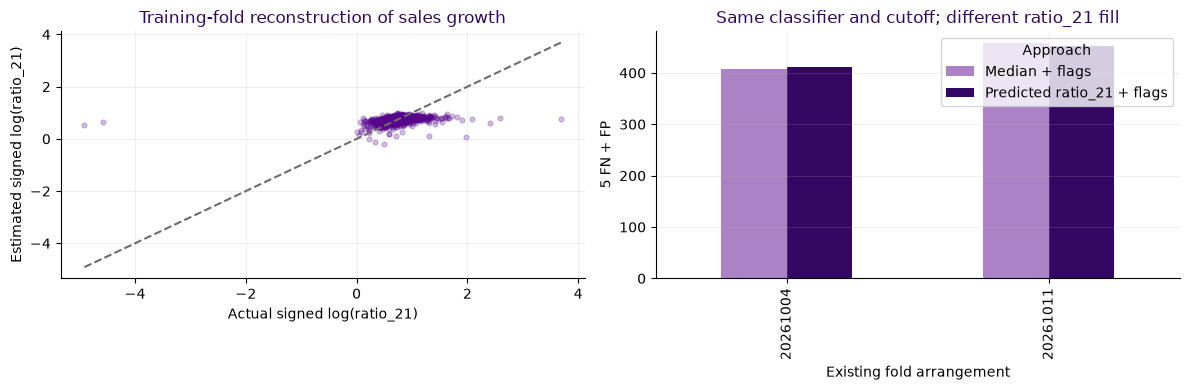

In [22]:
# Fixed targeted experiment, before any new test/holdout evaluation.
RATIO21_REFERENCE_PARAMS=dict(max_iter=150, max_leaf_nodes=7, min_samples_leaf=20,
    learning_rate=.1, l2_regularization=1, early_stopping=False, random_state=42)
RATIO21_REFERENCE_CUTOFF=.08
ratio21_predict_groups=profile_groups(X_train)
ratio21_reconstruction_rows=[]
ratio21_bankruptcy_rows=[]
ratio21_reconstruction_values=[]
ratio21_real_missing_estimates=[]
ratio21_oof_probabilities={}

def ratio21_comparison_model(use_regression):
    model=make_model('HistGradientBoostingClassifier', 'normalized', False,
        **RATIO21_REFERENCE_PARAMS)
    model.set_params(features=LiquidityQualityFeatures(mode='normalized'))
    if use_regression:
        model.set_params(imputer=Ratio21RegressionImputer())
    return model

for split_seed in (20261004,20261011):
    folds=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=split_seed)
        .split(X_train,y_train,groups=ratio21_predict_groups))
    for approach in ['Median + flags','Predicted ratio_21 + flags']:
        ratio21_oof_probabilities[(split_seed,approach)]=np.empty(len(y_train))
    for fold,(fit_idx,val_idx) in enumerate(folds,1):
        assert not set(ratio21_predict_groups[fit_idx]) & set(ratio21_predict_groups[val_idx])
        reference=ratio21_comparison_model(False).fit(X_train.iloc[fit_idx],y_train.iloc[fit_idx])
        candidate=ratio21_comparison_model(True).fit(X_train.iloc[fit_idx],y_train.iloc[fit_idx])
        validation_features=candidate.named_steps['correlations'].transform(
            candidate.named_steps['features'].transform(X_train.iloc[val_idx]))
        reference_features=reference.named_steps['correlations'].transform(
            reference.named_steps['features'].transform(X_train.iloc[val_idx]))
        assert list(reference_features.columns)==list(validation_features.columns)
        observed=validation_features.ratio_21.notna().to_numpy()
        truth=validation_features.loc[observed,'ratio_21'].to_numpy()
        masked=validation_features.copy()
        masked.loc[observed,'ratio_21']=np.nan
        target_position=masked.columns.get_loc('ratio_21')
        # The truth is withheld: both imputers see the exact same masked validation frame.
        reference_filled=reference.named_steps['imputer'].transform(masked)
        candidate_filled=candidate.named_steps['imputer'].transform(masked)
        for approach,filled in [('Median + flags',reference_filled),
                               ('Predicted ratio_21 + flags',candidate_filled)]:
            estimated=filled[observed,target_position]
            log_truth=signed_log(truth); log_estimated=signed_log(estimated)
            ratio21_reconstruction_rows.append({'Seed':split_seed,'Fold':fold,'Approach':approach,
                'Observed':len(truth),'Raw_MAE':mean_absolute_error(truth,estimated),
                'Raw_median_error':np.median(np.abs(truth-estimated)),
                'Raw_R2':r2_score(truth,estimated),
                'Log_MAE':mean_absolute_error(log_truth,log_estimated),
                'Log_R2':r2_score(log_truth,log_estimated)})
            ratio21_reconstruction_values.extend({'Seed':split_seed,'Fold':fold,'Approach':approach,
                'Truth':float(actual),'Estimate':float(predicted)} for actual,predicted in zip(truth,estimated))
        # Now use genuine missing values for bankruptcy predictions, not the artificially masked frame.
        for approach,model in [('Median + flags',reference),('Predicted ratio_21 + flags',candidate)]:
            probability=model.predict_proba(X_train.iloc[val_idx])[:,1]
            ratio21_oof_probabilities[(split_seed,approach)][val_idx]=probability
            row=metric_row(y_train.iloc[val_idx],(probability>=RATIO21_REFERENCE_CUTOFF).astype(int),probability)
            row.update(Seed=split_seed,Fold=fold,Approach=approach)
            ratio21_bankruptcy_rows.append(row)
        actual_filled=candidate.named_steps['imputer'].transform(validation_features)
        assert np.array_equal(actual_filled[observed,target_position],truth)
        reference_actual=reference.named_steps['imputer'].transform(validation_features)
        # Only the ratio_21 replacement changes; original flags and other values are identical.
        other_positions=np.arange(actual_filled.shape[1])!=target_position
        assert np.allclose(actual_filled[:,other_positions],reference_actual[:,other_positions],equal_nan=True)
        for estimate in actual_filled[~observed,target_position]:
            ratio21_real_missing_estimates.append({'Seed':split_seed,'Fold':fold,'Estimate':float(estimate)})
        print(f'ratio_21 comparison: arrangement {split_seed}, fold {fold}/5 complete',flush=True)

ratio21_reconstruction=pd.DataFrame(ratio21_reconstruction_rows)
ratio21_recovery=pd.DataFrame(ratio21_reconstruction_values)
ratio21_recovery_summary=[]
for (seed,approach),rows in ratio21_recovery.groupby(['Seed','Approach']):
    truth=rows.Truth.to_numpy(); estimated=rows.Estimate.to_numpy()
    ratio21_recovery_summary.append({'Seed':seed,'Approach':approach,'Observed':len(rows),
        'Raw_MAE':mean_absolute_error(truth,estimated),
        'Raw_median_error':np.median(np.abs(truth-estimated)), 'Raw_R2':r2_score(truth,estimated),
        'Log_MAE':mean_absolute_error(signed_log(truth),signed_log(estimated)),
        'Log_R2':r2_score(signed_log(truth),signed_log(estimated))})
ratio21_recovery_summary=pd.DataFrame(ratio21_recovery_summary).set_index(['Seed','Approach'])
print('Reconstructing known sales growth, held out from the imputer:')
display(ratio21_recovery_summary.round(4))
ratio21_recovery_pairs=ratio21_reconstruction.pivot(index=['Seed','Fold'],columns='Approach',values='Log_MAE')
ratio21_bankruptcy=pd.DataFrame(ratio21_bankruptcy_rows)
ratio21_cost_pairs=ratio21_bankruptcy.pivot(index=['Seed','Fold'],columns='Approach',values='Cost')
print('Matched fold cost, with fixed classifier settings and cutoff 0.08:')
display(ratio21_cost_pairs)
ratio21_bankruptcy_summary=[]
for (seed,approach),probability in ratio21_oof_probabilities.items():
    row=metric_row(y_train,(probability>=RATIO21_REFERENCE_CUTOFF).astype(int),probability)
    row.update(Seed=seed,Approach=approach);ratio21_bankruptcy_summary.append(row)
ratio21_bankruptcy_summary=pd.DataFrame(ratio21_bankruptcy_summary).set_index(['Seed','Approach'])
display(ratio21_bankruptcy_summary[['Cost','FN','FP','Recall','Precision','AP','Brier']].round(4))
ratio21_predictable=True
ratio21_cost_better=True
for seed in (20261004,20261011):
    median_row=ratio21_recovery_summary.loc[(seed,'Median + flags')]
    regression_row=ratio21_recovery_summary.loc[(seed,'Predicted ratio_21 + flags')]
    reconstruction_wins=int((ratio21_recovery_pairs.loc[seed,'Predicted ratio_21 + flags']
        <ratio21_recovery_pairs.loc[seed,'Median + flags']).sum())
    ratio21_predictable=bool(ratio21_predictable and regression_row.Log_MAE<=.95*median_row.Log_MAE
        and regression_row.Log_R2>0 and reconstruction_wins>=3)
    ratio21_cost_better=bool(ratio21_cost_better and
        ratio21_bankruptcy_summary.loc[(seed,'Predicted ratio_21 + flags'),'Cost']
        <ratio21_bankruptcy_summary.loc[(seed,'Median + flags'),'Cost'])
ratio21_fold_wins=int((ratio21_cost_pairs['Predicted ratio_21 + flags']<ratio21_cost_pairs['Median + flags']).sum())
RATIO21_USE_REGRESSION=bool(ratio21_predictable and ratio21_cost_better and ratio21_fold_wins>=6)
print('Passes the reconstruction checks:',ratio21_predictable)
print('Bankruptcy cost wins:',ratio21_fold_wins,'of 10')
print('Use model-estimated ratio_21 in the final pipeline:',RATIO21_USE_REGRESSION)
print('Estimates for genuinely missing training values (out-of-fold):')
display(pd.DataFrame(ratio21_real_missing_estimates).groupby('Seed').Estimate.describe().round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
first=ratio21_recovery[(ratio21_recovery.Seed==20261004)&
    (ratio21_recovery.Approach=='Predicted ratio_21 + flags')]
plot_truth=signed_log(first.Truth.to_numpy());plot_estimate=signed_log(first.Estimate.to_numpy())
axes[0].scatter(plot_truth,plot_estimate,s=12,alpha=.25,color=NYU_PURPLE)
limits=[min(plot_truth.min(),plot_estimate.min()),max(plot_truth.max(),plot_estimate.max())]
axes[0].plot(limits,limits,'--',color=NYU_GRAY)
axes[0].set(title='Training-fold reconstruction of sales growth',xlabel='Actual signed log(ratio_21)',
    ylabel='Estimated signed log(ratio_21)')
ratio21_bankruptcy_summary.Cost.unstack('Approach').plot.bar(ax=axes[1],color=[NYU_LIGHT_PURPLE,NYU_DARK_PURPLE])
axes[1].set(title='Same classifier and cutoff; different ratio_21 fill',xlabel='Existing fold arrangement',ylabel='5 FN + FP')
plt.tight_layout();plt.show()


**What I learned from predicting sales growth**

Sales growth is modestly predictable: signed-log mean absolute error falls by 9.6% and 9.5%, with R-squared of 0.112 and 0.103. Raw-scale R-squared is only about 0.005–0.007, so most variation, especially the extremes, remains unexplained.

That does not translate into a consistent bankruptcy improvement. At cutoff 0.08, cost worsens from 408 to 411 in the first arrangement and improves from 458 to 453 in the second. Combined cost changes from 866 to 864, only 0.23%, with the same missed-bankruptcy total and two fewer false alarms. The candidate wins four of ten folds.

I retain the study but exclude its imputer from the final pipeline: it fails the replacement rule. The known-value check cannot verify genuinely missing sales growth, especially if those companies differ from observed cases.

<a id="what-goes-into-the-model-comparison"></a>

## What goes into the model comparison

I keep median filling with flags for the model comparison. The original, recalculated and asset-normalized representations are ready, and every fitting fold learns its own filter and imputer.

The preparation tools also define three later candidates:

- A combined representation with amounts, normalized ratios, cash coverage, debt share, EBITDA/debt, working-capital/sales and debt/sales.
- Three interactions between nonnegative profit and leverage, short-term debt or a liquidity shortfall.
- Six liquidity-quality relationships, plus a four-feature ablation that omits inventory concentration and DSO.

These definitions are collected here for readability. The profit and liquidity hypotheses came from the later error analysis of previously explored training data; I do not claim they were discovered before model selection. The inventory and receivable calculations use the 365 conversion checked above.

<a id="comparing-models"></a>

## Comparing models

With the data issues and preparation choices laid out, I compare the model families. I start with logistic regression on the original, recalculated, and normalized features. Then I try PCA, Naive Bayes, KNN, a decision tree, random forest, and gradient boosting.

I use median filling with flags and the same five development folds for every family. Every model gets the same folds, with repeated profiles kept together. I compare cost at threshold 1/6, which reflects the 5:1 cost ratio if the probabilities are calibrated. The “Default” accuracy, recall, and precision use each model's usual decision rule. AP (average precision) helps me check how well the model ranks bankrupt companies.

Majority baseline: completed five grouped folds


LR raw: completed five grouped folds


LR audited: completed five grouped folds


LR normalized: completed five grouped folds


LR normalized + PCA: completed five grouped folds


Naive Bayes: completed five grouped folds


KNN: completed five grouped folds


Decision tree: completed five grouped folds


Random forest: completed five grouped folds


Gradient boosting: completed five grouped folds


,CV_cost_per_company,Cost_fold_SD,CV_AP,Train_AP,CV_ROC_AUC,Default_accuracy,Default_recall,Default_precision,Seconds
Experiment,,,,,,,,,
Gradient boosting,0.128326,0.0268753,0.75324,1,0.94583,0.964374,0.52973,0.85979,15.8834
Random forest,0.158076,0.0185675,0.569808,0.960574,0.919067,0.943964,0.2,0.747985,40.5373
LR raw,0.159451,0.0276402,0.62108,0.717553,0.907194,0.953649,0.389189,0.786544,6.28152
LR audited,0.159795,0.0297865,0.611931,0.7147,0.908105,0.953304,0.383784,0.783618,8.82866
LR normalized,0.160484,0.0264306,0.549553,0.713889,0.885618,0.950191,0.383784,0.703872,14.7375
Decision tree,0.164286,0.0321136,0.517311,0.691293,0.824931,0.954344,0.518919,0.705356,13.099
LR normalized + PCA,0.213056,0.0386847,0.373247,0.393398,0.838247,0.938084,0.172973,0.582549,14.0444
KNN,0.220681,0.0287203,0.319613,0.393205,0.801168,0.935662,0.0540541,0.4,18.7464
Majority baseline,0.319959,0.000247218,0.0639917,0.0639917,0.5,0.936008,0,0,0.919168


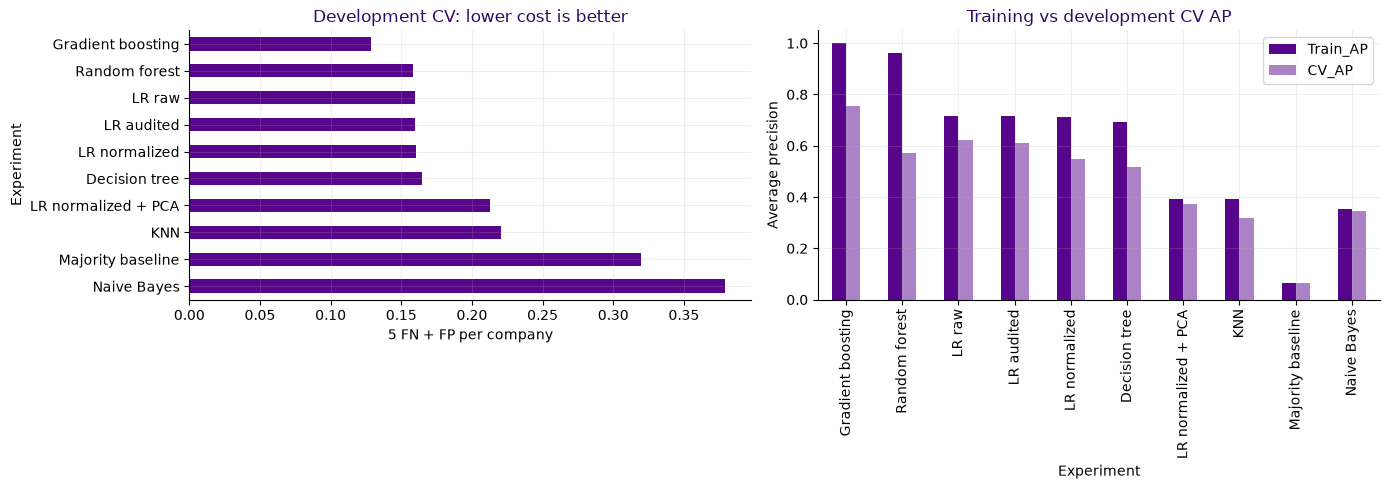

The initial lowest CV cost is **Gradient boosting**, with 0.1283 cost/company. I will tune the two leading model families next rather than treating this initial ranking as conclusive.

In [23]:
experiment_specs = [
    ('Majority baseline', 'Dummy', 'raw', False),
    ('LR raw', 'LogisticRegression', 'raw', False),
    ('LR audited', 'LogisticRegression', 'audited', False),
    ('LR normalized', 'LogisticRegression', 'normalized', False),
    ('LR normalized + PCA', 'LogisticRegression', 'normalized', True),
    ('Naive Bayes', 'GaussianNB', 'normalized', False),
    ('KNN', 'KNeighborsClassifier', 'normalized', False),
    ('Decision tree', 'DecisionTreeClassifier', 'normalized', False),
    ('Random forest', 'RandomForestClassifier', 'normalized', False),
    ('Gradient boosting', 'HistGradientBoostingClassifier', 'normalized', False)]
experiments={}; experiment_rows=[]
for name, family, mode, use_pca in experiment_specs:
    model=DummyClassifier(strategy='most_frequent') if family=='Dummy' else make_model(family,mode,use_pca)
    start=time.perf_counter()
    result=cross_validate(model,X_dev,y_dev,cv=cv,scoring=scoring,n_jobs=N_JOBS,
                          return_train_score=True,error_score='raise')
    experiments[name]=dict(model=model, family=family, mode=mode, pca=use_pca, result=result)
    experiment_rows.append({'Experiment':name,
        'CV_cost_per_company':-result['test_neg_cost'].mean(),
        'Cost_fold_SD':result['test_neg_cost'].std(ddof=1),
        'CV_AP':result['test_AP'].mean(),'Train_AP':result['train_AP'].mean(),
        'CV_ROC_AUC':result['test_ROC_AUC'].mean(),
        'Default_accuracy':result['test_Accuracy'].mean(),
        'Default_recall':result['test_Recall'].mean(),
        'Default_precision':result['test_Precision'].mean(),
        'Seconds':time.perf_counter()-start})
    print(f'{name}: completed five grouped folds',flush=True)
experiment_table=pd.DataFrame(experiment_rows).set_index('Experiment').sort_values(
    ['CV_cost_per_company','CV_AP'],ascending=[True,False])
display(experiment_table)
fig,ax=plt.subplots(1,2,figsize=(14,5))
experiment_table.CV_cost_per_company.sort_values(ascending=False).plot.barh(ax=ax[0], color=NYU_PURPLE)
ax[0].set(title='Development CV: lower cost is better',xlabel='5 FN + FP per company')
experiment_table[['Train_AP','CV_AP']].plot.bar(ax=ax[1], color=[NYU_PURPLE, NYU_LIGHT_PURPLE])
ax[1].set(title='Training vs development CV AP',ylabel='Average precision')
plt.tight_layout();plt.show()
display(Markdown(f'The initial lowest CV cost is **{experiment_table.index[0]}**, '
    f'with {experiment_table.iloc[0].CV_cost_per_company:.4f} cost/company. '
    'I will tune the two leading model families next rather '
    'than treating this initial ranking as conclusive.'))

Boosting achieves the lowest initial cross-validation cost (0.1283 per company), followed by random forest (0.1581). The logistic-regression variants cost 0.1595 for raw features, 0.1598 for audited features and 0.1588 for normalized features. Their small differences do not change the decision to tune boosting and random forest. Correcting the units makes the features interpretable, but does not automatically improve predictions. PCA and KNN do not help in this comparison.

The initial ranking is a screen rather than a final choice. I use cost and AP, alongside variation across folds, before tuning the leading families.

<a id="tuning-the-promising-models"></a>

## Tuning the promising models

The initial comparison points me toward boosting and random forest. For boosting I vary leaves, learning rate and L2 penalty. For random forest I vary depth, minimum leaf size and class weighting. Each gets eight combinations on the same development folds.

I choose the lowest mean cost, with AP breaking exact ties. I also keep every untuned contender eligible: tuning cannot erase a better initial model. The test set plays no part in this choice. The selected settings and scores are printed below.


In [24]:
grids={
    'LogisticRegression':{'classifier__C':[.01,.1,1,10],
                          'classifier__class_weight':[None,'balanced']},
    'GaussianNB':{'classifier__var_smoothing':[1e-11,1e-9,1e-7,1e-5]},
    'KNeighborsClassifier':{'classifier__n_neighbors':[7,21,51],
                            'classifier__weights':['uniform','distance']},
    'DecisionTreeClassifier':{'classifier__max_depth':[3,5,8],
        'classifier__min_samples_leaf':[10,30],
        'classifier__class_weight':[None,'balanced']},
    'RandomForestClassifier':{'classifier__max_depth':[8,None],
        'classifier__min_samples_leaf':[2,8],
        'classifier__class_weight':[None,'balanced_subsample']},
    'HistGradientBoostingClassifier':{'classifier__max_leaf_nodes':[7,15],
        'classifier__learning_rate':[.05,.1],
        'classifier__l2_regularization':[1,10]}}
chosen_names=[]; families_seen=set()
for name in experiment_table.index:
    family=experiments[name]['family']
    if family!='Dummy' and family not in families_seen:
        chosen_names.append(name);families_seen.add(family)
    if len(chosen_names)==2:break
searches={};tuning_rows=[]
for name in chosen_names:
    spec=experiments[name]
    search=GridSearchCV(spec['model'],grids[spec['family']],cv=cv,scoring=scoring,
        refit=False,n_jobs=N_JOBS,return_train_score=True,error_score='raise')
    search.fit(X_dev,y_dev);searches[name]=search
    result=pd.DataFrame(search.cv_results_)
    for _,row in result.iterrows():
        tuning_rows.append({'Source':name,'Family':spec['family'],'Mode':spec['mode'],
            'PCA':spec['pca'],'Params':row['params'],
            'CV_cost_per_company':-row['mean_test_neg_cost'],
            'Cost_fold_SD':row['std_test_neg_cost'],'CV_AP':row['mean_test_AP'],
            'Train_AP':row['mean_train_AP'],'CV_ROC_AUC':row['mean_test_ROC_AUC']})
    print(f'Tuned {name}: {len(result)} parameter combinations x five folds',flush=True)
tuning_table=pd.DataFrame(tuning_rows).sort_values(
    ['CV_cost_per_company','CV_AP'],ascending=[True,False]).reset_index(drop=True)
# Match experiment numbers across the scores and settings tables.
display(tuning_table.drop(columns=['Family', 'Params']))
def describe_setting(name, value):
    # None has a specific meaning for these settings, rather than a missing value.
    if value is None:
        return {'classifier__max_depth': 'No depth cap',
                'classifier__class_weight': 'No class weighting'}.get(name, 'None')
    return value

tuning_settings = pd.DataFrame([
    {name.replace('classifier__', ''): describe_setting(name, value)
     for name, value in params.items()} for params in tuning_table.Params
]).fillna('Not applicable')
display(pd.concat([tuning_table[['Source']], tuning_settings], axis=1))
# Untuned contenders remain eligible so tuning cannot erase a better initial model.
selection_rows=tuning_table.to_dict('records')
for name,row in experiment_table.iterrows():
    spec=experiments[name]
    if spec['family']!='Dummy':
        selection_rows.append({'Source':name,'Family':spec['family'],'Mode':spec['mode'],
            'PCA':spec['pca'],'Params':{},'CV_cost_per_company':row.CV_cost_per_company,
            'Cost_fold_SD':row.Cost_fold_SD,'CV_AP':row.CV_AP,'Train_AP':row.Train_AP,
            'CV_ROC_AUC':row.CV_ROC_AUC})
winner=sorted(selection_rows,key=lambda r:(r['CV_cost_per_company'],-r['CV_AP']))[0]
locked_model=clone(experiments[winner['Source']]['model']).set_params(**winner['Params'])
print('Development reference:', winner['Family'], '| representation:', winner['Mode'])
reference_params = locked_model.named_steps['classifier'].get_params()
reference_keys = ['max_iter', 'max_leaf_nodes', 'max_depth', 'min_samples_leaf',
    'learning_rate', 'l2_regularization', 'max_features', 'class_weight', 'early_stopping', 'random_state']
display(pd.DataFrame({'Parameter': [key for key in reference_keys if key in reference_params],
    'Value': [describe_setting('classifier__' + key, reference_params[key])
              for key in reference_keys if key in reference_params]}))
print('Development CV cost/company:',winner['CV_cost_per_company'])

Tuned Gradient boosting: 8 parameter combinations x five folds


Tuned Random forest: 8 parameter combinations x five folds


,Source,Mode,PCA,CV_cost_per_company,Cost_fold_SD,CV_AP,Train_AP,CV_ROC_AUC
0,Gradient boosting,normalized,False,0.122445,0.0215974,0.754211,0.999716,0.942314
1,Gradient boosting,normalized,False,0.122446,0.021125,0.751582,1,0.944104
2,Gradient boosting,normalized,False,0.123476,0.0315186,0.75232,0.977527,0.942394
3,Gradient boosting,normalized,False,0.125899,0.030951,0.731075,0.999891,0.940346
4,Gradient boosting,normalized,False,0.128326,0.024038,0.75324,1,0.94583
5,Gradient boosting,normalized,False,0.129014,0.0353339,0.715678,0.986161,0.938077
6,Gradient boosting,normalized,False,0.133859,0.0276923,0.717432,0.980773,0.933825
7,Gradient boosting,normalized,False,0.144582,0.0223519,0.707668,0.919523,0.932531
8,Random forest,normalized,False,0.145273,0.0154189,0.588824,0.999743,0.918967
9,Random forest,normalized,False,0.15392,0.0278821,0.562902,0.935018,0.914713


,Source,l2_regularization,learning_rate,max_leaf_nodes,class_weight,max_depth,min_samples_leaf
0,Gradient boosting,1,0.1,7,Not applicable,Not applicable,Not applicable
1,Gradient boosting,1,0.05,15,Not applicable,Not applicable,Not applicable
2,Gradient boosting,1,0.05,7,Not applicable,Not applicable,Not applicable
3,Gradient boosting,10,0.1,15,Not applicable,Not applicable,Not applicable
4,Gradient boosting,1,0.1,15,Not applicable,Not applicable,Not applicable
5,Gradient boosting,10,0.05,15,Not applicable,Not applicable,Not applicable
6,Gradient boosting,10,0.1,7,Not applicable,Not applicable,Not applicable
7,Gradient boosting,10,0.05,7,Not applicable,Not applicable,Not applicable
8,Random forest,Not applicable,Not applicable,Not applicable,No class weighting,No depth cap,2
9,Random forest,Not applicable,Not applicable,Not applicable,No class weighting,8,2


Development reference: HistGradientBoostingClassifier | representation: normalized


,Parameter,Value
0,max_iter,150
1,max_leaf_nodes,7
2,max_depth,No depth cap
3,min_samples_leaf,20
4,learning_rate,0.1
5,l2_regularization,1
6,max_features,1
7,class_weight,No class weighting
8,early_stopping,False
9,random_state,42


Development CV cost/company: 0.12244533290304845


The tables above show which classifier settings lowered development-validation cost. I select from those training results, keeping untuned candidates eligible too. The following error analysis uses out-of-fold predictions rather than the fitted training predictions, so I can look at mistakes the model made on rows it did not fit.


<a id="looking-at-the-model-s-mistakes"></a>

## Looking at the model's mistakes

I use predictions made for each development company by a model that was fitted without that company's fold. I look at bankrupt companies it misses and healthy companies it flags, compare their financial values and missingness, and plot a learning curve.

I also shuffle one feature at a time on a development validation fold to see which features the fitted model relies on. This is permutation importance, which differs from the label-shuffle test later. Correlated features can share importance. These folds have already helped select the model, so the results help explain it rather than provide a new independent score. I keep the chosen settings fixed.

,Accuracy,Recall,Precision,ROC_AUC,AP,Brier,TN,FP,FN,TP,Cost,Cost_per_company
Development OOF at 1/6,0.955033,0.697297,0.635468,0.939941,0.748408,0.0286674,2632,74,56,129,354,0.122449


,num_13_to_assets,working_capital_to_assets,liabilities_to_assets,current_ratio,net_margin,Missing_fraction,OOF_probability
Outcome,,,,,,,
FN,0.0190605,0.0851565,0.63659,1.23858,0.0125189,0.0151515,0.0303028
FP,-0.099549,-0.0754925,0.801195,0.8389,-0.0806256,0.0151515,0.296996
TN,0.0518985,0.238485,0.431795,1.73488,0.0389351,0,0.00266782
TP,-0.11684,-0.11967,0.76818,0.81056,-0.0709166,0.0151515,0.807919


,Predicted healthy,Predicted bankrupt
Actual healthy,2632,74
Actual bankrupt,56,129


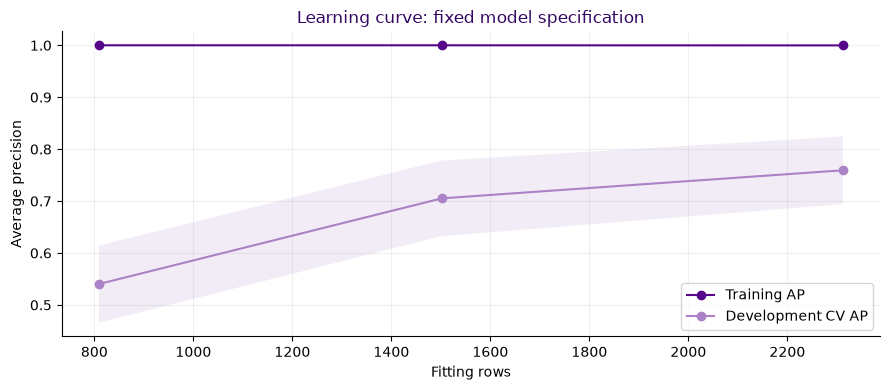

,Mean_AP_decrease,Repeat_SD
Feature,,
ratio_05,0.208595,0.0117191
ratio_21,0.177347,0.0287368
num_11,0.121392,0.00872578
num_27,0.0733327,0.00796305
num_32,0.0587021,0.0106147
num_35,0.0513063,0.00704416
num_18,0.0493124,0.0125955
ratio_09,0.0351414,0.0100653
short_term_liabilities,0.0230201,0.015756


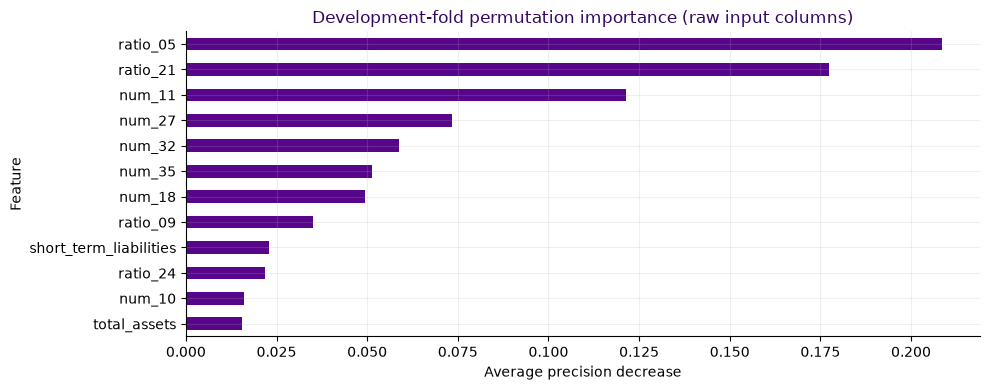

The locked model is **HistGradientBoostingClassifier** using **normalized** features. At the comparison threshold, development OOF cost is **354**; it misses **56** bankruptcies and creates **74** false alarms. Error-group medians describe associations, not causal explanations. A training/CV gap suggests that some overfitting remains; more representative labeled companies may help.

In [25]:
oof_prob=cross_val_predict(locked_model,X_dev,y_dev,cv=cv,method='predict_proba',
                         n_jobs=N_JOBS)[:,1]
oof_pred=(oof_prob>=1/6).astype(int)
display(pd.DataFrame([metric_row(y_dev,oof_pred,oof_prob)],index=['Development OOF at 1/6']))
error_labels=np.select([(y_dev==1)&(oof_pred==0),(y_dev==0)&(oof_pred==1),
    (y_dev==1)&(oof_pred==1)],['FN','FP','TP'],default='TN')
error_frame=FinancialFeatures('normalized').fit_transform(X_dev)
diagnostic_cols=['num_13_to_assets','working_capital_to_assets','liabilities_to_assets',
                 'current_ratio','net_margin']
error_frame['Outcome']=error_labels
error_frame['Missing_fraction']=X_dev.drop(columns='Id').isna().mean(axis=1)
error_frame['OOF_probability']=oof_prob
display(error_frame.groupby('Outcome')[diagnostic_cols+['Missing_fraction',
    'OOF_probability']].median())
display(pd.DataFrame(confusion_matrix(y_dev,oof_pred),
    index=['Actual healthy','Actual bankrupt'],columns=['Predicted healthy','Predicted bankrupt']))
sizes,train_scores,val_scores=learning_curve(locked_model,X_dev,y_dev,
    cv=cv,train_sizes=[.35,.65,1],scoring='average_precision',
    n_jobs=N_JOBS,shuffle=True,random_state=SEED,error_score='raise')
fig,ax=plt.subplots(figsize=(9,4))
for scores,label in [(train_scores,'Training AP'),(val_scores,'Development CV AP')]:
    mean=scores.mean(axis=1);std=scores.std(axis=1)
    ax.plot(sizes,mean,'o-',label=label)
    ax.fill_between(sizes,mean-std,mean+std,alpha=.15)
ax.set(xlabel='Fitting rows',ylabel='Average precision',title='Learning curve: fixed model specification')
ax.legend();plt.tight_layout();plt.show()
fit_idx,val_idx=cv[0]
interpretation_model=clone(locked_model).fit(X_dev.iloc[fit_idx],y_dev.iloc[fit_idx])
importance=permutation_importance(interpretation_model,X_dev.iloc[val_idx],y_dev.iloc[val_idx],
    scoring='average_precision',n_repeats=4,random_state=SEED,n_jobs=N_JOBS)
importance_table=pd.DataFrame({'Feature':X_dev.columns,'Mean_AP_decrease':importance.importances_mean,
    'Repeat_SD':importance.importances_std}).set_index('Feature').sort_values('Mean_AP_decrease',ascending=False)
display(importance_table.head(12))
importance_table.Mean_AP_decrease.head(12).sort_values().plot.barh(color=NYU_PURPLE)
plt.title('Development-fold permutation importance (raw input columns)')
plt.xlabel('Average precision decrease');plt.tight_layout();plt.show()
assert abs(importance_table.loc['Id','Mean_AP_decrease'])<1e-12
display(Markdown(f'The locked model is **{winner["Family"]}** using **{winner["Mode"]}** features. '
    f'At the comparison threshold, development OOF cost is **{cost(y_dev,oof_pred)}**; '
    f'it misses **{int(((y_dev==1)&(oof_pred==0)).sum())}** bankruptcies and creates '
    f'**{int(((y_dev==0)&(oof_pred==1)).sum())}** false alarms. '
    'Error-group medians describe associations, not causal explanations. '
    'A training/CV gap suggests that some overfitting remains; '
    'more representative labeled companies may help.'))

<a id="studying-the-probability-residuals"></a>

### Studying the probability residuals

For classification, I use **residual = actual outcome − predicted probability**. A bankrupt company assigned 0.10 has residual +0.90; a healthy company assigned 0.80 has residual −0.80.

I reuse development out-of-fold predictions and examine residuals by probability, class and debt/assets group. Positive average residuals mean risk is underestimated; negative averages mean it is overestimated. Counts help distinguish a broad pattern from a few unusual companies.

Binary outcomes naturally produce two scatter bands, **1 − p** and **−p**, with variance that changes with p. I therefore do not apply ordinary linear-regression normality or constant-variance rules. Binned averages and mistake sizes are more informative. These folds helped select the settings, so the plots diagnose an explored model rather than independently validate it.

,Rows,Bankruptcies,Observed_rate,Mean_probability,Mean_residual,Brier,Mean_absolute_residual
All development rows,2891,185,0.0639917,0.0521486,0.0118431,0.0286674,0.0497258


,Rows,Bankruptcies,Observed_rate,Mean_probability,Mean_residual,Brier,Mean_absolute_residual
Outcome,,,,,,,
FN,56,56,1,0.0539331,0.946067,0.897961,0.946067
FP,74,0,0,0.351669,-0.351669,0.152621,0.351669
TN,2632,0,0,0.0109179,-0.0109179,0.000639211,0.0109179
TP,129,129,1,0.72079,0.27921,0.152057,0.27921


,Rows,Bankruptcies,Observed_rate,Mean_probability,Mean_residual,Brier,Mean_absolute_residual
Probability_bin,,,,,,,
"(-0.001, 0.02]",2296,24,0.010453,0.00379502,0.00665794,0.0103324,0.0140936
"(0.02, 0.05]",215,10,0.0465116,0.0312061,0.0153055,0.0445134,0.0746738
"(0.05, 0.1]",112,9,0.0803571,0.0698231,0.0105341,0.0728035,0.137545
"(0.1, 0.167]",65,13,0.2,0.130975,0.0690249,0.161857,0.275338
"(0.167, 0.3]",55,16,0.290909,0.230292,0.0606167,0.21184,0.387535
"(0.3, 0.5]",39,15,0.384615,0.381955,0.00266068,0.257833,0.490503
"(0.5, 0.75]",30,23,0.766667,0.634055,0.132611,0.188857,0.414867
"(0.75, 1.0]",79,75,0.949367,0.916727,0.0326397,0.0447715,0.115843


,Rows,Bankruptcies,Observed_rate,Mean_probability,Mean_residual,Brier,Mean_absolute_residual
Debt_group,,,,,,,
"(0.256, 0.453]",722,22,0.0304709,0.0219003,0.00857061,0.015711,0.0269068
"(-0.001, 0.256]",723,17,0.0235131,0.0184636,0.00504956,0.0158639,0.0269591
"(0.453, 0.667]",722,35,0.0484765,0.0356632,0.0128132,0.0246241,0.0408708
"(0.667, 8.552]",723,110,0.152144,0.132075,0.0200693,0.0579234,0.103309
Missing debt/assets,1,1,1,0.361744,0.638256,0.407371,0.638256


,Rows,Bankruptcies,Observed_rate,Mean_probability,Mean_residual,Brier,Mean_absolute_residual
Missing_ratio_05,,,,,,,
False,2707,132,0.0487625,0.0396389,0.00912356,0.0265739,0.0451951
True,184,53,0.288043,0.236191,0.0518524,0.0594672,0.116382


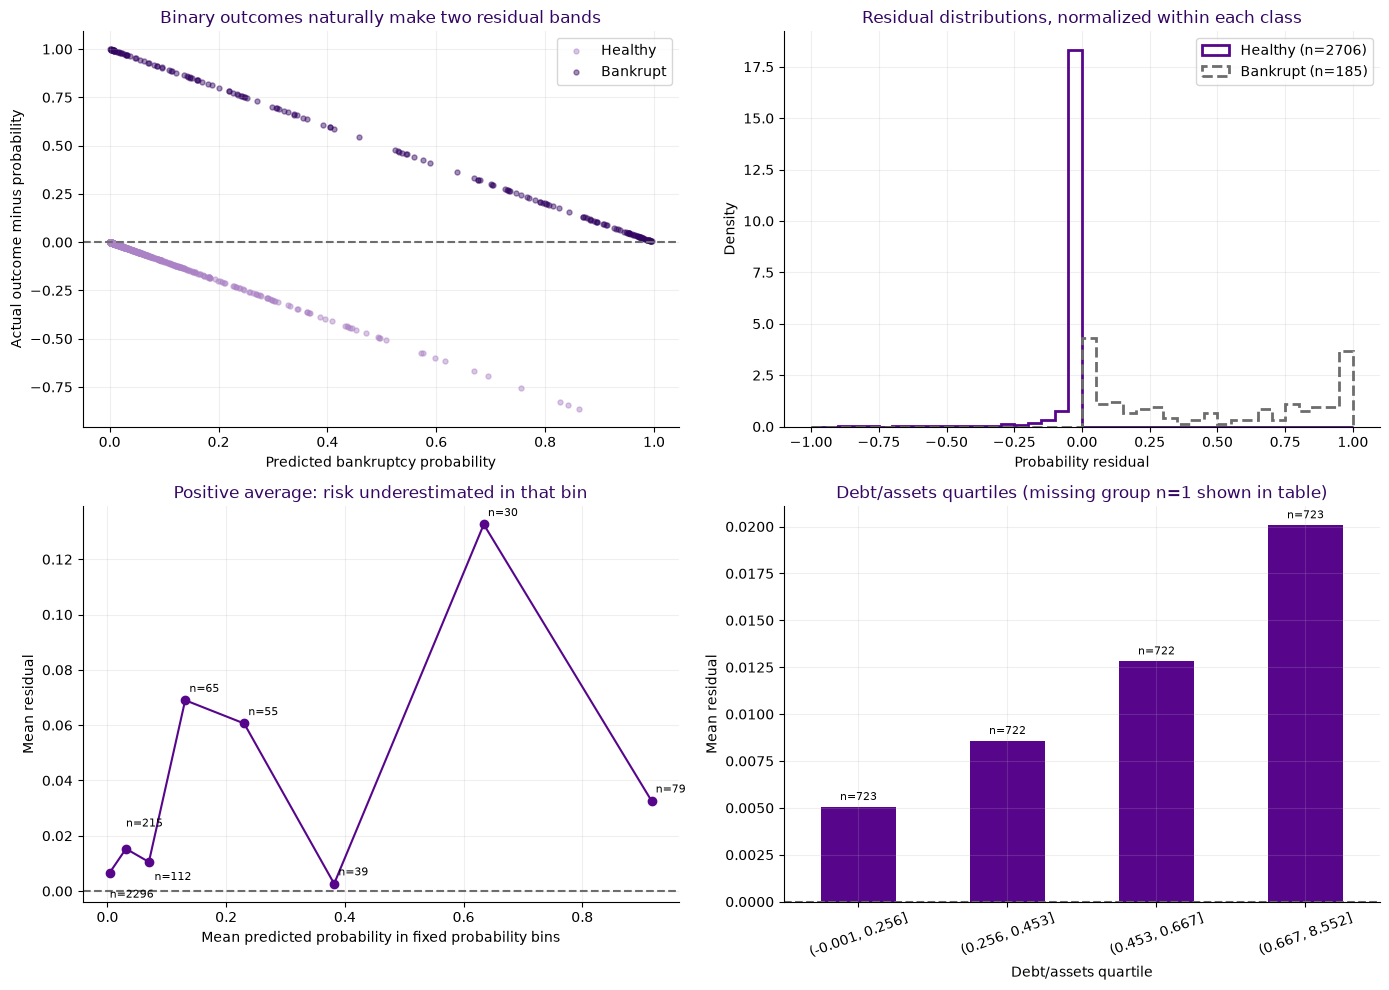

Residual analysis uses development out-of-fold predictions; the test stays closed.


In [26]:
# Reuse training-development OOF probabilities; no additional test predictions.
residual_frame = pd.DataFrame(index=X_dev.index)
residual_frame['Actual'] = y_dev.to_numpy()
residual_frame['Probability'] = np.asarray(oof_prob)
residual_frame['Residual'] = residual_frame.Actual - residual_frame.Probability
residual_frame['Squared_error'] = residual_frame.Residual ** 2
residual_frame['Absolute_residual'] = residual_frame.Residual.abs()
residual_frame['Outcome'] = np.select(
    [(residual_frame.Actual == 1) & (oof_prob < 1/6),
     (residual_frame.Actual == 0) & (oof_prob >= 1/6),
     (residual_frame.Actual == 1) & (oof_prob >= 1/6)],
    ['FN', 'FP', 'TP'], default='TN')
residual_features = FinancialFeatures('normalized').transform(X_dev)
residual_frame['Debt_to_assets'] = residual_features.liabilities_to_assets
residual_frame['Missing_ratio_05'] = X_dev.ratio_05.isna().to_numpy()
residual_frame['Probability_bin'] = pd.cut(residual_frame.Probability,
    bins=[0, .02, .05, .10, 1/6, .30, .50, .75, 1], include_lowest=True)
residual_frame['Debt_group'] = pd.qcut(residual_frame.Debt_to_assets,
    q=4, duplicates='drop').astype(object)
residual_frame.loc[residual_frame.Debt_to_assets.isna(), 'Debt_group'] = 'Missing debt/assets'

def summarize_residuals(grouped):
    return grouped.agg(Rows=('Actual', 'size'), Bankruptcies=('Actual', 'sum'),
        Observed_rate=('Actual', 'mean'), Mean_probability=('Probability', 'mean'),
        Mean_residual=('Residual', 'mean'), Brier=('Squared_error', 'mean'),
        Mean_absolute_residual=('Absolute_residual', 'mean'))

residual_overall = summarize_residuals(residual_frame.groupby(lambda _: 'All development rows'))
residual_by_outcome = summarize_residuals(residual_frame.groupby('Outcome'))
residual_by_probability = summarize_residuals(residual_frame.groupby('Probability_bin', observed=True))
residual_by_debt = summarize_residuals(residual_frame.groupby('Debt_group', sort=False, observed=True))
residual_by_missingness = summarize_residuals(residual_frame.groupby('Missing_ratio_05'))
display(residual_overall)
display(residual_by_outcome)
display(residual_by_probability)
display(residual_by_debt)
display(residual_by_missingness)
assert np.isclose(residual_frame.Squared_error.mean(), brier_score_loss(y_dev, oof_prob))
assert np.isclose(residual_frame.Residual.mean(), y_dev.mean() - np.mean(oof_prob))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for label, name, color in [(0, 'Healthy', NYU_LIGHT_PURPLE), (1, 'Bankrupt', NYU_DARK_PURPLE)]:
    rows = residual_frame.Actual.eq(label)
    axes[0, 0].scatter(residual_frame.loc[rows, 'Probability'],
        residual_frame.loc[rows, 'Residual'], s=13, alpha=.45, color=color, label=name)
    axes[0, 1].hist(residual_frame.loc[rows, 'Residual'], bins=np.linspace(-1, 1, 41),
        density=True, histtype='step', linewidth=2, linestyle='-' if label == 0 else '--',
        color=NYU_PURPLE if label == 0 else NYU_GRAY, label=f'{name} (n={int(rows.sum())})')
axes[0, 0].axhline(0, color=NYU_GRAY, linestyle='--')
axes[0, 0].set(title='Binary outcomes naturally make two residual bands',
    xlabel='Predicted bankruptcy probability', ylabel='Actual outcome minus probability')
axes[0, 0].legend()
axes[0, 1].set(title='Residual distributions, normalized within each class',
    xlabel='Probability residual', ylabel='Density')
axes[0, 1].legend()
axes[1, 0].plot(residual_by_probability.Mean_probability,
    residual_by_probability.Mean_residual, 'o-', color=NYU_PURPLE)
for bin_number, (_, row) in enumerate(residual_by_probability.iterrows()):
    axes[1, 0].annotate(f'n={int(row.Rows)}',
        (row.Mean_probability, row.Mean_residual), xytext=([(0, -18), (0, 16), (4, -13)][bin_number] if bin_number < 3 else (3, 6)),
        textcoords='offset points', fontsize=8)
axes[1, 0].axhline(0, color=NYU_GRAY, linestyle='--')
axes[1, 0].set(title='Positive average: risk underestimated in that bin',
    xlabel='Mean predicted probability in fixed probability bins', ylabel='Mean residual')
# Keep the one missing-debt company in the table; plot the four meaningful quartiles.
debt_plot = residual_by_debt.loc[[g for g in residual_by_debt.index if isinstance(g, pd.Interval)]].sort_index()
debt_plot.Mean_residual.plot.bar(ax=axes[1, 1], color=NYU_PURPLE)
for bar_number, (_, row) in enumerate(debt_plot.iterrows()):
    axes[1, 1].annotate(f'n={int(row.Rows)}', (bar_number, row.Mean_residual),
        xytext=(0, 5), textcoords='offset points', ha='center', fontsize=8)
axes[1, 1].axhline(0, color=NYU_GRAY, linestyle='--')
axes[1, 1].set(title='Debt/assets quartiles (missing group n=1 shown in table)', xlabel='Debt/assets quartile',
    ylabel='Mean residual')
axes[1, 1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
print('Residual analysis uses development out-of-fold predictions; the test stays closed.')


I compare the observed bankruptcy rate with the average predicted risk, then examine residuals by probability band and financial group. Positive average residuals mean risk was underestimated in that group. I use the table counts to judge how much evidence each pattern has; a large gap in a tiny group is not automatically a useful feature.


<a id="which-companies-does-the-model-miss"></a>

### Which companies does the model miss?

I use the same development out-of-fold predictions to examine recall, false negatives, false alarms and cost within financial groups. I compare missing versus observed `ratio_05`, debt above versus below assets, negative versus nonnegative profit, and negative versus nonnegative working capital. I also check whether apparently reassuring profit coexists with low liquidity.

The groups overlap, so I cannot add their errors together. Accounting profit does not guarantee cash is available to pay debt. These descriptive comparisons motivate specific hypotheses, not another search for cutoffs.

,Rows,Bankruptcies,FN,FP,Recall,False_alarm_rate,Mean_residual,Cost
Group,,,,,,,,
ratio_05 missing,184,53,4,10,0.924528,0.0763359,0.0518524,30
ratio_05 observed,2707,132,52,64,0.606061,0.0248544,0.00912356,324
Debt > assets,147,42,8,23,0.809524,0.219048,0.0204566,63
Debt <= assets,2743,142,48,51,0.661972,0.0196078,0.0111531,291
Negative net profit,593,116,21,50,0.818966,0.104822,0.0248415,155
Nonnegative net profit,2297,68,35,24,0.485294,0.0107672,0.00821466,199
Negative working capital,560,101,19,45,0.811881,0.0980392,0.0167166,140
Nonnegative working capital,2330,83,37,29,0.554217,0.0129061,0.0104029,214
"Nonnegative profit, negative working capital",288,25,9,9,0.64,0.0342205,0.0144585,54


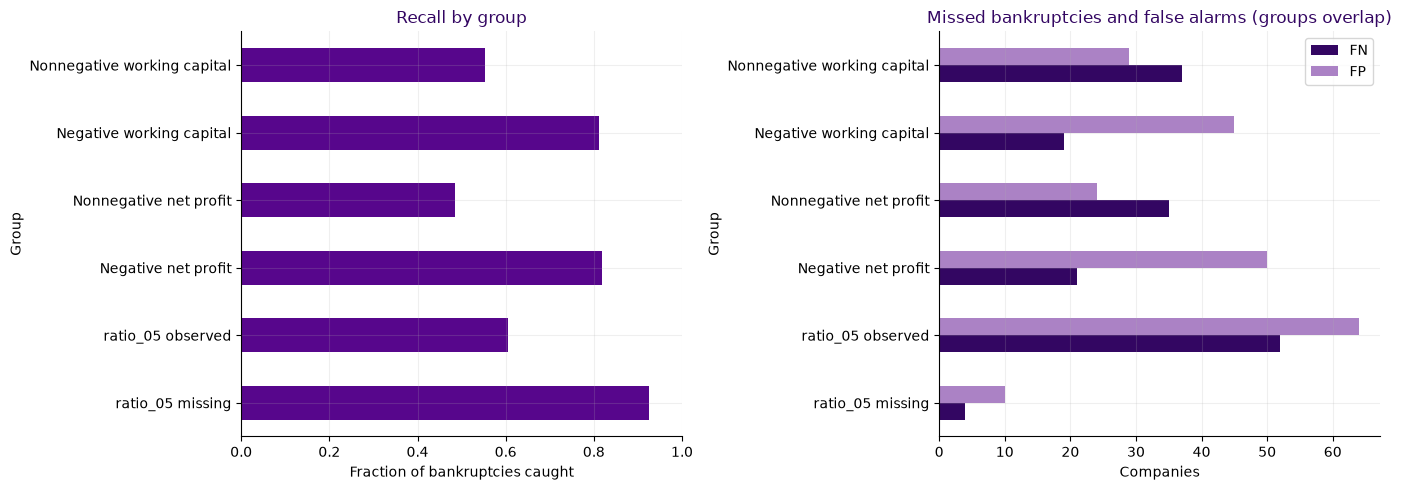

In [27]:
group_features = FinancialFeatures('normalized').transform(X_dev)
subgroup_masks = {
    'ratio_05 missing': X_dev.ratio_05.isna(),
    'ratio_05 observed': X_dev.ratio_05.notna(),
    'Debt > assets': group_features.liabilities_to_assets.gt(1),
    'Debt <= assets': group_features.liabilities_to_assets.le(1),
    'Negative net profit': group_features.num_13_to_assets.lt(0),
    'Nonnegative net profit': group_features.num_13_to_assets.ge(0),
    'Negative working capital': group_features.working_capital_to_assets.lt(0),
    'Nonnegative working capital': group_features.working_capital_to_assets.ge(0),
    'Nonnegative profit, negative working capital':
        group_features.num_13_to_assets.ge(0) & group_features.working_capital_to_assets.lt(0),
    'Nonnegative profit, nonnegative working capital':
        group_features.num_13_to_assets.ge(0) & group_features.working_capital_to_assets.ge(0)}
subgroup_rows = []
for name, mask in subgroup_masks.items():
    actual = y_dev.loc[mask].to_numpy()
    probability = oof_prob[mask.to_numpy()]
    prediction = (probability >= 1/6).astype(int)
    missed = int(((actual == 1) & (prediction == 0)).sum())
    false_alarm = int(((actual == 0) & (prediction == 1)).sum())
    positives = int(actual.sum()); negatives = len(actual) - positives
    subgroup_rows.append(dict(Group=name, Rows=len(actual), Bankruptcies=positives,
        FN=missed, FP=false_alarm, Recall=1-missed/positives if positives else np.nan,
        False_alarm_rate=false_alarm/negatives if negatives else np.nan,
        Mean_residual=float(np.mean(actual-probability)), Cost=5*missed+false_alarm))
subgroup_error_table = pd.DataFrame(subgroup_rows).set_index('Group')
display(subgroup_error_table)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_groups = ['ratio_05 missing', 'ratio_05 observed', 'Negative net profit',
    'Nonnegative net profit', 'Negative working capital', 'Nonnegative working capital']
subgroup_error_table.loc[plot_groups, 'Recall'].plot.barh(ax=axes[0], color=NYU_PURPLE)
axes[0].set(xlim=(0, 1), xlabel='Fraction of bankruptcies caught', title='Recall by group')
subgroup_error_table.loc[plot_groups, ['FN', 'FP']].plot.barh(ax=axes[1],
    color=[NYU_DARK_PURPLE, NYU_LIGHT_PURPLE])
axes[1].set(xlabel='Companies', title='Missed bankruptcies and false alarms (groups overlap)')
plt.tight_layout(); plt.show()


A probability gap is different from a missed-bankruptcy count. I look at both recall and the number of false negatives in each group. The groups overlap, so their errors cannot be added together. These are training findings that motivate specific comparisons, not evidence for changing the threshold after looking at test outcomes.


<a id="looking-inside-apparently-healthy-accounts"></a>

### Looking inside apparently healthy accounts

Nonnegative profit and working capital can hide weak liquidity. I examine near-cash and quick-asset coverage, inventory/current-assets and short-term debt's share of liabilities. I also check retained earnings and the existing sales-growth ratio instead of inventing cash-flow or profit-history measures.

Within the apparently healthy development group, I report bankruptcy counts, observed risk, predicted risk, residuals and recall. The ranges are descriptive, groups overlap, and some are small.

The table uses the converted inventory share `(num_10 / 365) / num_06`, so the 0.5 cutoff really means half of current assets. Approximate DSO uses `365 * (num_27 / 365) / sales`. The scale checks appear earlier so these groups are interpreted consistently.

,Rows,Bankruptcies,Observed_rate,Mean_probability,Mean_residual,FN,FP,Recall,Cost
Group,,,,,,,,,
All nonnegative profit + working capital,2009,43,0.0214037,0.0140841,0.00731957,26,15,0.395349,145
Near cash / short debt < 0.1,552,17,0.0307971,0.0207621,0.010035,9,6,0.470588,51
Near cash / short debt 0.1 to < 0.5,665,11,0.0165414,0.0114524,0.00508897,6,3,0.454545,33
Near cash / short debt >= 0.5,786,15,0.019084,0.0114442,0.00763974,11,6,0.266667,61
Quick assets / short debt < 1,626,22,0.0351438,0.0217265,0.0134173,13,5,0.409091,70
Quick assets / short debt >= 1,1377,21,0.0152505,0.010509,0.00474154,13,10,0.380952,75
Inventory > half of current assets,358,10,0.027933,0.0173406,0.0105923,6,3,0.4,33
Inventory <= half of current assets,1646,33,0.0200486,0.0132837,0.00676492,20,12,0.393939,112
Short debt > half of total liabilities,1787,37,0.0207051,0.0139772,0.00672793,22,14,0.405405,124


,Missing_rows
Near_cash_coverage,6
Quick_coverage,6
Inventory_share_current_assets,5
Short_debt_share,5
DSO_days,0
Retained_earnings,0
Sales_growth,6


,Near_cash_coverage,Quick_coverage,Inventory_share_current_assets,Short_debt_share,DSO_days,Sales_growth
Outcome,,,,,,
Bankrupt,0.18161,0.97279,0.166589,0.956195,54.15,1.0253
Healthy,0.313755,1.384,0.25123,0.918057,59.613,1.1451


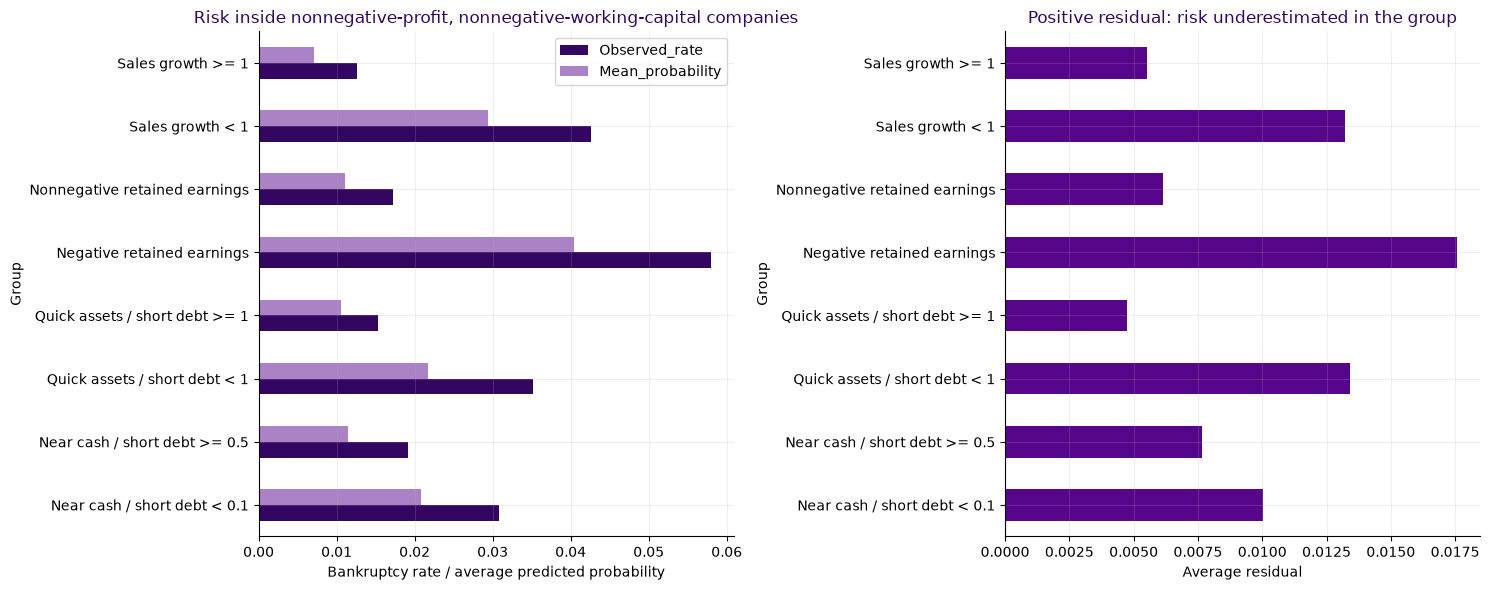

In [28]:
relationship_frame = pd.DataFrame(index=X_dev.index)
relationship_frame['Actual'] = y_dev.to_numpy()
relationship_frame['Probability'] = oof_prob
relationship_frame['Prediction'] = (oof_prob >= 1/6).astype(int)
relationship_frame['Near_cash_coverage'] = safe_divide(X_dev.num_12, X_dev.short_term_liabilities)
relationship_frame['Quick_coverage'] = safe_divide(X_dev.num_32, X_dev.short_term_liabilities)
relationship_frame['Inventory_share_current_assets'] = safe_divide(X_dev.num_10 / 365, X_dev.num_06)
relationship_frame['Short_debt_share'] = safe_divide(X_dev.short_term_liabilities, X_dev.total_liabilities)
relationship_frame['DSO_days'] = 365 * safe_divide(X_dev.num_27 / 365, X_dev.sales.where(X_dev.sales > 0))
relationship_frame['Retained_earnings'] = X_dev.num_20
relationship_frame['Sales_growth'] = X_dev.ratio_21
relationship_frame = relationship_frame.replace([np.inf, -np.inf], np.nan)
apparently_healthy_mask = X_dev.num_13.ge(0) & X_dev.num_19.ge(0)
relationship_frame['Apparently_healthy'] = apparently_healthy_mask
base_mask = apparently_healthy_mask.to_numpy()
relationship_masks = {
    'Near cash / short debt < 0.1': relationship_frame.Near_cash_coverage.lt(.1),
    'Near cash / short debt 0.1 to < 0.5': relationship_frame.Near_cash_coverage.ge(.1) & relationship_frame.Near_cash_coverage.lt(.5),
    'Near cash / short debt >= 0.5': relationship_frame.Near_cash_coverage.ge(.5),
    'Quick assets / short debt < 1': relationship_frame.Quick_coverage.lt(1),
    'Quick assets / short debt >= 1': relationship_frame.Quick_coverage.ge(1),
    'Inventory > half of current assets': relationship_frame.Inventory_share_current_assets.gt(.5),
    'Inventory <= half of current assets': relationship_frame.Inventory_share_current_assets.le(.5),
    'Short debt > half of total liabilities': relationship_frame.Short_debt_share.gt(.5),
    'Short debt <= half of total liabilities': relationship_frame.Short_debt_share.le(.5),
    'Negative retained earnings': relationship_frame.Retained_earnings.lt(0),
    'Nonnegative retained earnings': relationship_frame.Retained_earnings.ge(0),
    'Sales growth < 1': relationship_frame.Sales_growth.lt(1),
    'Sales growth >= 1': relationship_frame.Sales_growth.ge(1)}
def relationship_group_row(name, rows):
    y = rows.Actual.to_numpy(); prediction = rows.Prediction.to_numpy()
    positives = int(y.sum()); fn = int(((y == 1) & (prediction == 0)).sum())
    fp = int(((y == 0) & (prediction == 1)).sum())
    return dict(Group=name, Rows=len(rows), Bankruptcies=positives,
        Observed_rate=float(rows.Actual.mean()), Mean_probability=float(rows.Probability.mean()),
        Mean_residual=float((rows.Actual-rows.Probability).mean()), FN=fn, FP=fp,
        Recall=1-fn/positives if positives else np.nan, Cost=5*fn+fp)
relationship_group_rows = [relationship_group_row('All nonnegative profit + working capital',
    relationship_frame.loc[apparently_healthy_mask])]
for name, mask in relationship_masks.items():
    relationship_group_rows.append(relationship_group_row(name,
        relationship_frame.loc[apparently_healthy_mask & mask]))
relationship_group_table = pd.DataFrame(relationship_group_rows).set_index('Group')
display(relationship_group_table)
relationship_missingness = relationship_frame.loc[apparently_healthy_mask,
    ['Near_cash_coverage', 'Quick_coverage', 'Inventory_share_current_assets', 'Short_debt_share',
     'DSO_days', 'Retained_earnings', 'Sales_growth']].isna().sum().to_frame('Missing_rows')
display(relationship_missingness)
comparison_medians = relationship_frame.loc[apparently_healthy_mask].assign(
    Outcome=np.where(y_dev.loc[apparently_healthy_mask].to_numpy() == 1, 'Bankrupt', 'Healthy')).groupby('Outcome')[
    ['Near_cash_coverage', 'Quick_coverage', 'Inventory_share_current_assets', 'Short_debt_share',
     'DSO_days', 'Sales_growth']].median()
display(comparison_medians)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
selected_groups = ['Near cash / short debt < 0.1', 'Near cash / short debt >= 0.5',
    'Quick assets / short debt < 1', 'Quick assets / short debt >= 1',
    'Negative retained earnings', 'Nonnegative retained earnings',
    'Sales growth < 1', 'Sales growth >= 1']
relationship_group_table.loc[selected_groups, ['Observed_rate', 'Mean_probability']].plot.barh(
    ax=axes[0], color=[NYU_DARK_PURPLE, NYU_LIGHT_PURPLE])
axes[0].set(title='Risk inside nonnegative-profit, nonnegative-working-capital companies',
    xlabel='Bankruptcy rate / average predicted probability')
relationship_group_table.loc[selected_groups, 'Mean_residual'].plot.barh(ax=axes[1], color=NYU_PURPLE)
axes[1].axvline(0, color=NYU_GRAY, linestyle='--')
axes[1].set(title='Positive residual: risk underestimated in the group', xlabel='Average residual')
plt.tight_layout(); plt.show()


Inside the 2,009 companies with nonnegative profit and working capital, bankruptcy is more common when quick assets do not cover short-term debt: 3.51%, versus 1.53% when they do. Negative retained earnings and weaker sales growth also distinguish risk in this group. This supports checking asset availability rather than relying only on profit and the working-capital total.

The converted inventory share and collection days do not show a simple, consistent direction. Median DSO is about 54 days for bankrupt companies and 60 for healthy ones in this subgroup. I therefore do not claim that longer collection times explain the missed bankruptcies. I test the six-feature bundle and the four-feature ablation fairly; the model comparison will show whether the extra relationships help jointly. The groups overlap and some contain few bankruptcies, so these are exploratory associations.


<a id="choosing-when-to-flag-a-bankruptcy"></a>

## Choosing when to flag a bankruptcy

A probability still needs a decision rule. With a missed bankruptcy costing 5 and a false alarm costing 1, a cutoff of 1/6 (about 0.1667) is a useful reference if the probabilities are well calibrated. A cutoff of 0.5 could miss too many costly cases.

I first fit the development reference model on X_dev and compare cutoffs from 0.01 to 0.99, plus 1/6 and 0.5, on the reserved training subset. I choose the lowest cost; a tie selects the higher cutoff. I also compare predicted and observed risk in a calibration plot.

This is an early cutoff study, not the final model decision. The subset was reserved from this classifier fit, but the later full-training studies reuse these companies. Its best cost is a tuning result, not an independent performance estimate. Later comparisons select the classifier settings and cutoff together inside training folds. I freeze the final model only after those comparisons.


,Accuracy,Recall,Precision,ROC_AUC,AP,Brier,TN,FP,FN,TP,Cost,Cost_per_company,Threshold
16,0.957425,0.721311,0.647059,0.939715,0.741126,0.0297682,878,24,17,44,109,0.113188,0.166667
15,0.956386,0.721311,0.637681,0.939715,0.741126,0.0297682,877,25,17,44,110,0.114226,0.16
13,0.952233,0.737705,0.6,0.939715,0.741126,0.0297682,872,30,16,45,110,0.114226,0.14
7,0.938733,0.786885,0.510638,0.939715,0.741126,0.0297682,856,46,13,48,111,0.115265,0.08
6,0.934579,0.803279,0.49,0.939715,0.741126,0.0297682,851,51,12,49,111,0.115265,0.07
12,0.950156,0.737705,0.584416,0.939715,0.741126,0.0297682,870,32,16,45,112,0.116303,0.13
17,0.957425,0.704918,0.651515,0.939715,0.741126,0.0297682,879,23,18,43,113,0.117342,0.17
14,0.953271,0.721311,0.611111,0.939715,0.741126,0.0297682,874,28,17,44,113,0.117342,0.15
11,0.94704,0.737705,0.5625,0.939715,0.741126,0.0297682,867,35,16,45,115,0.119418,0.12
10,0.946002,0.737705,0.555556,0.939715,0.741126,0.0297682,866,36,16,45,116,0.120457,0.11


,Accuracy,Recall,Precision,ROC_AUC,AP,Brier,TN,FP,FN,TP,Cost,Cost_per_company
Threshold,,,,,,,,,,,,
0.166667,0.957425,0.721311,0.647059,0.939715,0.741126,0.0297682,878,24,17,44,109,0.113188
0.500000,0.964694,0.557377,0.829268,0.939715,0.741126,0.0297682,895,7,27,34,142,0.147456


Policy class counts: {0: 902, 1: 61}
Development reference cutoff (provisional): 0.1667


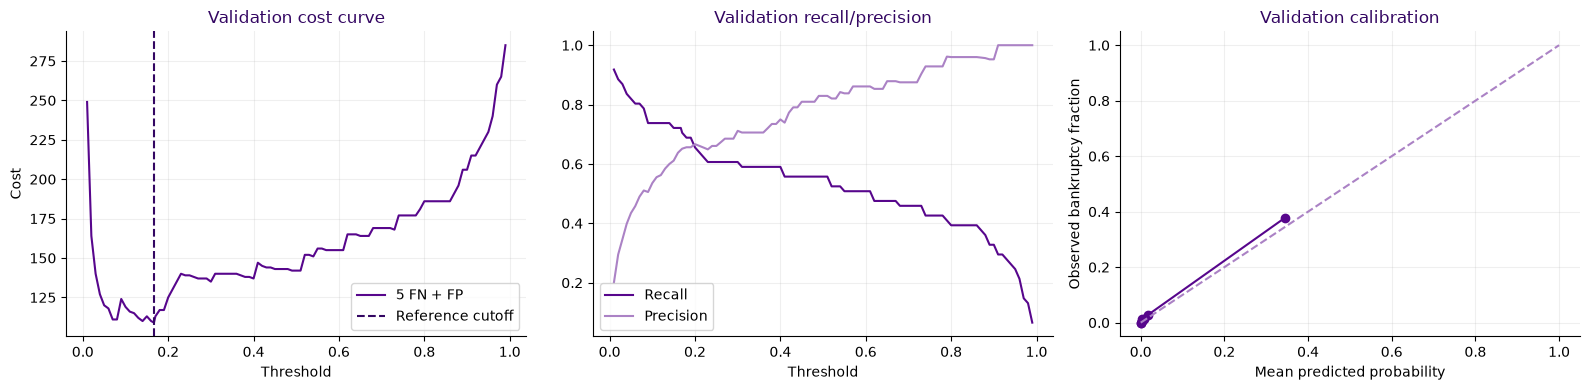

Provisional reference cutoff: **0.1667**. The validation optimum costs **109** units for this candidate. The later matched comparison chooses the final settings and cutoff.

In [29]:
policy_model=clone(locked_model).fit(X_dev,y_dev)
policy_prob=policy_model.predict_proba(X_policy)[:,1]
thresholds=np.unique(np.r_[np.arange(.01,1,.01),1/6,.5])
policy_rows=[]
for threshold in thresholds:
    row=metric_row(y_policy,(policy_prob>=threshold).astype(int),policy_prob)
    row['Threshold']=float(threshold);policy_rows.append(row)
policy_table=pd.DataFrame(policy_rows).sort_values(['Cost','Threshold'],ascending=[True,False])
locked_threshold=float(policy_table.iloc[0].Threshold)
display(policy_table.head(10))
selected_comparison=[]
for t in np.unique([.5,1/6,locked_threshold]):
    r=metric_row(y_policy,(policy_prob>=t).astype(int),policy_prob)
    r['Threshold']=t;selected_comparison.append(r)
display(pd.DataFrame(selected_comparison).set_index('Threshold'))
print('Policy class counts:',y_policy.value_counts().sort_index().to_dict())
print(f'Development reference cutoff (provisional): {locked_threshold:.4f}')
fig,ax=plt.subplots(1,3,figsize=(16,4))
curve=policy_table.sort_values('Threshold')
ax[0].plot(curve.Threshold,curve.Cost,label='5 FN + FP')
ax[0].axvline(locked_threshold,color=NYU_DARK_PURPLE,ls='--',label='Reference cutoff')
ax[0].set(title='Validation cost curve',xlabel='Threshold',ylabel='Cost');ax[0].legend()
ax[1].plot(curve.Threshold,curve.Recall,label='Recall')
ax[1].plot(curve.Threshold,curve.Precision,label='Precision')
ax[1].set(title='Validation recall/precision',xlabel='Threshold');ax[1].legend()
observed,predicted=calibration_curve(y_policy,policy_prob,n_bins=7,strategy='quantile')
ax[2].plot(predicted,observed,'o-',label='Development reference');ax[2].plot([0,1],[0,1],'--')
ax[2].set(title='Validation calibration',xlabel='Mean predicted probability',ylabel='Observed bankruptcy fraction')
plt.tight_layout();plt.show()
display(Markdown(f'Provisional reference cutoff: **{locked_threshold:.4f}**. The validation optimum '
    f'costs **{int(policy_table.iloc[0].Cost)}** units for this candidate. '
    'The later matched comparison chooses the final settings and cutoff.'))

<a id="checking-the-selection-process-with-nested-validation"></a>

## Checking the selection process with nested validation

I compare three follow-up procedures on X_train: retain the existing rule, retune its cutoff, or search eight complete pipelines and their cutoffs. I fix the candidates and cutoff grid before computing scores.

Five grouped outer folds evaluate choices made in three grouped inner folds. Duplicate profiles stay together, and all learned preprocessing stays within fitting folds. An outer row does not choose its own settings or cutoff.

This addresses selecting and evaluating on the same fold, but cannot undo earlier exploration of this training pool. Some candidates change features and settings together, so the results compare complete procedures. The final matched comparison later determines the final pipeline.

In [30]:
from joblib import Parallel, delayed, parallel_config


CURRENT_SPEC = {'family': 'HistGradientBoostingClassifier',
 'mode': 'normalized',
 'pca': False,
 'params': {'categorical_features': 'from_dtype',
            'class_weight': None,
            'early_stopping': False,
            'interaction_cst': None,
            'l2_regularization': 1,
            'learning_rate': 0.1,
            'loss': 'log_loss',
            'max_bins': 255,
            'max_depth': None,
            'max_features': 1.0,
            'max_iter': 150,
            'max_leaf_nodes': 7,
            'min_samples_leaf': 20,
            'monotonic_cst': None,
            'n_iter_no_change': 10,
            'random_state': 42,
            'scoring': 'loss',
            'tol': 1e-07,
            'validation_fraction': 0.1,
            'verbose': 0,
            'warm_start': False},
 'threshold': 0.16666666666666666,
 'dev_cv_cost': 0.12244533290304845,
 'dev_cv_AP': 0.7542108771144754,
 'policy_cost': 109,
 'policy_rows': 963}
incumbent_spec=dict(name='Current model',kind='existing',representation='normalized',
    params=CURRENT_SPEC['params'])
improvement_specs=[
    incumbent_spec,
    dict(name='Longer, smaller boosting steps',kind='existing',representation='normalized',
         params=dict(max_iter=400,max_leaf_nodes=7,learning_rate=.05,l2_regularization=5)),
    dict(name='Normalized, no correlation removal',kind='native',representation='normalized',
         params=dict(max_iter=400,max_leaf_nodes=15,learning_rate=.05,l2_regularization=5)),
    dict(name='Audited amounts, native missing values',kind='native',representation='audited',
         params=dict(max_iter=400,max_leaf_nodes=7,learning_rate=.05,l2_regularization=5)),
    dict(name='Amounts plus ratios, seven leaves',kind='native',representation='combined',
         params=dict(max_iter=400,max_leaf_nodes=7,learning_rate=.05,l2_regularization=5)),
    dict(name='Amounts plus ratios, fifteen leaves',kind='native',representation='combined',
         params=dict(max_iter=600,max_leaf_nodes=15,learning_rate=.03,l2_regularization=10)),
    dict(name='Amounts plus ratios, larger leaves',kind='native',representation='combined',
         params=dict(max_iter=350,max_leaf_nodes=31,learning_rate=.05,
                     l2_regularization=10,min_samples_leaf=30)),
    dict(name='Amounts plus ratios, weighted loss',kind='native',representation='combined',
         params=dict(max_iter=400,max_leaf_nodes=7,learning_rate=.05,
                     l2_regularization=5,class_weight={0:1,1:2}))]

def make_improvement_model(spec):
    if spec['kind']=='existing':
        return make_model('HistGradientBoostingClassifier',spec['representation'],
                          **spec['params'])
    params=dict(max_iter=400,max_leaf_nodes=7,learning_rate=.05,
        min_samples_leaf=20,l2_regularization=5,early_stopping=False,random_state=SEED)
    params.update(spec['params'])
    return Pipeline([('features',ExtendedFinancialFeatures(spec['representation'])),
                     ('classifier',HistGradientBoostingClassifier(**params))])

# This finite search is fixed before any outer-fold results are computed.
improvement_thresholds=np.unique(np.r_[np.arange(.05,.36,.01),1/6,.01,.03,.4,.5,.6,.8])
OUTER_SEED=20261004
INNER_SEED=31415
outer_groups=profile_groups(X_train)
outer_folds=list(StratifiedGroupKFold(n_splits=5,shuffle=True,
    random_state=OUTER_SEED).split(X_train,y_train,groups=outer_groups))
for fit_idx,val_idx in outer_folds:
    assert not set(outer_groups[fit_idx]) & set(outer_groups[val_idx])

def probability_on_fold(spec,X,y,fit_idx,val_idx):
    model=make_improvement_model(spec).fit(X.iloc[fit_idx],y.iloc[fit_idx])
    return val_idx,model.predict_proba(X.iloc[val_idx])[:,1]

def inner_search(X,y,groups):
    splits=list(StratifiedGroupKFold(n_splits=3,shuffle=True,
        random_state=INNER_SEED).split(X,y,groups=groups))
    for fit_idx,val_idx in splits:
        assert not set(groups[fit_idx]) & set(groups[val_idx])
    rows=[];probabilities=[]
    for number,spec in enumerate(improvement_specs):
        with parallel_config(backend='threading'):
            result=Parallel(n_jobs=2)(delayed(probability_on_fold)(
                spec,X,y,fit_idx,val_idx) for fit_idx,val_idx in splits)
        p=np.empty(len(y))
        for idx,p_fold in result:p[idx]=p_fold
        choices=[(cost(y,(p>=t).astype(int)),float(t)) for t in improvement_thresholds]
        best_cost,threshold=min(choices,key=lambda z:(z[0],-z[1]))
        rows.append(dict(Number=number,Name=spec['name'],Cost=best_cost,
            Cost_per_company=best_cost/len(y),Threshold=threshold,
            AP=average_precision_score(y,p),Brier=brier_score_loss(y,p)))
        probabilities.append(p)
    table=pd.DataFrame(rows).sort_values(['Cost','AP'],ascending=[True,False])
    return table,probabilities

print('Training-only nested comparison: five outer folds, three inner folds, eight fixed candidates.')
print('Test and holdout files are not evaluated in these experiments.')
# Show the important settings separately rather than as long dictionaries.
candidate_settings = []
for spec in improvement_specs:
    params = make_improvement_model(spec).named_steps['classifier'].get_params()
    candidate_settings.append({'Candidate': spec['name'], 'Preparation': spec['kind'],
        'Representation': spec['representation'], **{key: describe_setting('classifier__' + key, params[key]) for key in
        ['max_iter', 'max_leaf_nodes', 'min_samples_leaf', 'learning_rate',
         'l2_regularization', 'max_features', 'class_weight']}})
display(pd.DataFrame(candidate_settings))

Training-only nested comparison: five outer folds, three inner folds, eight fixed candidates.
Test and holdout files are not evaluated in these experiments.


,Candidate,Preparation,Representation,max_iter,max_leaf_nodes,min_samples_leaf,learning_rate,l2_regularization,max_features,class_weight
0,Current model,existing,normalized,150,7,20,0.1,1,1,No class weighting
1,"Longer, smaller boosting steps",existing,normalized,400,7,20,0.05,5,1,No class weighting
2,"Normalized, no correlation removal",native,normalized,400,15,20,0.05,5,1,No class weighting
3,"Audited amounts, native missing values",native,audited,400,7,20,0.05,5,1,No class weighting
4,"Amounts plus ratios, seven leaves",native,combined,400,7,20,0.05,5,1,No class weighting
5,"Amounts plus ratios, fifteen leaves",native,combined,600,15,20,0.03,10,1,No class weighting
6,"Amounts plus ratios, larger leaves",native,combined,350,31,30,0.05,10,1,No class weighting
7,"Amounts plus ratios, weighted loss",native,combined,400,7,20,0.05,5,1,"{0: 1, 1: 2}"


Outer fold 1/5: selecting with inner folds only


Outer fold 1: selected Amounts plus ratios, weighted loss; threshold 0.1400


Outer fold 2/5: selecting with inner folds only


Outer fold 2: selected Audited amounts, native missing values; threshold 0.1200


Outer fold 3/5: selecting with inner folds only


Outer fold 3: selected Amounts plus ratios, fifteen leaves; threshold 0.0900


... (4 outputs left out)

,Accuracy,Recall,Precision,ROC_AUC,AP,Brier,TN,FP,FN,TP,Cost,Cost_per_company
Current model,0.955371,0.699187,0.637037,0.950901,0.761423,0.0280221,3510,98,74,172,468,0.121432
"Current model, threshold retuned",0.943176,0.772358,0.538244,0.950901,0.761423,0.0280221,3445,163,56,190,443,0.114946
Expanded selection,0.944733,0.760163,0.548387,0.94515,0.740617,0.0296565,3454,154,59,187,449,0.116502


,Fold,Strategy,Cost,FN,FP,Recall,Precision,AP,Threshold
0,1,Current model,66,10,16,0.795918,0.709091,0.845776,0.166667
1,1,"Current model, threshold retuned",67,5,42,0.897959,0.511628,0.845776,0.08
2,1,Expanded selection,82,9,37,0.816327,0.519481,0.802,0.14
3,2,Current model,100,15,25,0.693878,0.576271,0.733954,0.166667
4,2,"Current model, threshold retuned",93,13,28,0.734694,0.5625,0.733954,0.12
5,2,Expanded selection,89,12,29,0.755102,0.560606,0.760187,0.12
6,3,Current model,109,18,19,0.64,0.627451,0.767771,0.166667
7,3,"Current model, threshold retuned",95,14,25,0.72,0.590164,0.767771,0.12
8,3,Expanded selection,86,13,21,0.74,0.637931,0.756136,0.09
9,4,Current model,93,16,13,0.673469,0.717391,0.731408,0.166667


,Fold,Name,Number,Threshold,Inner_cost
0,1,"Amounts plus ratios, weighted loss",7,0.14,369
1,2,"Audited amounts, native missing values",3,0.12,363
2,3,"Amounts plus ratios, fifteen leaves",5,0.09,346
3,4,"Amounts plus ratios, larger leaves",6,0.06,336
4,5,Current model,0,0.12,345


Cost saved in each outer fold: [-16, 11, 23, -4, 5]
Total nested-CV cost reduction: 4.1%
Folds with lower cost: 3 of five


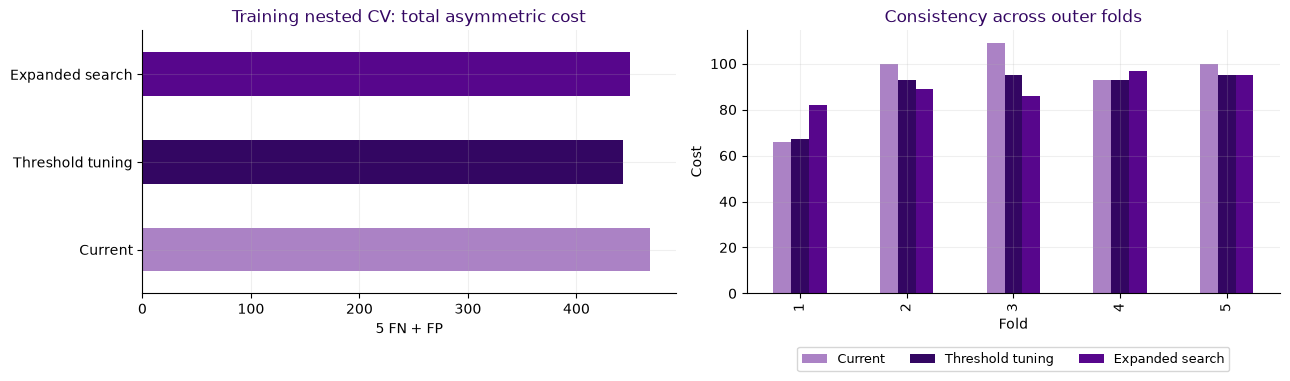

In [31]:
nested_predictions={name:np.empty(len(y_train),dtype=int) for name in
    ['Current model','Current model, threshold retuned','Expanded selection']}
nested_probabilities={name:np.empty(len(y_train)) for name in nested_predictions}
fold_rows=[];inner_tables=[];outer_choices=[]
for fold_number,(fit_idx,val_idx) in enumerate(outer_folds,1):
    X_fit=X_train.iloc[fit_idx];y_fit=y_train.iloc[fit_idx]
    X_val=X_train.iloc[val_idx];y_val=y_train.iloc[val_idx]
    print(f'Outer fold {fold_number}/5: selecting with inner folds only',flush=True)
    inner_table,_=inner_search(X_fit,y_fit,outer_groups[fit_idx])
    inner_tables.append(inner_table.assign(Outer_fold=fold_number))
    best=inner_table.iloc[0]
    selected_spec=improvement_specs[int(best.Number)]
    outer_choices.append(dict(Fold=fold_number,Name=selected_spec['name'],
        Number=int(best.Number),Threshold=float(best.Threshold),Inner_cost=int(best.Cost)))
    incumbent=make_improvement_model(incumbent_spec).fit(X_fit,y_fit)
    incumbent_p=incumbent.predict_proba(X_val)[:,1]
    retuned_t=float(inner_table.loc[inner_table.Number==0,'Threshold'].iloc[0])
    if int(best.Number)==0:
        selected_p=incumbent_p
    else:
        selected=make_improvement_model(selected_spec).fit(X_fit,y_fit)
        selected_p=selected.predict_proba(X_val)[:,1]
    for name,prob,t in [('Current model',incumbent_p,CURRENT_SPEC['threshold']),
        ('Current model, threshold retuned',incumbent_p,retuned_t),
        ('Expanded selection',selected_p,float(best.Threshold))]:
        pred=(prob>=t).astype(int)
        nested_predictions[name][val_idx]=pred
        nested_probabilities[name][val_idx]=prob
        row=metric_row(y_val,pred,prob)
        row.update(Strategy=name,Fold=fold_number,Threshold=t)
        fold_rows.append(row)
    print(f'Outer fold {fold_number}: selected {selected_spec["name"]}; '
          f'threshold {float(best.Threshold):.4f}',flush=True)
nested_fold_table=pd.DataFrame(fold_rows)
nested_summary=pd.DataFrame({name:metric_row(y_train,nested_predictions[name],
    nested_probabilities[name]) for name in nested_predictions}).T
display(nested_summary)
display(nested_fold_table[['Fold','Strategy','Cost','FN','FP','Recall','Precision','AP','Threshold']])
display(pd.DataFrame(outer_choices))
# Fold variation and paired costs are descriptive; repeated CV training sets overlap.
per_fold=nested_fold_table.pivot(index='Fold',columns='Strategy',values='Cost')
deltas=per_fold['Current model']-per_fold['Expanded selection']
gain=(nested_summary.loc['Current model','Cost']-
      nested_summary.loc['Expanded selection','Cost'])/nested_summary.loc['Current model','Cost']
print('Cost saved in each outer fold:',deltas.to_list())
print(f'Total nested-CV cost reduction: {gain:.1%}')
print('Folds with lower cost:',int((deltas>0).sum()),'of five')
short_labels={'Current model':'Current', 'Current model, threshold retuned':'Threshold tuning',
              'Expanded selection':'Expanded search'}
fig,ax=plt.subplots(1,2,figsize=(13,4))
nested_summary.rename(index=short_labels).Cost.plot.barh(ax=ax[0],
    color=[NYU_LIGHT_PURPLE,NYU_DARK_PURPLE,NYU_PURPLE])
ax[0].set(title='Training nested CV: total asymmetric cost',xlabel='5 FN + FP',ylabel='')
per_fold.rename(columns=short_labels).plot.bar(ax=ax[1],
    color=[NYU_LIGHT_PURPLE,NYU_DARK_PURPLE,NYU_PURPLE])
ax[1].set(title='Consistency across outer folds',ylabel='Cost')
ax[1].legend(loc='upper center',bbox_to_anchor=(.5,-.18),ncol=3,fontsize=9,title=None)
plt.tight_layout();plt.show()


The wider search reduces cost from 468 to 449, but simply tuning the reference cutoff gives 443. The extra search complexity does not beat the simpler tuned rule, so I keep this as a negative result. Each outer fold evaluates choices made in its own inner folds; prior exploration of these training rows still limits independence.

In [32]:
# After evaluating the selection procedure, choose a candidate using training only.
full_training_search,_=inner_search(X_train,y_train,outer_groups)
display(full_training_search)
best_full=full_training_search.iloc[0]
candidate_spec=improvement_specs[int(best_full.Number)]
candidate_threshold=float(best_full.Threshold)
candidate_pipeline=Pipeline([('decision',FixedThresholdClassifier(
    make_improvement_model(candidate_spec),threshold=candidate_threshold))])
candidate_pipeline.fit(X_train,y_train)
probe=X_train.iloc[:20].copy()
p=candidate_pipeline.predict_proba(probe)
assert p.shape==(20,2) and np.isfinite(p).all()
assert np.array_equal(candidate_pipeline.predict(probe),(p[:,1]>=candidate_threshold).astype(int))
probe['Id']=np.arange(len(probe))+100000000
assert np.allclose(candidate_pipeline.predict_proba(probe),p)
print('Training-only candidate:',candidate_spec['name'])
print(f'Follow-up candidate cutoff (provisional): {candidate_threshold:.4f}')
print('Candidate fitted rows:',len(X_train))
print('This is a training-only candidate; the later matched comparison chooses the final pipeline.')


,Number,Name,Cost,Cost_per_company,Threshold,AP,Brier
0,0,Current model,435,0.11287,0.12,0.744164,0.0295029
7,7,"Amounts plus ratios, weighted loss",443,0.114946,0.12,0.742349,0.029669
6,6,"Amounts plus ratios, larger leaves",450,0.116762,0.07,0.730374,0.0310714
5,5,"Amounts plus ratios, fifteen leaves",457,0.118578,0.12,0.738258,0.030295
4,4,"Amounts plus ratios, seven leaves",459,0.119097,0.06,0.740996,0.0298064
3,3,"Audited amounts, native missing values",459,0.119097,0.09,0.732127,0.0302464
2,2,"Normalized, no correlation removal",474,0.122989,0.07,0.717693,0.0324361
1,1,"Longer, smaller boosting steps",477,0.123768,0.09,0.729985,0.0302195


Training-only candidate: Current model
Follow-up candidate cutoff (provisional): 0.1200
Candidate fitted rows: 3854
This is a training-only candidate; the later matched comparison chooses the final pipeline.


The reference classifier now has a candidate cutoff of 0.12, rather than the earlier 0.1667. The first study used one reserved training subset; this study uses out-of-fold predictions across the full training set. A different validation sample and different fitted models can give a different lowest-cost cutoff. The 435 cost above is a selection result, not an independent estimate of performance.

I have not frozen two competing final thresholds. The stages are:

| Stage | Cutoff | What I use it for |
|---|---:|---|
| Early development reference | 0.1667 | Understand the cost trade-off on a reserved training subset |
| Follow-up candidate | 0.12 | Select a candidate using full-training out-of-fold predictions |
| Final final model, selected later | 0.15 | Use the final features and classifier settings chosen by the matched training comparisons |

The final model has different features and classifier settings, so its probabilities can also change. I select its cutoff along with those settings inside training folds, then freeze that entire pipeline before the final report.


<a id="testing-changes-motivated-by-the-missed-cases"></a>

### Testing changes motivated by the missed cases

I test two hypotheses from the errors: nonnegative-profit companies might need a different cutoff, or explicit profit/distress interactions might help capture debt and liquidity problems. Boosting can already learn interactions, so an explicit feature is not a guaranteed improvement.

I compare the original at 1/6, one tuned global cutoff, profit-group cutoffs, and three profit/distress interactions with one tuned cutoff. A group receives its own cutoff only with at least 50 inner-validation rows and 10 bankruptcies; otherwise it uses the global cutoff. Missing profit also uses the global cutoff.

The same five grouped outer folds evaluate cutoffs chosen from three inner folds. Classifier settings, correlation filtering, median filling and flags stay fixed. I compare paired costs and errors in the nonnegative-profit group. These hypotheses arose from explored development rows, so nesting separates selection from each outer fold without removing earlier training exploration.

Targeted comparison completed outer fold 1


Targeted comparison completed outer fold 2


Targeted comparison completed outer fold 3


Targeted comparison completed outer fold 4


Targeted comparison completed outer fold 5


,Cost,FN,FP,Recall,Precision,AP,Brier
Original cutoff 1/6,468,74,98,0.699187,0.637037,0.761423,0.0280221
Global cutoff tuned,443,56,163,0.772358,0.538244,0.761423,0.0280221
Profit-group cutoffs tuned,440,56,160,0.772358,0.542857,0.761423,0.0280221
Profit/distress interactions + tuned cutoff,432,48,192,0.804878,0.507692,0.76485,0.0276454


Rule,Global cutoff tuned,Original cutoff 1/6,Profit-group cutoffs tuned,Profit/distress interactions + tuned cutoff
Fold,,,,
1,67,66,71,64
2,93,100,90,96
3,95,109,86,71
4,93,93,96,105
5,95,100,97,96


,Fold,Global,Nonnegative_profit,Negative_profit,Missing_profit,Interactions
0,1,0.08,0.12,0.08,0.08,0.09
1,2,0.12,0.12,0.05,0.12,0.08
2,3,0.12,0.08,0.12,0.12,0.07
3,4,0.08,0.1,0.08,0.08,0.07
4,5,0.12,0.15,0.12,0.12,0.12


Rows  Bankruptcies  FN   FP    Recall  False_alarm_rate  Cost
Rule                                        Group                                                                            
Original cutoff 1/6                         Nonnegative profit  3063            98  47   25  0.520408          0.008432   260
                                            Negative profit      789           147  27   73  0.816327          0.113707   208
                                            Missing profit         2             1   0    0  1.000000          0.000000     0
Global cutoff tuned                         Nonnegative profit  3063            98  40   50  0.591837          0.016863   250
                                            Negative profit      789           147  16  113  0.891156          0.176012   193
                                            Missing profit         2             1   0    0  1.000000          0.000000     0
Profit-group cutoffs tuned                  Nonnegative profit  3063            98  42   40  0.571429          0.013491   250
                                            Negative profit      789           147  14  120  0.904762          0.186916   190
                                            Missing profit         2             1   0    0  1.000000          0.000000     0
Profit/distress interactions + tuned cutoff Nonnegative profit  3063            98  35   71  0.642857          0.023946   246
                                            Negative profit      789           147  13  121  0.911565          0.188474   186
                                            Missing profit         2             1   0    0  1.000000          0.000000     0

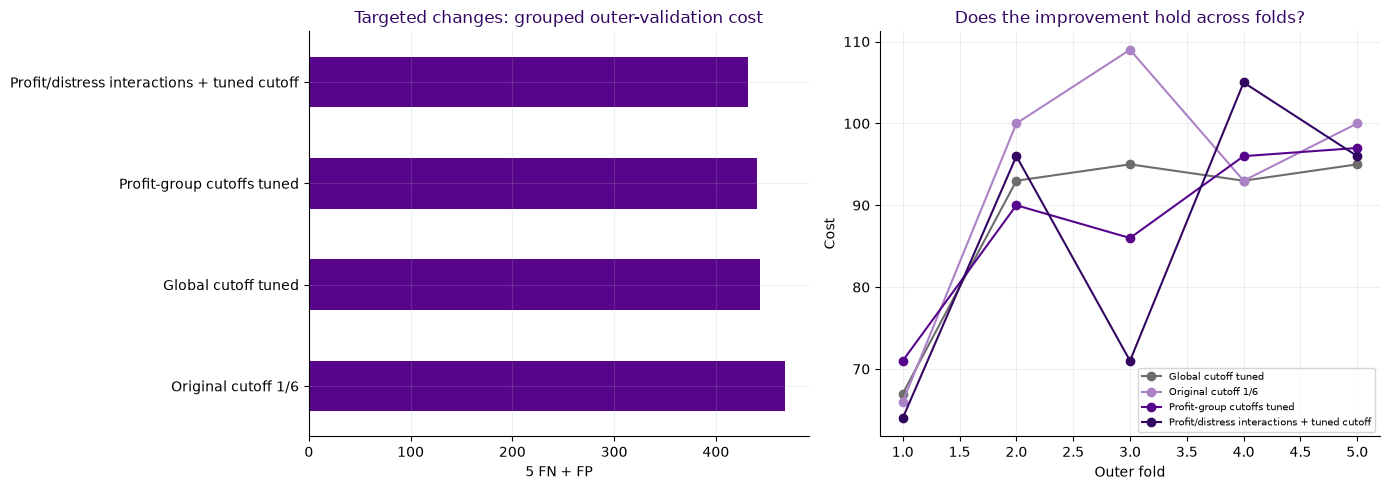

This targeted comparison uses training folds; the final selection comes later.


In [33]:
from threadpoolctl import threadpool_limits

targeted_threshold_grid = np.unique(np.r_[np.arange(.05, .36, .01), 1/6, .01, .03, .4, .5, .6, .8])
targeted_rule_names = ['Original cutoff 1/6', 'Global cutoff tuned',
    'Profit-group cutoffs tuned', 'Profit/distress interactions + tuned cutoff']
targeted_outer_probabilities = {name: np.empty(len(y_train)) for name in targeted_rule_names}
targeted_outer_predictions = {name: np.empty(len(y_train), dtype=int) for name in targeted_rule_names}
targeted_fold_rows = []; targeted_threshold_rows = []

def make_targeted_model(interactions=False):
    model = make_model('HistGradientBoostingClassifier', 'normalized', False,
        **CURRENT_SPEC['params'])
    if interactions:
        model.set_params(features=ProfitDistressFeatures(mode='normalized'))
    return model

def choose_targeted_cutoff(y, probability):
    choices = [(cost(y, (probability >= cutoff).astype(int)), float(cutoff))
        for cutoff in targeted_threshold_grid]
    return min(choices, key=lambda item: (item[0], -item[1]))[1]

def profit_groups(X):
    profit = X.num_13.replace([np.inf, -np.inf], np.nan)
    return np.select([profit.ge(0), profit.lt(0)], ['Nonnegative profit', 'Negative profit'],
        default='Missing profit')

with threadpool_limits(limits=1):
    for fold_number, (fit_idx, val_idx) in enumerate(outer_folds, 1):
        X_fit, y_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        fit_groups = outer_groups[fit_idx]
        assert not set(fit_groups) & set(outer_groups[val_idx])
        inner_folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
            random_state=31415).split(X_fit, y_fit, groups=fit_groups))
        inner_probabilities = {}
        fitted_outer_models = {}
        for name, interactions in [('Original', False), ('Interactions', True)]:
            inner_p = np.empty(len(y_fit))
            for inner_fit, inner_val in inner_folds:
                assert not set(fit_groups[inner_fit]) & set(fit_groups[inner_val])
                model = make_targeted_model(interactions).fit(X_fit.iloc[inner_fit], y_fit.iloc[inner_fit])
                inner_p[inner_val] = model.predict_proba(X_fit.iloc[inner_val])[:, 1]
            inner_probabilities[name] = inner_p
            fitted_outer_models[name] = make_targeted_model(interactions).fit(X_fit, y_fit)
        global_cutoff = choose_targeted_cutoff(y_fit, inner_probabilities['Original'])
        interaction_cutoff = choose_targeted_cutoff(y_fit, inner_probabilities['Interactions'])
        fitting_profit_groups = profit_groups(X_fit)
        validation_profit_groups = profit_groups(X_val)
        group_cutoffs = {}
        for group in ['Nonnegative profit', 'Negative profit', 'Missing profit']:
            mask = fitting_profit_groups == group
            sufficient = int(mask.sum()) >= 50 and int(y_fit.to_numpy()[mask].sum()) >= 10
            group_cutoffs[group] = (choose_targeted_cutoff(y_fit.to_numpy()[mask],
                inner_probabilities['Original'][mask]) if sufficient else global_cutoff)
        original_p = fitted_outer_models['Original'].predict_proba(X_val)[:, 1]
        interaction_p = fitted_outer_models['Interactions'].predict_proba(X_val)[:, 1]
        group_cutoff_array = np.asarray([group_cutoffs[g] for g in validation_profit_groups])
        rules = {
            'Original cutoff 1/6': (original_p, original_p >= 1/6),
            'Global cutoff tuned': (original_p, original_p >= global_cutoff),
            'Profit-group cutoffs tuned': (original_p, original_p >= group_cutoff_array),
            'Profit/distress interactions + tuned cutoff':
                (interaction_p, interaction_p >= interaction_cutoff)}
        for rule_name, (probability, prediction) in rules.items():
            targeted_outer_probabilities[rule_name][val_idx] = probability
            targeted_outer_predictions[rule_name][val_idx] = prediction.astype(int)
            row = metric_row(y_val, prediction.astype(int), probability)
            row.update(Rule=rule_name, Fold=fold_number)
            targeted_fold_rows.append(row)
        targeted_threshold_rows.append(dict(Fold=fold_number, Global=global_cutoff,
            Nonnegative_profit=group_cutoffs['Nonnegative profit'],
            Negative_profit=group_cutoffs['Negative profit'],
            Missing_profit=group_cutoffs['Missing profit'], Interactions=interaction_cutoff))
        print('Targeted comparison completed outer fold', fold_number, flush=True)

targeted_summary = pd.DataFrame({name: metric_row(y_train, targeted_outer_predictions[name],
    targeted_outer_probabilities[name]) for name in targeted_rule_names}).T
targeted_fold_costs = pd.DataFrame(targeted_fold_rows).pivot(index='Fold', columns='Rule', values='Cost')
targeted_group_rows = []
for name in targeted_rule_names:
    for group in ['Nonnegative profit', 'Negative profit', 'Missing profit']:
        mask = profit_groups(X_train) == group
        y = y_train.to_numpy()[mask]; d = targeted_outer_predictions[name][mask]
        positive = int(y.sum()); negative = len(y)-positive
        fn = int(((y == 1) & (d == 0)).sum()); fp = int(((y == 0) & (d == 1)).sum())
        targeted_group_rows.append(dict(Rule=name, Group=group, Rows=len(y), Bankruptcies=positive,
            FN=fn, FP=fp, Recall=1-fn/positive if positive else np.nan,
            False_alarm_rate=fp/negative if negative else np.nan, Cost=5*fn+fp))
targeted_group_table = pd.DataFrame(targeted_group_rows).set_index(['Rule', 'Group'])
display(targeted_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
display(targeted_fold_costs)
display(pd.DataFrame(targeted_threshold_rows))
display(targeted_group_table)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
targeted_summary.Cost.plot.barh(ax=axes[0], color=NYU_PURPLE)
axes[0].set(title='Targeted changes: grouped outer-validation cost', xlabel='5 FN + FP')
targeted_fold_costs.plot(ax=axes[1], marker='o',
    color=[NYU_GRAY, NYU_LIGHT_PURPLE, NYU_PURPLE, NYU_DARK_PURPLE])
axes[1].set(title='Does the improvement hold across folds?', xlabel='Outer fold', ylabel='Cost')
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print('This targeted comparison uses training folds; the final selection comes later.')


Profit-group cutoffs cost 440 versus 443 for one global cutoff, a small saving of three units. Profit/distress interactions reduce total cost to 432, but win only two of five paired folds against the tuned reference. I keep both studies, recognize that the gains are uneven, and next test the liquidity hypothesis. These scores come from explored training folds, not the test or holdout.

<a id="testing-the-liquidity-quality-features"></a>

### Testing the liquidity-quality features

I test six explicit relationships: near-cash/short-debt, quick-assets/short-debt, converted inventory/current-assets, short-debt/total-liabilities, approximate DSO, and a quick-asset shortfall when working capital is nonnegative. The last asks whether a reassuring working-capital total hides limited liquid resources. Some features are algebraically related to existing ratios; the question is whether making them explicit helps small boosting trees.

I keep the classifier settings and preprocessing fixed. The same five outer and three inner grouped folds let each version choose a global cutoff, then compare outer predictions. I also report the six-feature model at 1/6 to distinguish feature changes from cutoff changes and check the apparently healthy subgroup.

Retained earnings and sales growth remain existing inputs. I do not add more flags for every descriptive pattern. The later matched comparison gives both finalists classifier tuning before the final choice.

Liquidity comparison completed outer fold 1


Liquidity comparison completed outer fold 2


Liquidity comparison completed outer fold 3


Liquidity comparison completed outer fold 4


Liquidity comparison completed outer fold 5


,Cost,FN,FP,Recall,Precision,AP,Brier
Original at 1/6,468,74,98,0.699187,0.637037,0.761423,0.0280221
Original + tuned cutoff,443,56,163,0.772358,0.538244,0.761423,0.0280221
Liquidity features at 1/6,424,66,94,0.731707,0.656934,0.779895,0.0266266
Liquidity features + tuned cutoff,403,50,153,0.796748,0.561605,0.779895,0.0266266


Model,Liquidity features + tuned cutoff,Liquidity features at 1/6,Original + tuned cutoff,Original at 1/6
Fold,,,,
1,64,52,67,66
2,84,99,93,100
3,78,85,95,109
4,97,108,93,93
5,80,80,95,100


,Fold,Original,Liquidity features
0,1,0.08,0.08
1,2,0.12,0.09
2,3,0.12,0.1
3,4,0.08,0.1
4,5,0.12,0.11


Rows  Bankruptcies  FN   FP    Recall  Cost
Model                             Group                                                                            
Original at 1/6                   Nonnegative profit + working capital  2671            66  35   18  0.469697   193
                                  Other companies                       1183           180  39   80  0.783333   275
Original + tuned cutoff           Nonnegative profit + working capital  2671            66  29   33  0.560606   178
                                  Other companies                       1183           180  27  130  0.850000   265
Liquidity features at 1/6         Nonnegative profit + working capital  2671            66  33   16  0.500000   181
                                  Other companies                       1183           180  33   78  0.816667   243
Liquidity features + tuned cutoff Nonnegative profit + working capital  2671            66  26   31  0.606061   161
                                  Other companies                       1183           180  24  122  0.866667   242

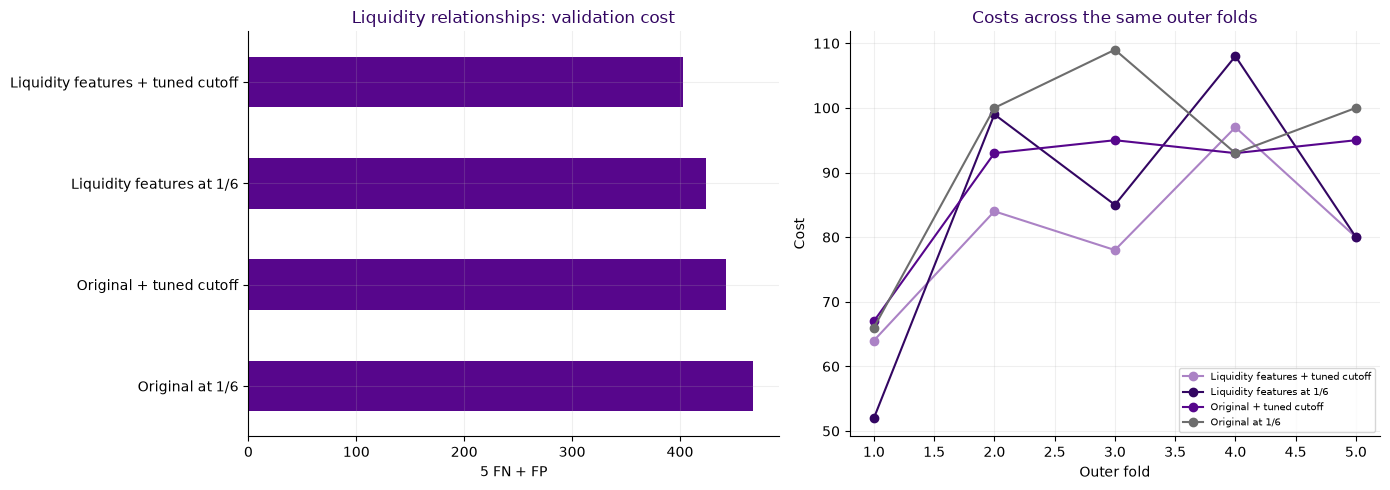

This feature experiment uses training folds; the later matched search makes the final selection.


In [34]:
from threadpoolctl import threadpool_limits
liquidity_names = ['Original at 1/6', 'Original + tuned cutoff',
    'Liquidity features at 1/6', 'Liquidity features + tuned cutoff']
liquidity_probabilities = {name: np.empty(len(y_train)) for name in liquidity_names}
liquidity_predictions = {name: np.empty(len(y_train), dtype=int) for name in liquidity_names}
liquidity_fold_rows = []; liquidity_cutoff_rows = []

def make_liquidity_model(add_features=False):
    m = make_model('HistGradientBoostingClassifier', 'normalized', False, **CURRENT_SPEC['params'])
    if add_features: m.set_params(features=LiquidityQualityFeatures(mode='normalized'))
    return m

with threadpool_limits(limits=1):
    for fold_number, (fit_idx, val_idx) in enumerate(outer_folds, 1):
        X_fit, y_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        fit_groups = outer_groups[fit_idx]
        assert not set(fit_groups) & set(outer_groups[val_idx])
        inner_folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
            random_state=31415).split(X_fit, y_fit, groups=fit_groups))
        cutoff_record = {'Fold': fold_number}
        for model_name, add_features in [('Original', False), ('Liquidity features', True)]:
            p_inner = np.empty(len(y_fit))
            for inner_fit, inner_val in inner_folds:
                assert not set(fit_groups[inner_fit]) & set(fit_groups[inner_val])
                m = make_liquidity_model(add_features).fit(X_fit.iloc[inner_fit], y_fit.iloc[inner_fit])
                p_inner[inner_val] = m.predict_proba(X_fit.iloc[inner_val])[:, 1]
            cutoff = choose_targeted_cutoff(y_fit, p_inner)
            cutoff_record[model_name] = cutoff
            m = make_liquidity_model(add_features).fit(X_fit, y_fit)
            p_val = m.predict_proba(X_val)[:, 1]
            for name, rule_cutoff in [(model_name+' at 1/6', 1/6), (model_name+' + tuned cutoff', cutoff)]:
                d = (p_val >= rule_cutoff).astype(int)
                liquidity_probabilities[name][val_idx] = p_val
                liquidity_predictions[name][val_idx] = d
                row = metric_row(y_val, d, p_val); row.update(Model=name, Fold=fold_number)
                liquidity_fold_rows.append(row)
        liquidity_cutoff_rows.append(cutoff_record)
        print('Liquidity comparison completed outer fold', fold_number, flush=True)
liquidity_summary = pd.DataFrame({name: metric_row(y_train, liquidity_predictions[name],
    liquidity_probabilities[name]) for name in liquidity_names}).T
liquidity_fold_costs = pd.DataFrame(liquidity_fold_rows).pivot(index='Fold', columns='Model', values='Cost')
liquidity_group_rows = []
apparently_healthy_train = (X_train.num_13.ge(0) & X_train.num_19.ge(0)).to_numpy()
for name in liquidity_names:
    for group, mask in [('Nonnegative profit + working capital', apparently_healthy_train),
                        ('Other companies', ~apparently_healthy_train)]:
        actual = y_train.to_numpy()[mask]; prediction = liquidity_predictions[name][mask]
        fn = int(((actual == 1) & (prediction == 0)).sum()); fp = int(((actual == 0) & (prediction == 1)).sum())
        positives = int(actual.sum())
        liquidity_group_rows.append(dict(Model=name, Group=group, Rows=int(mask.sum()),
            Bankruptcies=positives, FN=fn, FP=fp, Recall=1-fn/positives if positives else np.nan,
            Cost=5*fn+fp))
liquidity_group_table = pd.DataFrame(liquidity_group_rows).set_index(['Model', 'Group'])
display(liquidity_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
display(liquidity_fold_costs)
display(pd.DataFrame(liquidity_cutoff_rows))
display(liquidity_group_table)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
liquidity_summary.Cost.plot.barh(ax=axes[0], color=NYU_PURPLE)
axes[0].set(title='Liquidity relationships: validation cost', xlabel='5 FN + FP')
liquidity_fold_costs.plot(ax=axes[1], marker='o',
    color=[NYU_LIGHT_PURPLE, NYU_DARK_PURPLE, NYU_PURPLE, NYU_GRAY])
axes[1].set(title='Costs across the same outer folds', xlabel='Outer fold', ylabel='Cost')
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print('This feature experiment uses training folds; the later matched search makes the final selection.')


At the fixed 1/6 cutoff, the six-feature bundle costs 424 rather than 468, with eight fewer missed bankruptcies and four fewer false alarms. When both versions can tune their cutoff, the fair comparison is 403 versus 443. The bundle wins four of the five paired folds in that comparison.

In the nonnegative-profit, nonnegative-working-capital group, recall rises from about 56.1% to 60.6% after both cutoffs are tuned, but the model still misses 26 of the 66 bankruptcies. It helps rather than solves that problem. The benefit belongs to the whole feature bundle and decision procedure; this does not establish that each new ratio helps individually. I check a smaller bundle next and give both finalists equal classifier tuning later.


<a id="comparing-the-smaller-liquidity-bundle"></a>

#### Comparing the smaller liquidity bundle

I also test a four-feature ablation: cash/short-debt, quick-assets/short-debt, short-debt/total-debt, and the quick-asset shortfall when working capital is nonnegative. It leaves out inventory concentration and collection days. The earlier scale checks support the 365 conversion. Here I ask whether these two relationships add predictive information beyond the other four features.

I keep the same classifier settings, folds and cutoff selection as the six-feature experiment. If the smaller version is as good, I have a reason to prefer simpler features. If it is worse, that is useful evidence too, with the same limits from exploring this training pool.


Liquidity comparison completed outer fold 1


Liquidity comparison completed outer fold 2


Liquidity comparison completed outer fold 3


Liquidity comparison completed outer fold 4


Liquidity comparison completed outer fold 5


,Cost,FN,FP,Recall,Precision,AP,Brier
Original at 1/6,468,74,98,0.699187,0.637037,0.761423,0.0280221
Original + tuned cutoff,443,56,163,0.772358,0.538244,0.761423,0.0280221
Checked liquidity features at 1/6,449,71,94,0.711382,0.650558,0.763276,0.0278245
Checked liquidity features + tuned cutoff,459,60,159,0.756098,0.53913,0.763276,0.0278245


Model,Checked liquidity features + tuned cutoff,Checked liquidity features at 1/6,Original + tuned cutoff,Original at 1/6
Fold,,,,
1,72,50,67,66
2,94,102,93,100
3,97,96,95,109
4,111,117,93,93
5,85,84,95,100


,Fold,Original,Checked liquidity features
0,1,0.08,0.08
1,2,0.12,0.07
2,3,0.12,0.15
3,4,0.08,0.11
4,5,0.12,0.11


Rows  Bankruptcies  FN   FP    Recall  Cost
Model                                     Group                                                                            
Original at 1/6                           Nonnegative profit + working capital  2671            66  35   18  0.469697   193
                                          Other companies                       1183           180  39   80  0.783333   275
Original + tuned cutoff                   Nonnegative profit + working capital  2671            66  29   33  0.560606   178
                                          Other companies                       1183           180  27  130  0.850000   265
Checked liquidity features at 1/6         Nonnegative profit + working capital  2671            66  35   14  0.469697   189
                                          Other companies                       1183           180  36   80  0.800000   260
Checked liquidity features + tuned cutoff Nonnegative profit + working capital  2671            66  31   34  0.530303   189
                                          Other companies                       1183           180  29  125  0.838889   270

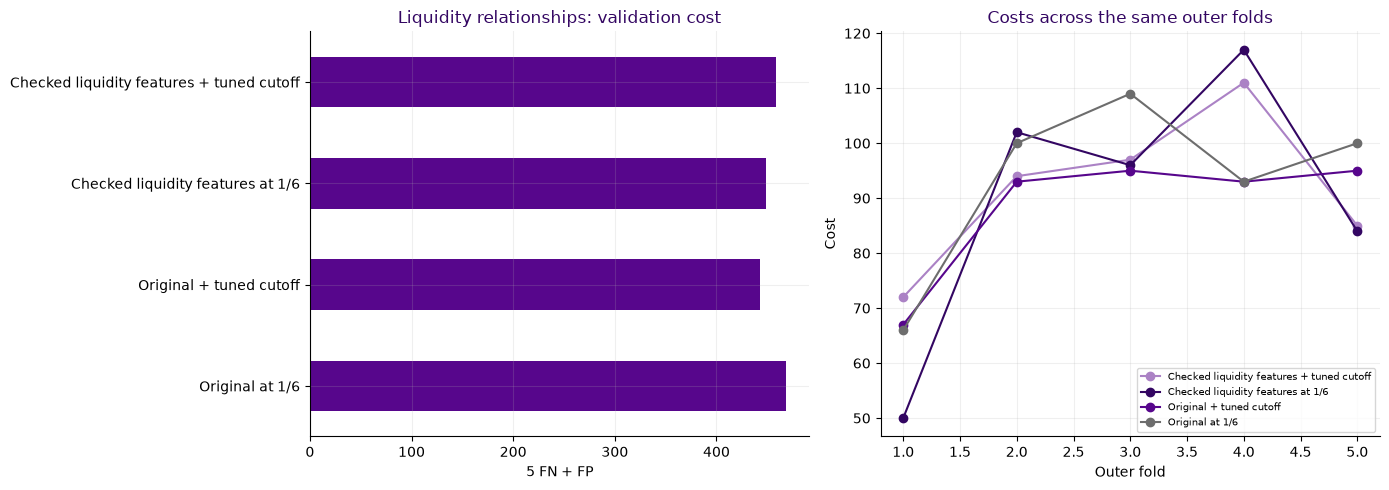

This feature experiment uses training folds; the later matched search makes the final selection.


In [35]:
from threadpoolctl import threadpool_limits
liquidity_names = ['Original at 1/6', 'Original + tuned cutoff',
    'Checked liquidity features at 1/6', 'Checked liquidity features + tuned cutoff']
liquidity_probabilities = {name: np.empty(len(y_train)) for name in liquidity_names}
liquidity_predictions = {name: np.empty(len(y_train), dtype=int) for name in liquidity_names}
liquidity_fold_rows = []; liquidity_cutoff_rows = []

def make_liquidity_model(add_features=False):
    m = make_model('HistGradientBoostingClassifier', 'normalized', False, **CURRENT_SPEC['params'])
    if add_features: m.set_params(features=LiquidityCheckedFeatures(mode='normalized'))
    return m

with threadpool_limits(limits=1):
    for fold_number, (fit_idx, val_idx) in enumerate(outer_folds, 1):
        X_fit, y_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        fit_groups = outer_groups[fit_idx]
        assert not set(fit_groups) & set(outer_groups[val_idx])
        inner_folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
            random_state=31415).split(X_fit, y_fit, groups=fit_groups))
        cutoff_record = {'Fold': fold_number}
        for model_name, add_features in [('Original', False), ('Checked liquidity features', True)]:
            p_inner = np.empty(len(y_fit))
            for inner_fit, inner_val in inner_folds:
                assert not set(fit_groups[inner_fit]) & set(fit_groups[inner_val])
                m = make_liquidity_model(add_features).fit(X_fit.iloc[inner_fit], y_fit.iloc[inner_fit])
                p_inner[inner_val] = m.predict_proba(X_fit.iloc[inner_val])[:, 1]
            cutoff = choose_targeted_cutoff(y_fit, p_inner)
            cutoff_record[model_name] = cutoff
            m = make_liquidity_model(add_features).fit(X_fit, y_fit)
            p_val = m.predict_proba(X_val)[:, 1]
            for name, rule_cutoff in [(model_name+' at 1/6', 1/6), (model_name+' + tuned cutoff', cutoff)]:
                d = (p_val >= rule_cutoff).astype(int)
                liquidity_probabilities[name][val_idx] = p_val
                liquidity_predictions[name][val_idx] = d
                row = metric_row(y_val, d, p_val); row.update(Model=name, Fold=fold_number)
                liquidity_fold_rows.append(row)
        liquidity_cutoff_rows.append(cutoff_record)
        print('Liquidity comparison completed outer fold', fold_number, flush=True)
liquidity_summary = pd.DataFrame({name: metric_row(y_train, liquidity_predictions[name],
    liquidity_probabilities[name]) for name in liquidity_names}).T
liquidity_fold_costs = pd.DataFrame(liquidity_fold_rows).pivot(index='Fold', columns='Model', values='Cost')
liquidity_group_rows = []
apparently_healthy_train = (X_train.num_13.ge(0) & X_train.num_19.ge(0)).to_numpy()
for name in liquidity_names:
    for group, mask in [('Nonnegative profit + working capital', apparently_healthy_train),
                        ('Other companies', ~apparently_healthy_train)]:
        actual = y_train.to_numpy()[mask]; prediction = liquidity_predictions[name][mask]
        fn = int(((actual == 1) & (prediction == 0)).sum()); fp = int(((actual == 0) & (prediction == 1)).sum())
        positives = int(actual.sum())
        liquidity_group_rows.append(dict(Model=name, Group=group, Rows=int(mask.sum()),
            Bankruptcies=positives, FN=fn, FP=fp, Recall=1-fn/positives if positives else np.nan,
            Cost=5*fn+fp))
liquidity_group_table = pd.DataFrame(liquidity_group_rows).set_index(['Model', 'Group'])
display(liquidity_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
display(liquidity_fold_costs)
display(pd.DataFrame(liquidity_cutoff_rows))
display(liquidity_group_table)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
liquidity_summary.Cost.plot.barh(ax=axes[0], color=NYU_PURPLE)
axes[0].set(title='Liquidity relationships: validation cost', xlabel='5 FN + FP')
liquidity_fold_costs.plot(ax=axes[1], marker='o',
    color=[NYU_LIGHT_PURPLE, NYU_DARK_PURPLE, NYU_PURPLE, NYU_GRAY])
axes[1].set(title='Costs across the same outer folds', xlabel='Outer fold', ylabel='Cost')
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print('This feature experiment uses training folds; the later matched search makes the final selection.')


The four-feature bundle gives cost 449 at the fixed cutoff, below the reference's 468. However, with each cutoff selected in inner folds it costs 459, above the tuned reference's 443 and the six-feature bundle's 403. The smaller version therefore does not give a convincing improvement in this comparison. Correcting the units was necessary for interpretation; omitting those two relationships does not make the model better by itself.


<a id="checking-the-predicted-probabilities"></a>

## Checking the predicted probabilities

Good ranking does not necessarily mean good probabilities. A company assigned 20% risk should belong to a group where roughly 20% go bankrupt. I compare the existing boosting model with a sigmoid-calibrated version on the same five outer training folds. Calibration is fitted with three grouped inner folds, without the outer validation labels.

I report Brier score and log loss (lower is better), AP, and cost at the same 1/6 cutoff. The reliability table includes company and bankruptcy counts, so a small bin does not look more convincing than it is. This is a fixed follow-up check, not another search on the test set.

Reference: [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).

,Brier,Log_loss,AP,Cost
Original,0.0280221,0.106393,0.761423,468
Sigmoid calibrated,0.0278577,0.105566,0.760341,448


,Fold,Model,Brier,Log_loss,AP,Cost
0,1,Original,0.0219734,0.0820748,0.845776,66
1,1,Sigmoid calibrated,0.0223016,0.0891455,0.845776,70
2,2,Original,0.0284892,0.113234,0.733954,100
3,2,Sigmoid calibrated,0.0288207,0.111351,0.733954,94
4,3,Original,0.0299889,0.105231,0.767771,109
5,3,Sigmoid calibrated,0.0288837,0.102072,0.767771,92
6,4,Original,0.0307449,0.116691,0.731408,93
7,4,Sigmoid calibrated,0.0298723,0.111695,0.731408,94
8,5,Original,0.0289152,0.114741,0.741643,100
9,5,Sigmoid calibrated,0.0294122,0.113579,0.741643,98


,bin,Companies,Bankruptcies,Mean_probability,Observed_rate,Model,Rate_low,Rate_high
0,"(-0.0008680000000000001, 0.00112]",771,0,0.000634202,0,Original,0,0.00495792
1,"(0.00112, 0.00273]",771,1,0.00181653,0.00129702,Original,0.000228986,0.0073101
2,"(0.00273, 0.00693]",770,6,0.00444459,0.00779221,Original,0.00357594,0.0168954
3,"(0.00693, 0.0235]",771,21,0.0130274,0.0272374,Original,0.0178827,0.0412798
4,"(0.0235, 0.998]",771,218,0.249243,0.28275,Original,0.252099,0.315554
5,"(-0.00043599999999999997, 0.00392]",771,0,0.00231839,0,Sigmoid calibrated,0,0.00495792
6,"(0.00392, 0.0084]",771,2,0.00593812,0.00259403,Sigmoid calibrated,0.000711651,0.00940861
7,"(0.0084, 0.0185]",770,5,0.0125694,0.00649351,Sigmoid calibrated,0.00277669,0.0151102
8,"(0.0185, 0.0511]",771,21,0.0309392,0.0272374,Sigmoid calibrated,0.0178827,0.0412798
9,"(0.0511, 0.996]",771,218,0.292261,0.28275,Sigmoid calibrated,0.252099,0.315554


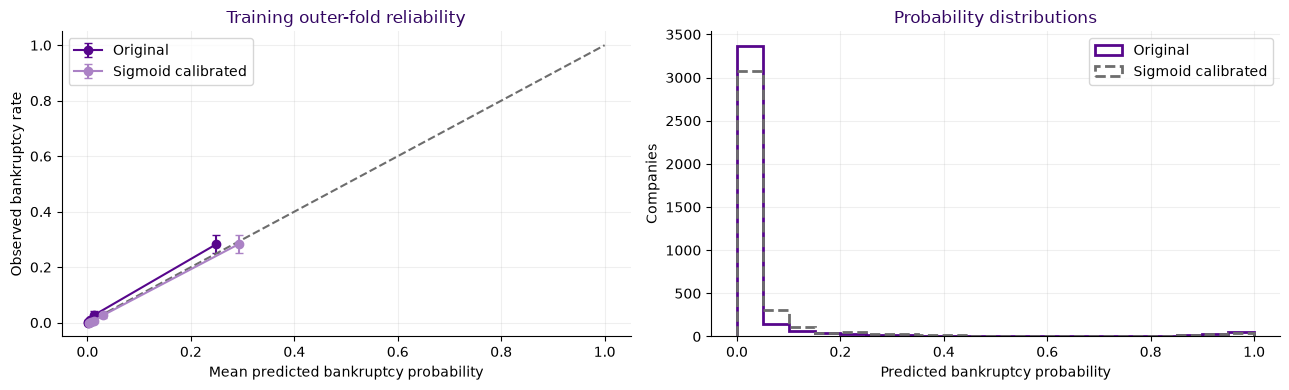

This calibration experiment compares training-fold probabilities at a fixed cutoff.


In [36]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss
from threadpoolctl import threadpool_limits

probability_check = {name: np.empty(len(y_train)) for name in ['Original', 'Sigmoid calibrated']}
probability_fold_rows = []
with threadpool_limits(limits=1):
    for fold_number, (fit_idx, val_idx) in enumerate(outer_folds, 1):
        X_fit, y_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        inner_calibration = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
            random_state=INNER_SEED).split(X_fit, y_fit, groups=outer_groups[fit_idx]))
        for inner_fit, inner_val in inner_calibration:
            assert not set(outer_groups[fit_idx][inner_fit]) & set(outer_groups[fit_idx][inner_val])
        base = make_improvement_model(incumbent_spec)
        original_model = clone(base).fit(X_fit, y_fit)
        calibrated_model = CalibratedClassifierCV(estimator=clone(base), method='sigmoid',
            cv=inner_calibration, ensemble=False, n_jobs=1).fit(X_fit, y_fit)
        for name, model in [('Original', original_model), ('Sigmoid calibrated', calibrated_model)]:
            p = model.predict_proba(X_val)[:, 1]
            probability_check[name][val_idx] = p
            probability_fold_rows.append(dict(Fold=fold_number, Model=name,
                Brier=brier_score_loss(y_val, p), Log_loss=log_loss(y_val, p),
                AP=average_precision_score(y_val, p), Cost=cost(y_val, (p >= 1/6).astype(int))))
probability_summary = pd.DataFrame({name: dict(
    Brier=brier_score_loss(y_train, p), Log_loss=log_loss(y_train, p),
    AP=average_precision_score(y_train, p), Cost=cost(y_train, (p >= 1/6).astype(int)))
    for name, p in probability_check.items()}).T
display(probability_summary)
probability_fold_table = pd.DataFrame(probability_fold_rows)
display(probability_fold_table)
reliability_rows = []
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, p in probability_check.items():
    bins = pd.qcut(p, q=5, duplicates='drop')
    table = pd.DataFrame({'bin': bins, 'probability': p, 'bankrupt': np.asarray(y_train)}).groupby(
        'bin', observed=True).agg(Companies=('bankrupt', 'size'),
        Bankruptcies=('bankrupt', 'sum'), Mean_probability=('probability', 'mean'),
        Observed_rate=('bankrupt', 'mean')).reset_index()
    table['Model'] = name
    # Wilson intervals describe each bin; repeated CV fits still share training data.
    count = table.Companies.to_numpy()
    rate = table.Observed_rate.to_numpy()
    z = 1.96
    center = (rate + z*z/(2*count))/(1 + z*z/count)
    half = z*np.sqrt(rate*(1-rate)/count + z*z/(4*count*count))/(1 + z*z/count)
    table['Rate_low'], table['Rate_high'] = center-half, center+half
    reliability_rows.append(table)
    ax[0].errorbar(table.Mean_probability, rate,
        yerr=np.vstack([rate-table.Rate_low, table.Rate_high-rate]), fmt='o-', capsize=3, label=name)
    ax[1].hist(p, bins=np.linspace(0, 1, 21), histtype='step', linewidth=2,
        linestyle='-' if name == 'Original' else '--',
        color=NYU_PURPLE if name == 'Original' else NYU_GRAY, label=name)
reliability_table = pd.concat(reliability_rows, ignore_index=True)
display(reliability_table)
ax[0].plot([0, 1], [0, 1], '--', color=NYU_GRAY)
ax[0].set(xlabel='Mean predicted bankruptcy probability', ylabel='Observed bankruptcy rate',
    title='Training outer-fold reliability')
ax[1].set(xlabel='Predicted bankruptcy probability', ylabel='Companies', title='Probability distributions')
for axis in ax: axis.legend()
plt.tight_layout(); plt.show()
print('This calibration experiment compares training-fold probabilities at a fixed cutoff.')

Sigmoid calibration slightly improves Brier score (0.02802 to 0.02786) and log loss (0.1064 to 0.1056). At the fixed 1/6 cutoff, cost falls from 468 to 448, while pooled AP is slightly lower. This is a useful probability check, but it does not compare the two finalists after matched classifier and cutoff tuning. I retain it as a separate study and keep the simpler uncalibrated finalists for that comparison.

<a id="checking-whether-shuffled-labels-give-similar-results"></a>

## Checking whether shuffled labels give similar results

I shuffle the bankruptcy labels to check whether a simple fixed model predicts better with the real labels than it does when the labels are randomized. I use logistic regression with C=1 and the original financial features; I do not repeat the model search or pick a winner in this test.

I keep one row per identical training profile, after checking that duplicate labels agree. I fix three K-fold splits from row positions and reuse them for the real labels and 99 shuffles. The whole pipeline is refitted in each fold and shuffle. I use AP because bankruptcies are rare.

The test assumes labels could be exchanged among independent profiles if there were no predictive relationship. The file does not let me verify dependence across industries, owners, or years. With 99 shuffles, the smallest possible p-value is 0.01. This checks a fixed reference model; it does not account for the entire earlier search or prove that boosting is the best model.

Reference: [label-permutation test](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.permutation_test_score.html).

,0
Profiles,3822
Bankrupt,245
Removed_repeat_rows,32
Observed_mean_fold_AP,0.596359
Null_mean_AP,0.0680894
Null_95th_percentile_AP,0.0789291
Permutations,99
P_value,0.01


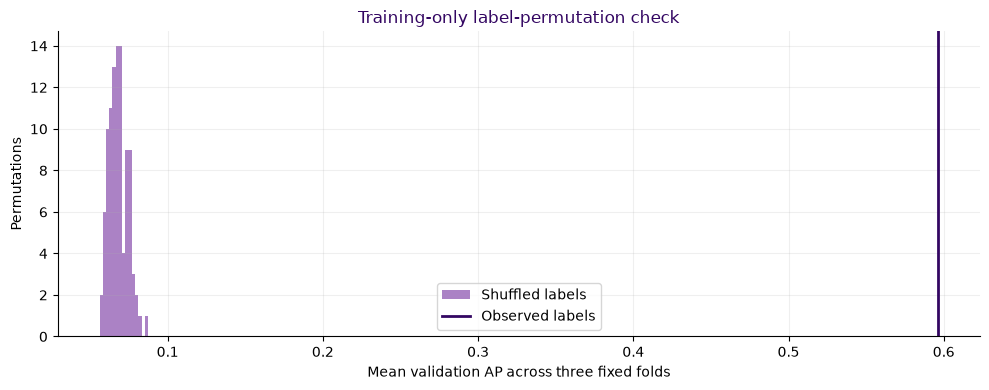

Exploratory association check only: no test/holdout access and no model replacement.


In [37]:
from sklearn.model_selection import KFold, permutation_test_score

permutation_groups = profile_groups(X_train)
profile_label_counts = pd.DataFrame({'profile': permutation_groups,
    'label': np.asarray(y_train)}).groupby('profile').label.nunique()
assert profile_label_counts.max() == 1, 'Conflicting duplicate labels need a separate permutation design.'
unique_mask = ~pd.Series(permutation_groups).duplicated().to_numpy()
X_permutation = X_train.loc[unique_mask].reset_index(drop=True)
y_permutation = y_train.loc[unique_mask].reset_index(drop=True)
permutation_folds = list(KFold(n_splits=3, shuffle=True,
    random_state=20261007).split(X_permutation))
permutation_reference = make_model('LogisticRegression', mode='raw', C=1)
with threadpool_limits(limits=1):
    permutation_observed_ap, permutation_null_ap, permutation_pvalue = permutation_test_score(
        permutation_reference, X_permutation, y_permutation, cv=permutation_folds,
        scoring='average_precision', n_permutations=99, n_jobs=1, random_state=20261007)
permutation_results = dict(Profiles=len(X_permutation), Bankrupt=int(y_permutation.sum()),
    Removed_repeat_rows=int((~unique_mask).sum()), Observed_mean_fold_AP=float(permutation_observed_ap),
    Null_mean_AP=float(permutation_null_ap.mean()),
    Null_95th_percentile_AP=float(np.quantile(permutation_null_ap, .95)),
    Permutations=len(permutation_null_ap), P_value=float(permutation_pvalue))
display(pd.Series(permutation_results))
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(permutation_null_ap, bins=15, color=NYU_LIGHT_PURPLE, label='Shuffled labels')
ax.axvline(permutation_observed_ap, color=NYU_DARK_PURPLE, linewidth=2, label='Observed labels')
ax.set(xlabel='Mean validation AP across three fixed folds', ylabel='Permutations',
    title='Training-only label-permutation check')
ax.legend(); plt.tight_layout(); plt.show()
print('Exploratory association check only: no test/holdout access and no model replacement.')

The fixed logistic model has validation AP of 0.5964. Shuffled labels give average AP of 0.0681, with a 95th percentile of 0.0789. None of the 99 shuffled scores reaches the real-label score, giving p = 0.01, not zero. The check uses 3,822 distinct training profiles, including 245 bankruptcies, after removing 32 repeated rows.

This supports a predictive relationship under the test's assumptions. It does not establish causality, prove boosting beats logistic regression, or guarantee the same result for next year's companies. It also does not validate all the choices made during the earlier exploration.

<a id="choosing-between-the-two-final-candidates"></a>

## Choosing between the two final candidates

I compare the original calculated features with the six liquidity relationships. Both receive the same cutoff grid, two five-fold grouped arrangements (20261004 and 20261011) and three inner folds. Classifier settings are fixed here; the next step tunes them equally.

Inner validation predictions choose each cutoff; outer rows evaluate that choice. Every fitting fold learns its own filter, medians and flags. I choose the lower combined cost, keeping the original features on an exact tie.

The second arrangement checks sensitivity using the same training companies. Combined cost therefore counts each company twice; it is not performance on twice as many distinct companies. This gives a provisional preference, which the equal-budget classifier search checks next.

Final comparison: seed 20261004, fold 1/5 complete


Final comparison: seed 20261004, fold 2/5 complete


Final comparison: seed 20261004, fold 3/5 complete


Final comparison: seed 20261004, fold 4/5 complete


Final comparison: seed 20261004, fold 5/5 complete


Final comparison: seed 20261011, fold 1/5 complete


... (5 outputs left out)

Model          Original fixed 1/6  Original tuned  Six numeric features tuned
Seed     Fold                                                                
20261004 1                     66              67                          64
         2                    100              93                          84
         3                    109              95                          78
         4                     93              93                          97
         5                    100              95                          80
20261011 1                    117             133                         123
         2                    110             101                          98
         3                     95              92                          88
         4                     60              68                          73
         5                    100             102                          93

,Cost,FN,FP
Model,,,
Original fixed 1/6,950,149,205
Original tuned,939,124,319
Six numeric features tuned,878,116,298


Selected from training validation: Six numeric features tuned
Six-feature wins against tuned original: 8 of 10 folds


Training-only final cutoff: 0.08000000000000002
Cutoff-fitting OOF cost (optimized, not independent): 426


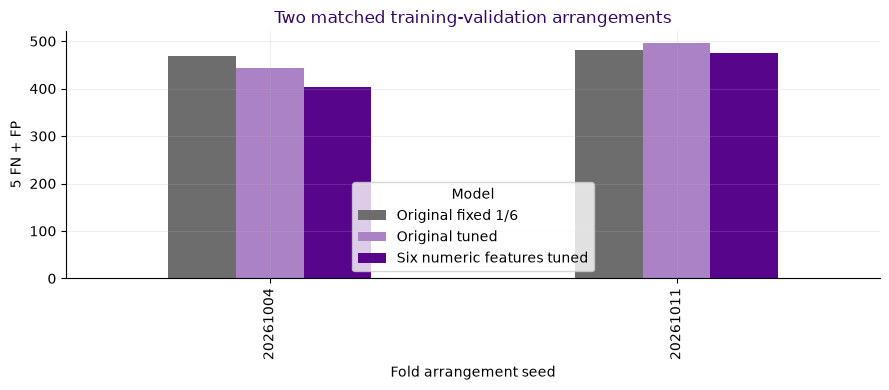

In [38]:
from threadpoolctl import threadpool_limits

COMPARISON_PARAMS = {'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': False, 'interaction_cst': None, 'l2_regularization': 1, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': 42, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
comparison_seeds = (20261004, 20261011)
comparison_cutoffs = np.unique(np.r_[np.arange(.05, .36, .01), 1/6, .01, .03, .4, .5, .6, .8])
comparison_groups = profile_groups(X_train)

def build_final_candidate(use_liquidity=False):
    model = make_model('HistGradientBoostingClassifier', 'normalized', False, **COMPARISON_PARAMS)
    if use_liquidity:
        model.set_params(features=LiquidityQualityFeatures(mode='normalized'))
    return model

def choose_comparison_cutoff(y, probability):
    choices = [(cost(y, (probability >= t).astype(int)), float(t)) for t in comparison_cutoffs]
    return min(choices, key=lambda item: (item[0], -item[1]))[1]

comparison_rows = []
comparison_fold_rows = []
comparison_rule_names = ['Original fixed 1/6', 'Original tuned', 'Six numeric features tuned']
with threadpool_limits(limits=1):
    for split_seed in comparison_seeds:
        outer = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
            random_state=split_seed).split(X_train, y_train, groups=comparison_groups))
        probabilities = {name: np.empty(len(y_train)) for name in comparison_rule_names}
        predictions = {name: np.empty(len(y_train), dtype=int) for name in comparison_rule_names}
        for fold, (fit_idx, val_idx) in enumerate(outer, 1):
            X_fit, y_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
            X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
            fit_groups = comparison_groups[fit_idx]
            assert not set(fit_groups) & set(comparison_groups[val_idx])
            inner = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
                random_state=31415).split(X_fit, y_fit, groups=fit_groups))
            for use_liquidity, name in [(False, 'Original tuned'), (True, 'Six numeric features tuned')]:
                p_inner = np.empty(len(y_fit))
                for inner_fit, inner_val in inner:
                    assert not set(fit_groups[inner_fit]) & set(fit_groups[inner_val])
                    model = build_final_candidate(use_liquidity).fit(X_fit.iloc[inner_fit], y_fit.iloc[inner_fit])
                    p_inner[inner_val] = model.predict_proba(X_fit.iloc[inner_val])[:, 1]
                threshold = choose_comparison_cutoff(y_fit, p_inner)
                model = build_final_candidate(use_liquidity).fit(X_fit, y_fit)
                p_val = model.predict_proba(X_val)[:, 1]
                rules = [(name, threshold)]
                if not use_liquidity: rules.append(('Original fixed 1/6', 1/6))
                for rule, cutoff in rules:
                    pred = (p_val >= cutoff).astype(int)
                    probabilities[rule][val_idx] = p_val
                    predictions[rule][val_idx] = pred
                    row = metric_row(y_val, pred, p_val)
                    row.update(Seed=split_seed, Fold=fold, Model=rule, Threshold=cutoff)
                    comparison_fold_rows.append(row)
            print(f'Final comparison: seed {split_seed}, fold {fold}/5 complete', flush=True)
        for rule in comparison_rule_names:
            row = metric_row(y_train, predictions[rule], probabilities[rule])
            row.update(Seed=split_seed, Model=rule)
            comparison_rows.append(row)

comparison_summary = pd.DataFrame(comparison_rows).set_index(['Seed', 'Model'])
comparison_folds = pd.DataFrame(comparison_fold_rows)
comparison_totals = comparison_summary.groupby('Model')[['Cost', 'FN', 'FP']].sum()
SELECTED_USE_LIQUIDITY = bool(comparison_totals.loc['Six numeric features tuned', 'Cost'] <
    comparison_totals.loc['Original tuned', 'Cost'])
selected_candidate_name = 'Six numeric features tuned' if SELECTED_USE_LIQUIDITY else 'Original tuned'
paired_costs = comparison_folds.pivot(index=['Seed', 'Fold'], columns='Model', values='Cost')
liquidity_fold_wins = int((paired_costs['Six numeric features tuned'] < paired_costs['Original tuned']).sum())
display(comparison_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
display(paired_costs)
display(comparison_totals)
print('Selected from training validation:', selected_candidate_name)
print('Six-feature wins against tuned original:', liquidity_fold_wins, 'of 10 folds')

# Estimate the chosen procedure's deployment cutoff; this optimized cost is not a new validation score.
full_inner = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
    random_state=31415).split(X_train, y_train, groups=comparison_groups))
selected_full_oof = np.empty(len(y_train))
with threadpool_limits(limits=1):
    for fit_idx, val_idx in full_inner:
        assert not set(comparison_groups[fit_idx]) & set(comparison_groups[val_idx])
        model = build_final_candidate(SELECTED_USE_LIQUIDITY).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        selected_full_oof[val_idx] = model.predict_proba(X_train.iloc[val_idx])[:, 1]
SELECTED_FINAL_THRESHOLD = choose_comparison_cutoff(y_train, selected_full_oof)
selected_cutoff_optimized_cost = cost(y_train, (selected_full_oof >= SELECTED_FINAL_THRESHOLD).astype(int))
print('Training-only final cutoff:', SELECTED_FINAL_THRESHOLD)
print('Cutoff-fitting OOF cost (optimized, not independent):', selected_cutoff_optimized_cost)
fig, ax = plt.subplots(figsize=(9, 4))
comparison_summary['Cost'].unstack('Model').plot.bar(ax=ax,
    color=[NYU_GRAY, NYU_LIGHT_PURPLE, NYU_PURPLE])
ax.set(title='Two matched training-validation arrangements', xlabel='Fold arrangement seed', ylabel='5 FN + FP')
plt.tight_layout(); plt.show()


This repeated-fold comparison keeps the classifier fixed and gives both feature versions the same cutoff search. I check total cost and paired wins rather than rely on one favorable split. Both arrangements reuse the training companies, so they are a sensitivity check. The next step tunes both classifiers with the same budget before I make the final choice.


<a id="fine-tuning-both-finalists-fairly"></a>

### Fine-tuning both finalists fairly

I tune each finalist separately with the same eight combinations: maximum leaves in {7, 15}, learning rate in {0.05, 0.1}, and L2 penalty in {1, 10}. Both keep 150 boosting iterations and the same preprocessing. Each feature set may select different settings from that equal budget.

I choose classifier settings and cutoff together within three grouped inner folds. GridSearchCV reuses each fitted classifier's probabilities across the fixed cutoff grid. The selection order is lowest cost, higher AP, higher cutoff, then smaller trees. Outer validation labels never select their own settings.

The two existing five-fold outer arrangements compare the selected procedures. Lower combined cost selects the feature version; an exact tie retains the original. I then repeat the inner search on all X_train to obtain deployment settings and refit the final pipeline. The optimized full-training score is a tuning result, not independent validation.

This comparison selects the feature representation. The later capacity study checks a broader classifier search on that representation. I treat both as practical choices on an explored training population, with limits. The whole-bundle result cannot establish how much each added feature contributes.

Equal-grid tuning completed: seed 20261004, outer fold 1/5


Equal-grid tuning completed: seed 20261004, outer fold 2/5


Equal-grid tuning completed: seed 20261004, outer fold 3/5


Equal-grid tuning completed: seed 20261004, outer fold 4/5


Equal-grid tuning completed: seed 20261004, outer fold 5/5


Equal-grid tuning completed: seed 20261011, outer fold 1/5


... (7 outputs left out)

,Cost,FN,FP
Model,,,
Original features,912,119,317
Six numeric features,875,107,340


Selected from equal-budget tuning: Six numeric features
Six-feature paired fold wins: 6 of 10


,Params,Threshold,Inner_cost,Inner_AP,Row,Model
0,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 7}",0.11,457,0.736211,0,Original features
1,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 15}",0.07,449,0.735579,1,Original features
2,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.1, 'classifier__max_leaf_nodes': 7}",0.12,435,0.744627,2,Original features
3,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.1, 'classifier__max_leaf_nodes': 15}",0.09,468,0.737562,3,Original features
4,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 7}",0.15,491,0.719376,4,Original features
5,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 15}",0.17,490,0.728065,5,Original features
6,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.1, 'classifier__max_leaf_nodes': 7}",0.13,463,0.732978,6,Original features
7,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.1, 'classifier__max_leaf_nodes': 15}",0.13,489,0.723958,7,Original features
8,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 7}",0.12,452,0.744224,0,Six numeric features
9,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 15}",0.07,449,0.745864,1,Six numeric features


Eight-setting candidate settings: {'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.1, 'classifier__max_leaf_nodes': 7}
Eight-setting candidate cutoff: 0.08000000000000002
Optimized full-training search cost (not independent): 426


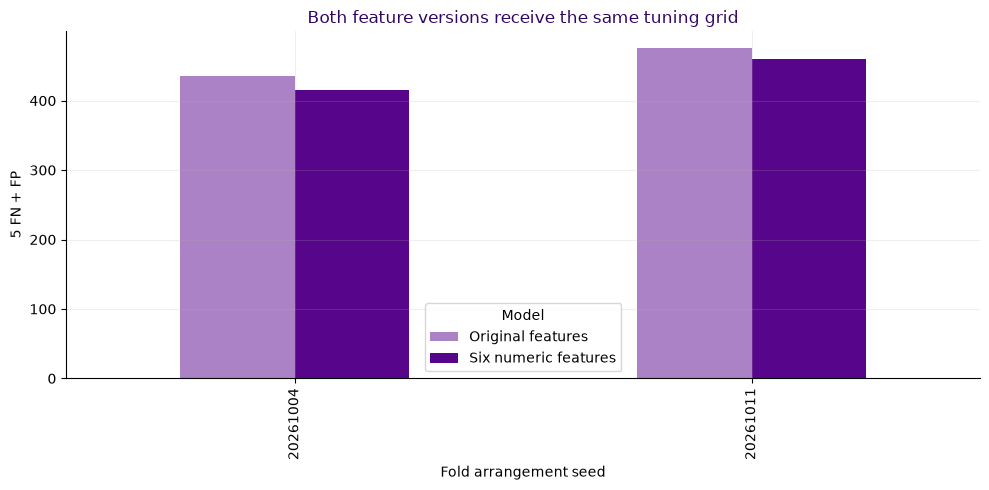

In [39]:
from threadpoolctl import threadpool_limits

FINAL_TUNING_BASE_PARAMS = {'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': False, 'interaction_cst': None, 'l2_regularization': 1, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': 42, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
final_tuning_grid = {
    'classifier__max_leaf_nodes': [7, 15],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__l2_regularization': [1, 10]}
final_tuning_cutoffs = np.unique(np.r_[np.arange(.05, .36, .01), 1/6, .01, .03, .4, .5, .6, .8])
final_tuning_seeds = (20261004, 20261011)
final_tuning_groups = profile_groups(X_train)
final_tuning_names = ['Original features', 'Six numeric features']

def final_tuning_model(use_liquidity=False):
    model = make_model('HistGradientBoostingClassifier', 'normalized', False, **FINAL_TUNING_BASE_PARAMS)
    if use_liquidity:
        model.set_params(features=LiquidityQualityFeatures(mode='normalized'))
    return model

def threshold_cost(y_true, probability, threshold):
    return cost(y_true, (np.asarray(probability) >= threshold).astype(int))

# All cutoffs reuse the same predict_proba response within sklearn's multi-metric scoring.
final_tuning_scoring = {'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}
for i, cutoff in enumerate(final_tuning_cutoffs):
    final_tuning_scoring[f'cost_{i:02d}'] = make_scorer(threshold_cost,
        response_method='predict_proba', greater_is_better=False, threshold=float(cutoff))

def search_finalist(X, y, groups, use_liquidity):
    splits = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
        random_state=31415).split(X, y, groups=groups))
    for fit_idx, val_idx in splits:
        assert not set(groups[fit_idx]) & set(groups[val_idx])
    search = GridSearchCV(final_tuning_model(use_liquidity), final_tuning_grid,
        scoring=final_tuning_scoring, cv=splits, refit=False, n_jobs=1,
        return_train_score=False, error_score='raise')
    search.fit(X, y)
    results = search.cv_results_
    choices = []
    for row, setting in enumerate(results['params']):
        for i, cutoff in enumerate(final_tuning_cutoffs):
            # Each company is validated once; mean fold total * 3 is the aggregate cost.
            inner_cost = int(round(-results[f'mean_test_cost_{i:02d}'][row] * len(splits)))
            choices.append(dict(Params=setting, Threshold=float(cutoff), Inner_cost=inner_cost,
                Inner_AP=float(results['mean_test_AP'][row]), Row=row))
    choices.sort(key=lambda z: (z['Inner_cost'], -z['Inner_AP'], -z['Threshold'],
        z['Params']['classifier__max_leaf_nodes'], z['Row']))
    best = choices[0]
    best_per_setting = []
    for row in range(len(results['params'])):
        best_per_setting.append(next(choice for choice in choices if choice['Row']==row))
    assert len(best_per_setting)==8
    return best, pd.DataFrame(best_per_setting)

final_tuning_rows = []
final_tuning_fold_rows = []
final_tuning_best_rows = []
final_tuning_probabilities = {}
final_tuning_predictions = {}

def run_final_tuning_fold(split_seed, fold, fit_idx, val_idx):
    X_fit, y_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
    X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
    fit_groups = final_tuning_groups[fit_idx]
    assert not set(fit_groups) & set(final_tuning_groups[val_idx])
    with threadpool_limits(limits=1):
        for use_liquidity, name in [(False, 'Original features'), (True, 'Six numeric features')]:
            best, grid_table = search_finalist(X_fit, y_fit, fit_groups, use_liquidity)
            model = final_tuning_model(use_liquidity).set_params(**best['Params']).fit(X_fit, y_fit)
            probability = model.predict_proba(X_val)[:, 1]
            prediction = (probability >= best['Threshold']).astype(int)
            key = (split_seed, name)
            if key not in final_tuning_probabilities:
                final_tuning_probabilities[key] = np.empty(len(y_train))
                final_tuning_predictions[key] = np.empty(len(y_train), dtype=int)
            final_tuning_probabilities[key][val_idx] = probability
            final_tuning_predictions[key][val_idx] = prediction
            row = metric_row(y_val, prediction, probability)
            row.update(Seed=split_seed, Fold=fold, Model=name)
            final_tuning_fold_rows.append(row)
            final_tuning_best_rows.append(dict(Seed=split_seed, Fold=fold, Model=name,
                Params=best['Params'], Threshold=best['Threshold'], Inner_cost=best['Inner_cost']))
    print(f'Equal-grid tuning completed: seed {split_seed}, outer fold {fold}/5', flush=True)

# Evaluate both tuned procedures on matched outer folds.
for split_seed in final_tuning_seeds:
    outer_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
        random_state=split_seed).split(X_train, y_train, groups=final_tuning_groups))
    for fold, (fit_idx, val_idx) in enumerate(outer_splits, 1):
        run_final_tuning_fold(split_seed, fold, fit_idx, val_idx)

for split_seed in final_tuning_seeds:
    for name in final_tuning_names:
        key = (split_seed, name)
        row = metric_row(y_train, final_tuning_predictions[key], final_tuning_probabilities[key])
        row.update(Seed=split_seed, Model=name)
        final_tuning_rows.append(row)
final_tuning_summary = pd.DataFrame(final_tuning_rows).set_index(['Seed', 'Model'])
final_tuning_totals = final_tuning_summary.groupby('Model')[['Cost', 'FN', 'FP']].sum()
final_tuning_paired_costs = pd.DataFrame(final_tuning_fold_rows).pivot(
    index=['Seed', 'Fold'], columns='Model', values='Cost')
FINAL_TUNING_USE_LIQUIDITY = bool(final_tuning_totals.loc['Six numeric features', 'Cost'] <
    final_tuning_totals.loc['Original features', 'Cost'])
final_tuning_selected_name = 'Six numeric features' if FINAL_TUNING_USE_LIQUIDITY else 'Original features'
final_tuning_liquidity_wins = int((final_tuning_paired_costs['Six numeric features'] <
    final_tuning_paired_costs['Original features']).sum())
display(final_tuning_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
display(final_tuning_paired_costs)
display(pd.DataFrame(final_tuning_best_rows))
display(final_tuning_totals)
print('Selected from equal-budget tuning:', final_tuning_selected_name)
print('Six-feature paired fold wins:', final_tuning_liquidity_wins, 'of 10')

# Refit the same search on training data to obtain deployment settings; no test data enter it.
final_full_search_choices = {}
final_full_search_tables = []
with threadpool_limits(limits=1):
    for use_liquidity, name in [(False, 'Original features'), (True, 'Six numeric features')]:
        best, grid_table = search_finalist(X_train, y_train, final_tuning_groups, use_liquidity)
        final_full_search_choices[name] = best
        grid_table['Model'] = name
        final_full_search_tables.append(grid_table)
chosen_full_tuning = final_full_search_choices[final_tuning_selected_name]
FINAL_TUNING_PARAMS = dict(FINAL_TUNING_BASE_PARAMS)
FINAL_TUNING_PARAMS.update({key.replace('classifier__', ''):value
    for key,value in chosen_full_tuning['Params'].items()})
FINAL_TUNING_THRESHOLD = chosen_full_tuning['Threshold']
FINAL_TUNING_OPTIMIZED_COST = chosen_full_tuning['Inner_cost']
display(pd.concat(final_full_search_tables, ignore_index=True))
print('Eight-setting candidate settings:', chosen_full_tuning['Params'])
print('Eight-setting candidate cutoff:', FINAL_TUNING_THRESHOLD)
print('Optimized full-training search cost (not independent):', FINAL_TUNING_OPTIMIZED_COST)
fig, ax = plt.subplots(figsize=(10, 5))
final_tuning_summary['Cost'].unstack('Model').plot.bar(ax=ax, color=[NYU_LIGHT_PURPLE, NYU_PURPLE])
ax.set(title='Both feature versions receive the same tuning grid', xlabel='Fold arrangement seed', ylabel='5 FN + FP')
plt.tight_layout(); plt.show()


Equal-budget classifier and cutoff tuning gives costs of 436 versus 415 in the first arrangement and 476 versus 460 in the second, for the original and six-feature versions. Combined costs are 912 and 875, a modest 4.1% reduction. The six-feature version wins six folds, ties one and loses three, so I select it under the fixed rule.

Across the repeated arrangements, it misses 12 fewer bankruptcies but adds 23 false alarms: 5*12 − 23 = 37 cost units saved. The same companies appear twice. The full-training inner search supplies deployment settings; its optimized score is not another independent evaluation.

This initial grid left capacity settings fixed and selected L2 at its lower edge. These concerns motivate the later capacity study. I judge changes by validation cost, not training fit alone.

<a id="exploring-model-capacity-and-regularization"></a>

### Exploring model capacity and regularization

My eight-setting search kept the iteration count, minimum leaf size and feature-sampling fraction fixed. The chosen L2 penalty was also at the lower edge of its range. I want to check whether changing these choices helps the model generalize rather than fitting the training rows so closely.

I keep the selected six-feature representation, median filling and flags. I compare the old eight settings with 24 settings that include those eight and 16 additional settings sampled with a fixed seed. The broader search covers 100, 150 and 300 iterations; minimum leaf sizes of 10, 20, 40 and 80; feature fractions of 0.7 and 1.0; and L2 penalties of 0.1, 1, 10 and 30. It also allows both previous learning rates and leaf limits. This is a bounded search, not an exhaustive one.

Both procedures choose settings and cutoff jointly inside the same three grouped inner folds and are assessed on the same two five-fold grouped outer arrangements. I reuse classifier fits shared by both searches, but each search can choose only from its eligible settings. Early stopping stays off, so there is no ungrouped internal stopping split. All preprocessing is fitted inside the folds.

Before running the comparison, I require the broader procedure to have lower cost in both arrangements and win at least six of ten paired folds before replacing the original procedure. No test or actual holdout rows enter this study. The training population has already been explored, so this nesting does not remove all repeated-validation bias.


,l2_regularization,learning_rate,max_leaf_nodes,max_iter,min_samples_leaf,max_features
0,1,0.05,7,150,20,1
1,1,0.05,15,150,20,1
2,1,0.1,7,150,20,1
3,1,0.1,15,150,20,1
4,10,0.05,7,150,20,1
5,10,0.05,15,150,20,1
6,10,0.1,7,150,20,1
7,10,0.1,15,150,20,1
8,0.1,0.05,15,100,80,1
9,10,0.1,15,100,10,0.7


Capacity search: seed 20261004, outer fold 1/5 started


Capacity search: seed 20261004, outer fold 1/5 completed


Capacity search: seed 20261004, outer fold 2/5 started


Capacity search: seed 20261004, outer fold 2/5 completed


Capacity search: seed 20261004, outer fold 3/5 started


... (18 outputs left out)

,Cost,FN,FP
Search,,,
Broader 24-setting search,849,111,294
Original eight-setting search,875,107,340


Broader search paired wins: 7 of 10
Passes the pre-set replacement rule: True


,Row,Params,Threshold,Inner_cost,Inner_AP
0,0,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.05, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 7, 'classifier__min_samples_leaf': 20}",0.12,452,0.744224
1,1,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.05, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 15, 'classifier__min_samples_leaf': 20}",0.07,449,0.745864
2,2,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.1, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 7, 'classifier__min_samples_leaf': 20}",0.08,426,0.767728
3,3,"{'classifier__l2_regularization': 1, 'classifier__learning_rate': 0.1, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 15, 'classifier__min_samples_leaf': 20}",0.05,429,0.753455
4,4,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.05, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 7, 'classifier__min_samples_leaf': 20}",0.166667,475,0.722994
5,5,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.05, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 15, 'classifier__min_samples_leaf': 20}",0.12,477,0.729518
6,6,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.1, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 7, 'classifier__min_samples_leaf': 20}",0.15,486,0.732795
7,7,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.1, 'classifier__max_features': 1.0, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 15, 'classifier__min_samples_leaf': 20}",0.15,468,0.732277
8,8,"{'classifier__l2_regularization': 0.1, 'classifier__learning_rate': 0.05, 'classifier__max_features': 1.0, 'classifier__max_iter': 100, 'classifier__max_leaf_nodes': 15, 'classifier__min_samples_leaf': 80}",0.11,493,0.688843
9,9,"{'classifier__l2_regularization': 10, 'classifier__learning_rate': 0.1, 'classifier__max_features': 0.7, 'classifier__max_iter': 100, 'classifier__max_leaf_nodes': 15, 'classifier__min_samples_leaf': 10}",0.09,487,0.734802


Training-selected capacity parameters: {'l2_regularization': 0.1, 'learning_rate': 0.05, 'max_features': 0.7, 'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}
Training-selected cutoff: 0.15000000000000002
Optimized full-training cost (not independent): 423


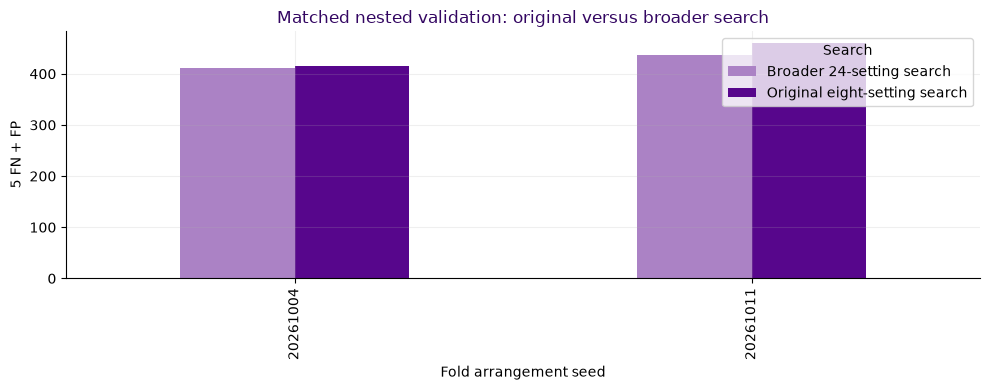

In [40]:
# A broader capacity/regularization search on the selected feature representation.
# No test data or real holdout data enter this experiment.
from sklearn.model_selection import ParameterGrid, ParameterSampler
from threadpoolctl import threadpool_limits

capacity_old_grid = {
    'classifier__max_leaf_nodes': [7, 15],
    'classifier__learning_rate': [.05, .1],
    'classifier__l2_regularization': [1, 10]}
capacity_settings = []
for setting in ParameterGrid(capacity_old_grid):
    setting.update(classifier__max_iter=150, classifier__min_samples_leaf=20,
        classifier__max_features=1.0)
    capacity_settings.append(setting)
capacity_space = {
    'classifier__max_iter': [100, 150, 300],
    'classifier__min_samples_leaf': [10, 20, 40, 80],
    'classifier__max_features': [.7, 1.0],
    'classifier__l2_regularization': [.1, 1, 10, 30],
    'classifier__max_leaf_nodes': [7, 15],
    'classifier__learning_rate': [.05, .1]}
# A fixed sample keeps this study manageable; the old eight settings remain eligible.
for setting in ParameterSampler(capacity_space, n_iter=64, random_state=20261012):
    if setting not in capacity_settings:
        capacity_settings.append(setting)
    if len(capacity_settings) == 24:
        break
assert len(capacity_settings) == 24
for parameter, values in capacity_space.items():
    assert set(values) <= {s[parameter] for s in capacity_settings}
capacity_grid = [{key: [value] for key, value in setting.items()}
    for setting in capacity_settings]
display(pd.DataFrame(capacity_settings).rename(columns=lambda col: col.replace('classifier__', '')))
capacity_cutoffs = np.unique(np.r_[np.arange(.05, .36, .01), 1/6, .01, .03, .4, .5, .6, .8])
capacity_groups = profile_groups(X_train)
capacity_seeds = (20261004, 20261011)
capacity_names = ['Original eight-setting search', 'Broader 24-setting search']

def capacity_model():
    model = make_model('HistGradientBoostingClassifier', 'normalized', False,
        max_iter=150, max_leaf_nodes=7, min_samples_leaf=20, learning_rate=.1,
        l2_regularization=1, early_stopping=False, random_state=42)
    return model.set_params(features=LiquidityQualityFeatures(mode='normalized'))

def capacity_threshold_cost(y_true, probability, threshold):
    return cost(y_true, (np.asarray(probability) >= threshold).astype(int))

capacity_scoring = {'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}
for i, cutoff in enumerate(capacity_cutoffs):
    capacity_scoring[f'cost_{i:02d}'] = make_scorer(capacity_threshold_cost,
        response_method='predict_proba', greater_is_better=False, threshold=float(cutoff))

def capacity_search(X, y, groups):
    inner = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
        random_state=31415).split(X, y, groups=groups))
    for fit_idx, val_idx in inner:
        assert not set(groups[fit_idx]) & set(groups[val_idx])
    search = GridSearchCV(capacity_model(), capacity_grid, cv=inner,
        scoring=capacity_scoring, refit=False, n_jobs=1, error_score='raise')
    search.fit(X, y)
    result = search.cv_results_
    choices = []
    for row, setting in enumerate(result['params']):
        for i, cutoff in enumerate(capacity_cutoffs):
            choices.append(dict(Row=row, Params=setting, Threshold=float(cutoff),
                Inner_cost=int(round(-result[f'mean_test_cost_{i:02d}'][row]*len(inner))),
                Inner_AP=float(result['mean_test_AP'][row])))
    choices.sort(key=lambda choice: (choice['Inner_cost'], -choice['Inner_AP'],
        -choice['Threshold'], choice['Params']['classifier__max_leaf_nodes'], choice['Row']))
    # Share fits, but let each search select only from its own eligible settings.
    old = next(choice for choice in choices if choice['Row'] < 8)
    expanded = choices[0]
    per_setting = pd.DataFrame([next(choice for choice in choices if choice['Row'] == row)
        for row in range(len(capacity_settings))])
    return old, expanded, per_setting

capacity_probabilities = {}
capacity_predictions = {}
capacity_fold_rows = []
capacity_choices = []
with threadpool_limits(limits=1):
    for seed in capacity_seeds:
        folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
            random_state=seed).split(X_train, y_train, groups=capacity_groups))
        for fold, (fit_idx, val_idx) in enumerate(folds, 1):
            assert not set(capacity_groups[fit_idx]) & set(capacity_groups[val_idx])
            print(f'Capacity search: seed {seed}, outer fold {fold}/5 started', flush=True)
            old, expanded, _ = capacity_search(X_train.iloc[fit_idx], y_train.iloc[fit_idx],
                capacity_groups[fit_idx])
            for name, selected in zip(capacity_names, (old, expanded)):
                fitted = capacity_model().set_params(**selected['Params']).fit(
                    X_train.iloc[fit_idx], y_train.iloc[fit_idx])
                probability = fitted.predict_proba(X_train.iloc[val_idx])[:, 1]
                prediction = (probability >= selected['Threshold']).astype(int)
                key = (seed, name)
                if key not in capacity_probabilities:
                    capacity_probabilities[key] = np.empty(len(y_train))
                    capacity_predictions[key] = np.empty(len(y_train), dtype=int)
                capacity_probabilities[key][val_idx] = probability
                capacity_predictions[key][val_idx] = prediction
                row = metric_row(y_train.iloc[val_idx], prediction, probability)
                row.update(Seed=seed, Fold=fold, Search=name)
                capacity_fold_rows.append(row)
                capacity_choices.append(dict(Seed=seed, Fold=fold, Search=name,
                    Params=selected['Params'], Threshold=selected['Threshold'], Inner_cost=selected['Inner_cost']))
            print(f'Capacity search: seed {seed}, outer fold {fold}/5 completed', flush=True)
capacity_rows = []
for seed in capacity_seeds:
    for name in capacity_names:
        row = metric_row(y_train, capacity_predictions[(seed, name)], capacity_probabilities[(seed, name)])
        row.update(Seed=seed, Search=name)
        capacity_rows.append(row)
capacity_summary = pd.DataFrame(capacity_rows).set_index(['Seed', 'Search'])
capacity_totals = capacity_summary.groupby('Search')[['Cost', 'FN', 'FP']].sum()
capacity_paired = pd.DataFrame(capacity_fold_rows).pivot(index=['Seed', 'Fold'], columns='Search', values='Cost')
capacity_wins = int((capacity_paired[capacity_names[1]] < capacity_paired[capacity_names[0]]).sum())
capacity_both_better = all(capacity_summary.loc[(seed, capacity_names[1]), 'Cost'] <
    capacity_summary.loc[(seed, capacity_names[0]), 'Cost'] for seed in capacity_seeds)
CAPACITY_USE_EXPANDED = bool(capacity_both_better and capacity_wins >= 6)
display(capacity_summary[['Cost', 'FN', 'FP', 'Recall', 'Precision', 'AP', 'Brier']])
display(capacity_paired)
display(pd.DataFrame(capacity_choices))
display(capacity_totals)
print('Broader search paired wins:', capacity_wins, 'of 10')
print('Passes the pre-set replacement rule:', CAPACITY_USE_EXPANDED)
# Only after the nested comparison: choose deployment settings from training data.
with threadpool_limits(limits=1):
    capacity_full_old, capacity_full_expanded, capacity_full_table = capacity_search(
        X_train, y_train, capacity_groups)
capacity_selected = capacity_full_expanded if CAPACITY_USE_EXPANDED else capacity_full_old
CAPACITY_SELECTED_PARAMS = {key.replace('classifier__', ''): value
    for key, value in capacity_selected['Params'].items()}
CAPACITY_SELECTED_THRESHOLD = capacity_selected['Threshold']
display(capacity_full_table)
print('Training-selected capacity parameters:', CAPACITY_SELECTED_PARAMS)
print('Training-selected cutoff:', CAPACITY_SELECTED_THRESHOLD)
print('Optimized full-training cost (not independent):', capacity_selected['Inner_cost'])
fig, ax = plt.subplots(figsize=(10, 4))
capacity_summary.Cost.unstack('Search').plot.bar(ax=ax, color=[NYU_LIGHT_PURPLE, NYU_PURPLE])
ax.set(title='Matched nested validation: original versus broader search', xlabel='Fold arrangement seed', ylabel='5 FN + FP')
plt.tight_layout(); plt.show()


The original search costs 415 and 460 in the two arrangements; the broader search costs 412 and 437. Combined cost falls from 875 to 849 (3.0%). The broader procedure wins seven folds, ties two and loses one, passing my replacement rule. These are reused training companies, not independent new observations.

There are 46 fewer false alarms but four more missed bankruptcies across the repeated validations: 46 - 5*4 = 26 cost units saved. Recall falls slightly in both arrangements while precision and AP improve slightly. I select the broader procedure for its lower stated cost, not because every metric improves.

The full-training search selects 150 iterations, seven leaves, minimum leaf size 20, learning rate 0.05, feature fraction 0.7 and L2 penalty 0.1, with cutoff 0.15. Its optimized cost of 423 is a tuning score, not independent evaluation. L2 is weaker, so I cannot claim that stronger regularization solved overfitting. The search remains bounded and L2 lies at the new lower edge. I freeze these settings before final test and holdout evaluation.

<a id="checking-reliance-on-missingness-indicators"></a>

### Checking reliance on missingness indicators

Sales growth is missing for 63 training companies, and 59 went bankrupt. I check the selected model's dependence on explicit flags by comparing all flags, removal of only the ratio_21 flag, and removal of all flags on the same two grouped training arrangements.

I keep the broader-search deployment settings and 0.15 cutoff fixed. Preprocessing is refitted within each fold. This is a sensitivity study, not another selection step. Median fills and related columns may still reveal missingness even after flags are removed. I also plot this configuration's training out-of-fold cost against the cutoff. These reused folds describe sensitivity rather than independent performance or a reason to change the rule.

Missingness check: seed 20261004, fold 1/5


Missingness check: seed 20261004, fold 2/5


Missingness check: seed 20261004, fold 3/5


Missingness check: seed 20261004, fold 4/5


Missingness check: seed 20261004, fold 5/5


Missingness check: seed 20261011, fold 1/5


... (3 outputs left out)

Missingness check: seed 20261011, fold 5/5


,Seed,Model,Cost,FN,FP,Recall,AP,Missing_ratio21_rows,Missing_ratio21_recall
0,20261004,All indicators,417,58,127,0.764228,0.767802,63,1
1,20261004,Without ratio_21 indicator,428,59,133,0.760163,0.746991,63,0.949153
2,20261004,Without any indicators,475,67,140,0.727642,0.720677,63,0.949153
3,20261011,All indicators,470,69,125,0.719512,0.740104,63,1
4,20261011,Without ratio_21 indicator,483,70,133,0.715447,0.728082,63,0.966102
5,20261011,Without any indicators,511,75,136,0.695122,0.699848,63,0.966102


,Cost,FN,FP,Cost_change_vs_all
Model,,,,
All indicators,887,127,252,0
Without any indicators,986,142,276,99
Without ratio_21 indicator,911,129,266,24


,Threshold,Cost
11,0.12,440
12,0.13,429
13,0.14,430
14,0.15,423
15,0.16,424
16,0.166667,447
17,0.17,452
18,0.18,449


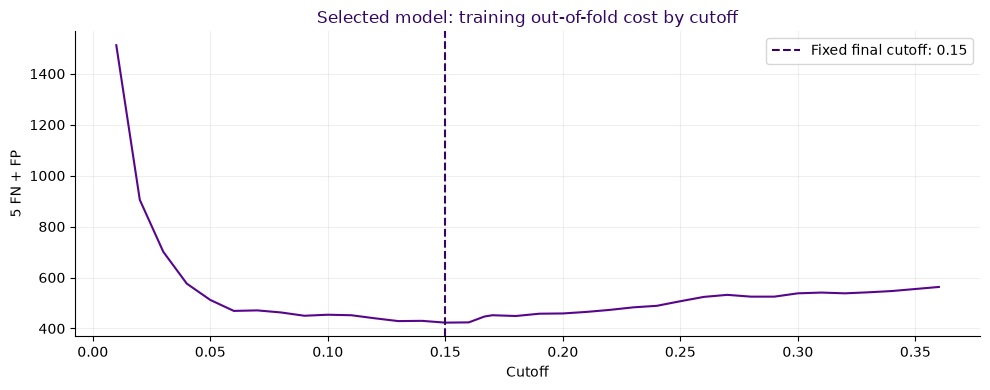

In [41]:
# Diagnostic only: keep the selected classifier and cutoff fixed.
# All replacements and correlation filters are learned inside training folds.
from threadpoolctl import threadpool_limits

class WithoutRatio21Indicator(SimpleImputer):
    def __init__(self):
        super().__init__(strategy='median', add_indicator=True, keep_empty_features=True)

    def transform(self, X):
        values = super().transform(X)
        names = super().get_feature_names_out()
        return values[:, names != 'missingindicator_ratio_21']

    def get_feature_names_out(self, input_features=None):
        names = super().get_feature_names_out(input_features)
        return names[names != 'missingindicator_ratio_21']

robustness_params = {'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'learning_rate': 0.05, 'l2_regularization': 0.1, 'early_stopping': False, 'random_state': 42, 'max_features': 0.7}
robustness_cutoff = 0.15000000000000002
robustness_names = ['All indicators', 'Without ratio_21 indicator', 'Without any indicators']
robustness_groups = profile_groups(X_train)
robustness_rows = []
robustness_fold_rows = []

def robustness_model(name):
    model = make_model('HistGradientBoostingClassifier', 'normalized', False, **robustness_params)
    model.set_params(features=LiquidityQualityFeatures(mode='normalized'))
    if name == 'Without ratio_21 indicator':
        model.set_params(imputer=WithoutRatio21Indicator())
    elif name == 'Without any indicators':
        model.set_params(imputer=SimpleImputer(strategy='median', add_indicator=False,
            keep_empty_features=True))
    return model

with threadpool_limits(limits=1):
    for seed in (20261004, 20261011):
        splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
            random_state=seed).split(X_train, y_train, groups=robustness_groups))
        probabilities = {name: np.empty(len(y_train)) for name in robustness_names}
        for fold, (fit_idx, val_idx) in enumerate(splits, 1):
            assert not set(robustness_groups[fit_idx]) & set(robustness_groups[val_idx])
            for name in robustness_names:
                fitted = robustness_model(name).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
                prob = fitted.predict_proba(X_train.iloc[val_idx])[:, 1]
                probabilities[name][val_idx] = prob
                row = metric_row(y_train.iloc[val_idx], (prob >= robustness_cutoff).astype(int), prob)
                row.update(Seed=seed, Fold=fold, Model=name)
                robustness_fold_rows.append(row)
            print(f'Missingness check: seed {seed}, fold {fold}/5', flush=True)
        for name in robustness_names:
            prob = probabilities[name]
            pred = (prob >= robustness_cutoff).astype(int)
            row = metric_row(y_train, pred, prob)
            absent = X_train.ratio_21.isna().to_numpy()
            row.update(Seed=seed, Model=name, Missing_ratio21_rows=int(absent.sum()),
                Missing_ratio21_recall=recall_score(y_train.iloc[np.flatnonzero(absent)],
                    pred[absent], zero_division=0))
            robustness_rows.append(row)
robustness_table = pd.DataFrame(robustness_rows)
display(robustness_table[['Seed', 'Model', 'Cost', 'FN', 'FP', 'Recall', 'AP',
    'Missing_ratio21_rows', 'Missing_ratio21_recall']])
robustness_totals = robustness_table.groupby('Model')[['Cost', 'FN', 'FP']].sum()
robustness_totals['Cost_change_vs_all'] = robustness_totals.Cost - robustness_totals.loc['All indicators', 'Cost']
display(robustness_totals)
# This compares explicit indicators. Median fills and related columns may still reveal missingness.
# No variant is selected and final_pipeline is not modified.

# A threshold curve for the actual selected configuration, rather than an earlier candidate.
# The selected cutoff remains fixed; this curve is descriptive and does not choose another cutoff.
threshold_check_splits = list(StratifiedGroupKFold(n_splits=3, shuffle=True,
    random_state=31415).split(X_train, y_train, groups=robustness_groups))
threshold_check_prob = np.empty(len(y_train))
with threadpool_limits(limits=1):
    for fit_idx, val_idx in threshold_check_splits:
        assert not set(robustness_groups[fit_idx]) & set(robustness_groups[val_idx])
        model = robustness_model('All indicators').fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        threshold_check_prob[val_idx] = model.predict_proba(X_train.iloc[val_idx])[:, 1]
threshold_check_grid = np.unique(np.r_[np.arange(.01, .361, .01), robustness_cutoff, 1/6])
threshold_check_table = pd.DataFrame([dict(Threshold=float(t),
    Cost=cost(y_train, (threshold_check_prob >= t).astype(int))) for t in threshold_check_grid])
display(threshold_check_table.loc[threshold_check_table.Threshold.between(robustness_cutoff-.0301, robustness_cutoff+.0301)])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(threshold_check_table.Threshold, threshold_check_table.Cost, color=NYU_PURPLE)
ax.axvline(robustness_cutoff, color=NYU_DARK_PURPLE, linestyle='--', label=f'Fixed final cutoff: {robustness_cutoff:.2f}')
ax.set(title='Selected model: training out-of-fold cost by cutoff', xlabel='Cutoff', ylabel='5 FN + FP')
ax.legend(); plt.tight_layout(); plt.show()


For the frozen broader-search configuration, combined validation costs are 887 with all flags, 911 without the ratio_21 flag, and 986 without any flags. The tables also show false alarms, missed bankruptcies and subgroup recall, so I do not judge dependence from cost alone.

This checks explicit flags; it does not prove that all missingness information has disappeared or explain why sales growth is missing. Median fills and related inputs can reveal it. I retain the fixed model because this diagnostic is not an independently tuned comparison of selection procedures. The arrangements repeat the same companies, and these fixed-settings costs differ from the nested-search procedure's 849.

The cutoff curve uses the final configuration and grouped training predictions. I keep 0.15 and report nearby costs without averaging fold optima or changing the rule after viewing the curve. Its optimized full-training cost of 423 is not independent validation.

<a id="the-final-model"></a>

## The final model

The matched feature comparison selected six liquidity relationships. The broader capacity study reduced repeated nested cost from 875 to 849, with seven of ten fold wins. The frozen recipe uses 150 iterations, seven leaves, minimum leaf size 20, learning rate 0.05, feature fraction 0.7, L2 penalty 0.1, and cutoff 0.15. It retains median filling and missingness flags.

Run `python scripts/reproduce.py --data-dir ../private_data --mode final` to refit and evaluate this recipe in a fresh kernel without rerunning exploratory searches. Cells on this route have the `final_rebuild` tag. Use `--mode full` for all research experiments. Recorded nested-validation summaries in the fixed recipe are provenance, not freshly computed evidence on the short route.

The early development studies use 2,891 companies, the later comparisons use 3,854, and the test uses 964. Repeated validation arrangements reuse the training companies and are not independent samples.

In [42]:
# Final model rebuild: the training-selected recipe is fixed here.
# These are settings and recorded validation summaries, not saved fitted objects.
# This cell refits the pipeline from X_train/y_train and needs no search results.
FINAL_SPEC = {'family': 'HistGradientBoostingClassifier', 'mode': 'normalized', 'pca': False, 'params': {'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'learning_rate': 0.05, 'l2_regularization': 0.1, 'early_stopping': False, 'random_state': 42, 'max_features': 0.7}, 'threshold': 0.15000000000000002, 'use_liquidity': True, 'cutoff_optimized_cost': 423, 'comparison_costs': {'Original tuned': 912, 'Six numeric features tuned': 875}, 'comparison_seeds': [20261004, 20261011], 'comparison_fold_wins': 6, 'tuning_method': 'Feature selection: matched eight-setting searches. Capacity selection: matched nested comparison of eight versus 24 settings and joint cutoff tuning.'}

# The targeted imputation decision below is fixed from training validation.
FINAL_SPEC['use_ratio21_regression'] = False
FINAL_SPEC['ratio21_comparison_costs'] = {'Median + flags': 866, 'Predicted ratio_21 + flags': 864}


# Capacity search decision fixed from matched training validation.
FINAL_SPEC['capacity_study'] = {'use_expanded': True, 'wins': 7, 'params': {'l2_regularization': 0.1, 'learning_rate': 0.05, 'max_features': 0.7, 'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}, 'threshold': 0.15000000000000002, 'optimized_cost': 423, 'costs': {'Broader 24-setting search': 849, 'Original eight-setting search': 875}}


# If the full analysis was run, verify its results agree with the fixed final recipe.
# The short rebuild skips this check because it does not run any exploratory searches.
if 'CAPACITY_SELECTED_PARAMS' in globals():
    assert CAPACITY_USE_EXPANDED == FINAL_SPEC['capacity_study']['use_expanded']
    assert CAPACITY_SELECTED_PARAMS == FINAL_SPEC['capacity_study']['params']
    assert np.isclose(CAPACITY_SELECTED_THRESHOLD, FINAL_SPEC['threshold'])
    assert capacity_selected['Inner_cost'] == FINAL_SPEC['cutoff_optimized_cost']
    assert capacity_totals.Cost.astype(int).to_dict() == FINAL_SPEC['capacity_study']['costs']

final_base = make_model(FINAL_SPEC['family'], FINAL_SPEC['mode'], FINAL_SPEC['pca'], **FINAL_SPEC['params'])
if FINAL_SPEC['use_liquidity']:
    final_base.set_params(features=LiquidityQualityFeatures(mode='normalized'))
if FINAL_SPEC['use_ratio21_regression']:
    final_base.set_params(imputer=Ratio21RegressionImputer())
final_pipeline = Pipeline([('decision', FixedThresholdClassifier(
    estimator=final_base, threshold=FINAL_SPEC['threshold']))])
final_pipeline.fit(X_train, y_train)
final_base_fitted = final_pipeline.named_steps['decision'].estimator_
X_features_final = final_base_fitted.named_steps['correlations'].transform(
    final_base_fitted.named_steps['features'].transform(X_train))
print('Final model:', FINAL_SPEC['family'])
print('Added six numeric relationships:', FINAL_SPEC['use_liquidity'])
print('Fitted classifier parameters:', final_base_fitted.named_steps['classifier'].get_params())
print('Model-estimated ratio_21:', FINAL_SPEC['use_ratio21_regression'])
print('Retained financial features:', X_features_final.shape[1])
print('Decision threshold:', FINAL_SPEC['threshold'])
print('Feature comparison costs:', FINAL_SPEC['comparison_costs'])
print('Capacity comparison costs:', FINAL_SPEC['capacity_study']['costs'])
assert X_train.index.equals(train_index_locked)
assert X_test.index.equals(test_index_locked)

# Check raw-input behavior using training rows, before evaluating the test split.
contract_probe = X_train.iloc[:12].copy()
contract_original = contract_probe.copy(deep=True)
contract_probability = final_pipeline.predict_proba(contract_probe)
contract_prediction = final_pipeline.predict(contract_probe)
assert contract_probability.shape == (len(contract_probe), 2)
assert np.isfinite(contract_probability).all()
assert ((contract_probability >= 0) & (contract_probability <= 1)).all()
assert np.allclose(contract_probability.sum(axis=1), 1)
assert contract_prediction.shape == (len(contract_probe),)
assert np.isin(contract_prediction, [0, 1]).all()
assert np.array_equal(contract_prediction,
    (contract_probability[:, 1] >= FINAL_SPEC['threshold']).astype(int))
contract_probe['Id'] = np.arange(len(contract_probe)) + 10**9
contract_probe['Bankrupt'] = 1
assert np.allclose(final_pipeline.predict_proba(contract_probe), contract_probability)
assert np.array_equal(final_pipeline.predict(contract_probe), contract_prediction)
pd.testing.assert_frame_equal(X_train.iloc[:12], contract_original)
print('Raw-input contract passed: Id/target ignored, probabilities valid, binary cutoff embedded.')


Final model: HistGradientBoostingClassifier
Added six numeric relationships: True
Fitted classifier parameters: {'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': False, 'interaction_cst': None, 'l2_regularization': 0.1, 'learning_rate': 0.05, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 0.7, 'max_iter': 150, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': 42, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
Model-estimated ratio_21: False
Retained financial features: 59
Decision threshold: 0.15000000000000002
Feature comparison costs: {'Original tuned': 912, 'Six numeric features tuned': 875}
Capacity comparison costs: {'Broader 24-setting search': 849, 'Original eight-setting search': 875}
Raw-input contract passed: Id/target ignored, probabilities valid, binary cutoff embedded.


# Final evaluation

Evaluate the frozen training-selected recipe on the labeled test split, compare it with the majority baseline, report uncertainty and duplicate-profile sensitivity, then check predictions on the unlabeled file. These diagnostics do not trigger further tuning.

With the model and threshold fixed, I now evaluate the test split and compare the cost with the majority baseline. I report these results without using them to adjust the model.

In [43]:
baseline_cost = evaluate_test_baseline()

Baseline cost (always predicts the majority class): 310


In [44]:
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                              roc_auc_score, average_precision_score)

y_train_pred = final_pipeline.predict(X_train)
y_test_pred = final_pipeline.predict(X_test)

print(f"{'Split':8s} {'Accuracy':>10s} {'Recall':>10s} {'Precision':>10s}")
for split_name, y_true, y_pred in [("Train", y_train, y_train_pred), ("Test", y_test, y_test_pred)]:
    print(f"{split_name:8s} {accuracy_score(y_true, y_pred):>10.1%} "
          f"{recall_score(y_true, y_pred):>10.1%} {precision_score(y_true, y_pred):>10.1%}")

# Ranking metrics and train/test comparison.
if hasattr(final_pipeline, "predict_proba"):
    proba_train = final_pipeline.predict_proba(X_train)[:, 1]
    proba_test = final_pipeline.predict_proba(X_test)[:, 1]
    print(f"\n{'Split':8s} {'ROC-AUC':>10s} {'AP':>10s}")
    print(f"{'Train':8s} {roc_auc_score(y_train, proba_train):>10.4f} "
          f"{average_precision_score(y_train, proba_train):>10.4f}")
    print(f"{'Test':8s} {roc_auc_score(y_test, proba_test):>10.4f} "
          f"{average_precision_score(y_test, proba_test):>10.4f}")
else:
    print("\nfinal_pipeline has no predict_proba -- ROC-AUC/AP not reported "
          "(explain why in the report below).")

assert y_test_pred.shape == (len(X_test),)
assert np.isin(y_test_pred, [0, 1]).all()
assert np.array_equal(y_test_pred, (proba_test >= FINAL_SPEC['threshold']).astype(int))


Split      Accuracy     Recall  Precision
Train         97.8%      95.9%      75.6%
Test          95.7%      85.5%      62.4%



Split       ROC-AUC         AP
Train        0.9969     0.9700
Test         0.9726     0.8571


In [45]:
# Baseline comparison, using the same `cost` function and test split as
# the baseline established earlier.
from sklearn.metrics import confusion_matrix

final_cost = cost(y_test, y_test_pred)
improvement_ratio = baseline_cost / final_cost if final_cost > 0 else float("inf")

print(f"Baseline cost:        {baseline_cost}")
print(f"Final model cost:     {final_cost}")
print(f"Improvement ratio (baseline / final): {improvement_ratio:.2f}")

# Context for the numbers above, so they can be checked.
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()
print(f"\nTest split: {len(y_test)} rows, {int(y_test.sum())} bankrupt")
print(f"Confusion matrix (test): TN={tn} FP={fp} FN={fn} TP={tp}")
# The weights your `cost` function applies, read from the function itself:
print(f"Cost of one missed bankruptcy (FN): {cost(np.array([1]), np.array([0]))}")
print(f"Cost of one false alarm (FP):       {cost(np.array([0]), np.array([1]))}")


Baseline cost:        310
Final model cost:     77
Improvement ratio (baseline / final): 4.03

Test split: 964 rows, 62 bankrupt
Confusion matrix (test): TN=870 FP=32 FN=9 TP=53
Cost of one missed bankruptcy (FN): 5
Cost of one false alarm (FP):       1


In [46]:
# Pairwise correlation after financial transformation and filtering.
X_features = X_features_final.copy()

corr = X_features.corr(numeric_only=True).abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
corr = pd.DataFrame(corr, index=X_features.columns, columns=X_features.columns)
max_corr = corr.to_numpy().max()
worst_pair = corr.stack().idxmax()
print(f"Highest pairwise correlation among final features: {max_corr:.4f} ({worst_pair[0]} vs {worst_pair[1]})")


Highest pairwise correlation among final features: 0.9930 (num_13_to_assets vs num_33_to_assets)


In [47]:
holdout_data = load_holdout_data()

# Validate raw-input prediction behavior on unlabeled companies.
X_hold = holdout_data
y_hold_pred = final_pipeline.predict(X_hold)
assert len(y_hold_pred) == len(X_hold), "predict() didn't return one row per holdout example"
print(f"OK -- predicted {len(y_hold_pred)} rows, bankrupt rate {y_hold_pred.mean():.1%}")

assert np.array_equal(final_pipeline.predict(holdout_data), y_hold_pred)
assert y_hold_pred.shape == (len(holdout_data),)
assert np.isin(y_hold_pred, [0, 1]).all()
holdout_probability = final_pipeline.predict_proba(holdout_data)
assert holdout_probability.shape == (len(holdout_data), 2)
assert np.isfinite(holdout_probability).all()
assert np.allclose(holdout_probability.sum(axis=1), 1)
assert np.array_equal(y_hold_pred,
    (holdout_probability[:, 1] >= FINAL_SPEC['threshold']).astype(int))


Data shape:  (1092, 67)
OK -- predicted 1092 rows, bankrupt rate 11.0%


In [48]:
project_summary = {}

_clf = final_base_fitted.named_steps['classifier']
_imputer = final_base_fitted.named_steps['imputer']
_n_financial = X_features_final.shape[1]
_n_flags = len(_imputer.indicator_.features_)
_n_inputs = len(_imputer.get_feature_names_out())
_chosen = 'six additional numeric relationships' if FINAL_SPEC['use_liquidity'] else 'the original feature set'
_train_ap = average_precision_score(y_train, proba_train)
_test_ap = average_precision_score(y_test, proba_test)
project_summary.update({
    'approach_summary': (
        (
        ('I split the data first, explored missing values and financial relationships, checked amount scales and compared filling methods on training folds. '
        'I compared logistic regression, PCA, Naive Bayes, KNN, a tree, random forest and boosting using grouped validation and cost 5*FN+FP. '
        'I tuned the leading families, then studied training errors, residuals, calibration and liquidity features. '
        'Matched eight-setting nested searches selected the six-feature version. A broader 24-setting search then reduced combined validation cost from 875 to 849, winning seven folds, so I selected it. '
        'Both searches chose settings and cutoff inside three grouped inner folds and used two matched five-fold outer arrangements. '
        'I fixed the training-selected recipe, checked missingness dependence and threshold sensitivity, and retained that rule. Earlier sales-growth estimation had no consistent benefit, so I kept medians and flags. '
        'Repeated training exploration limits the independence of these comparisons; small gains need caution. I refitted X_train and evaluated at the end. The final-model section gives the rebuild path; the final evaluation reports results.'))),
    'model_type': 'HistGradientBoostingClassifier in sklearn Pipeline with FixedThresholdClassifier',
    'model_size': (
        f'{_clf.n_iter_} boosting iterations; max_leaf_nodes={_clf.max_leaf_nodes}; '
        f'max_depth={_clf.max_depth}; learning_rate={_clf.learning_rate}; '
        f'l2_regularization={_clf.l2_regularization}; min_samples_leaf={_clf.min_samples_leaf}; '
        f'max_features={_clf.max_features}. The classifier receives {_n_inputs} inputs: '
        f'{_n_financial} financial columns and {_n_flags} missingness flags. '
        f'Train AP={_train_ap:.4f}; test AP={_test_ap:.4f}. '
        'The training/test gap and the single random split limit how confidently I can generalize; '
        'these results did not trigger further selection.'),
    'feature_engineering_summary': (
        'I ignore Id and recalculate six columns from the stated formulas as alternative features, not exact recovery where the audit finds disagreement. I normalize num_* amounts by '
        'positive assets, and include debt, liquidity and margin relationships; I divide stored inventory and receivables by 365 based on internal agreement with the provided turnover ratios, which does not independently verify the accounting figures. '
        + ('The final model also adds cash/short-debt, quick-assets/short-debt, short-debt/total-debt, '
           'a quick-asset shortfall with nonnegative working capital, converted inventory/current-assets and approximate DSO in days. '
           if FINAL_SPEC['use_liquidity'] else 'The six-feature experiment was not selected. ')
        + 'Zero denominators and infinities become missing; each fitting fold learns its correlation '
        'filter and median replacements and adds missingness flags. A signed log compresses extreme '
        'values; this boosting pipeline uses no PCA or additional scaling.'),
    'imbalance_handling': (
        'I use stratified grouped validation so duplicate financial profiles stay together. '
        'The final model has class_weight=None and no oversampling. I choose decisions by the '
        'asymmetric cost and report bankruptcy recall, precision and AP alongside accuracy.'),
    'cost_ratio_handling': (
        'Cost is consistently 5*FN+FP. In the feature comparison, each candidate receives the same eight-setting classifier grid and jointly chooses its settings and cutoff '
        'using three inner grouped folds, then is evaluated on the same outer validation folds. '
        f'Two arrangements give combined costs {FINAL_SPEC["comparison_costs"]["Original tuned"]} '
        f'for the tuned original and {FINAL_SPEC["comparison_costs"]["Six numeric features tuned"]} '
        'for the six-feature procedure; these repeat the same companies, not twice as many distinct rows. '
        f'The chosen final cutoff is {FINAL_SPEC["threshold"]:.4f}, chosen with the classifier settings from three grouped '
        f'OOF folds on all {len(y_train)} training rows; optimized cost '
        f'{FINAL_SPEC["cutoff_optimized_cost"]} is a joint tuning estimate, not independent validation. '
        'The subsequent 24-setting capacity procedure costs 849 versus 875 for the eight-setting procedure, with seven paired wins. It misses four more bankruptcies but makes 46 fewer false alarms across repeated validation. '
        'Cost ties use higher AP, then a higher cutoff and smaller trees; this rule is fixed in advance. final_pipeline.predict embeds the cutoff; '
        f'final test cost={final_cost}, majority cost={baseline_cost}, '
        f'baseline/final={improvement_ratio:.2f}. This final selection uses training validation only.')
})


if FINAL_SPEC['use_ratio21_regression']:
    project_summary['feature_engineering_summary'] += (
        ' The exception to median filling is ratio_21: a 150-tree regression forest, maximum '
        'depth 10 and minimum leaf size 10, estimates signed-log sales growth from other '
        'financial columns. It trains only on observed ratio_21 values within the fitting data, '
        'never uses Bankruptcy or Id, preserves observed entries, and retains the original missingness flag.')

for key, value in project_summary.items():
    print(f"{key}:\n  {value}\n")


approach_summary:
  I split the data first, explored missing values and financial relationships, checked amount scales and compared filling methods on training folds. I compared logistic regression, PCA, Naive Bayes, KNN, a tree, random forest and boosting using grouped validation and cost 5*FN+FP. I tuned the leading families, then studied training errors, residuals, calibration and liquidity features. Matched eight-setting nested searches selected the six-feature version. A broader 24-setting search then reduced combined validation cost from 875 to 849, winning seven folds, so I selected it. Both searches chose settings and cutoff inside three grouped inner folds and used two matched five-fold outer arrangements. I fixed the training-selected recipe, checked missingness dependence and threshold sensitivity, and retained that rule. Earlier sales-growth estimation had no consistent benefit, so I kept medians and flags. Repeated training exploration limits the independence of these comp

The confusion matrix shows the missed bankruptcies and false alarms behind the final cost. I also compare training and test AP to see how much of a gap remains. The bootstrap intervals use the fixed test predictions to describe uncertainty; I do not fit another model for them. Finally, I check whether any financial profiles appear in both sides of the required train/test split, after all model choices are finished.

,Accuracy,Recall,Precision,ROC_AUC,AP,Brier,TN,FP,FN,TP,Cost,Cost_per_company
Split,,,,,,,,,,,,
Train,0.977686,0.95935,0.75641,0.996914,0.97002,0.0124504,3532,76,10,236,126,0.0326933
Test,0.957469,0.854839,0.623529,0.972588,0.857104,0.0220298,870,32,9,53,77,0.0798755


Majority test accuracy: 0.9356846473029046
Majority test recall: 0.0
Majority test precision: 0.0


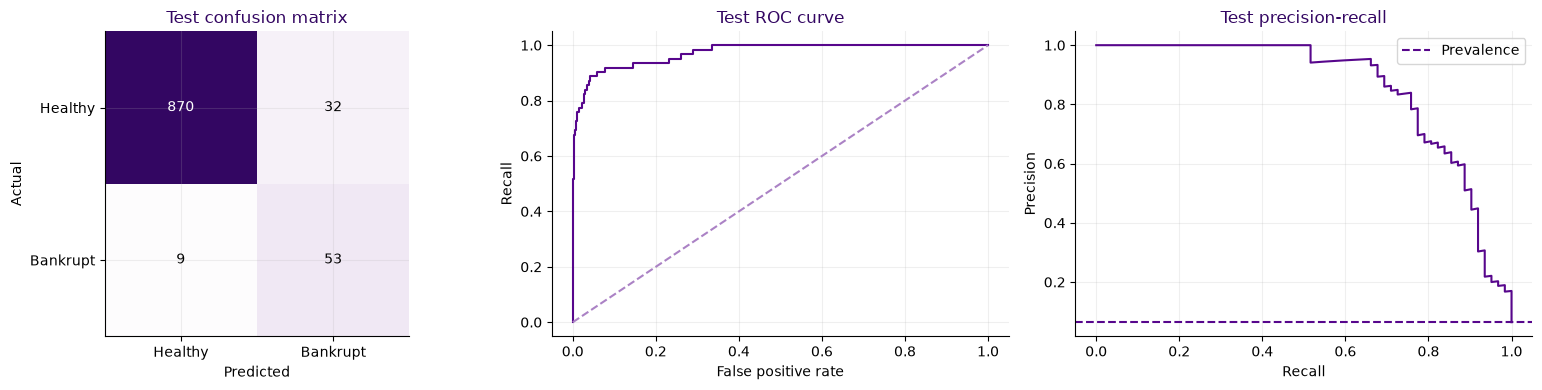

Descriptive bootstrap 95% cost-savings interval: [158.975 304.   ]
Descriptive bootstrap 95% recall interval: [0.76086957 0.93752404]
Test rows with exact financial profiles also in training: 11
Sensitivity on non-overlapping test profiles (same frozen predictions):


,Accuracy,Recall,Precision,ROC_AUC,AP,Brier,TN,FP,FN,TP,Cost,Cost_per_company
0,0.956978,0.852459,0.619048,0.971936,0.853443,0.0221892,860,32,9,52,77,0.0807975


Final test cost is **77**, versus **310** for the majority baseline: a **4.03x** baseline/final ratio. Test recall is **85.5%** and precision is **62.4%**. The model makes **9** costly misses and **32** false alarms. Train minus test AP is **0.113**, which suggests some overfitting but also reflects sampling variation. I do not use this test result to retune the model.

In [49]:
final_rows=[]
for name,y,pred,prob in [('Train',y_train,y_train_pred,proba_train),
                       ('Test',y_test,y_test_pred,proba_test)]:
    r=metric_row(y,pred,prob);r['Split']=name;final_rows.append(r)
final_table=pd.DataFrame(final_rows).set_index('Split');display(final_table)
baseline_pred=baseline_pipeline.predict(X_test)
print('Majority test accuracy:',accuracy_score(y_test,baseline_pred))
print('Majority test recall:',recall_score(y_test,baseline_pred,zero_division=0))
print('Majority test precision:',precision_score(y_test,baseline_pred,zero_division=0))
fig,ax=plt.subplots(1,3,figsize=(16,4))
cm=confusion_matrix(y_test,y_test_pred)
ax[0].imshow(cm.astype(float),cmap=NYU_PURPLES,vmin=0,vmax=float(cm.max()),interpolation='nearest')
for (i,j),v in np.ndenumerate(cm):ax[0].text(j,i,str(v),ha='center',va='center',color='white' if v>cm.max()/2 else 'black')
ax[0].set(xticks=[0,1],yticks=[0,1],xticklabels=['Healthy','Bankrupt'],
    yticklabels=['Healthy','Bankrupt'],xlabel='Predicted',ylabel='Actual',title='Test confusion matrix')
fpr,tpr,_=roc_curve(y_test,proba_test);ax[1].plot(fpr,tpr);ax[1].plot([0,1],[0,1],'--')
ax[1].set(xlabel='False positive rate',ylabel='Recall',title='Test ROC curve')
precision,recall,_=precision_recall_curve(y_test,proba_test)
ax[2].plot(recall,precision);ax[2].axhline(y_test.mean(),ls='--',label='Prevalence')
ax[2].set(xlabel='Recall',ylabel='Precision',title='Test precision-recall');ax[2].legend()
plt.tight_layout();plt.show()
rng=np.random.default_rng(SEED)
yt=np.asarray(y_test);yp=np.asarray(y_test_pred);bp=np.asarray(baseline_pred)
bootstrap=[]
for _ in range(1000):
    ix=rng.integers(0,len(yt),len(yt))
    bootstrap.append([cost(yt[ix],bp[ix])-cost(yt[ix],yp[ix]),
                      recall_score(yt[ix],yp[ix],zero_division=0)])
bounds=np.quantile(bootstrap,[.025,.975],axis=0)
print('Descriptive bootstrap 95% cost-savings interval:',bounds[:,0])
print('Descriptive bootstrap 95% recall interval:',bounds[:,1])
overlap=np.isin(profile_groups(X_test),profile_groups(X_train))
print('Test rows with exact financial profiles also in training:',int(overlap.sum()))
if overlap.any() and len(np.unique(yt[~overlap]))==2:
    print('Sensitivity on non-overlapping test profiles (same frozen predictions):')
    display(pd.DataFrame([metric_row(yt[~overlap],yp[~overlap],proba_test[~overlap])]))
display(Markdown(f'Final test cost is **{final_cost}**, versus **{baseline_cost}** for '
    f'the majority baseline: a **{improvement_ratio:.2f}x** baseline/final ratio. '
    f'Test recall is **{final_table.loc["Test","Recall"]:.1%}** and precision is '
    f'**{final_table.loc["Test","Precision"]:.1%}**. The model makes '
    f'**{final_table.loc["Test","FN"]}** costly misses and '
    f'**{final_table.loc["Test","FP"]}** false alarms. '
    f'Train minus test AP is **{final_table.loc["Train","AP"]-final_table.loc["Test","AP"]:.3f}**, '
    'which suggests some overfitting but also reflects sampling variation. I do not use this test result to retune the model.'))

<a id="checking-the-unlabeled-holdout"></a>

**Checking the unlabeled holdout after fixing the model**

I compare missing values, sales growth, interest coverage, debt and liquidity because a change in the kinds of companies could affect reliability. I use the original inputs and the same fixed arithmetic as before; I fit no transformation here. Missing percentages include nonfinite values, which my pipeline treats as missing. The distribution plots use observed values only.

I use the test split as the reference for the missingness-change decomposition and distribution plots, since its predictions are out of sample. Training rates remain in the table for context. The percentages flagged below are model decisions, not observed bankruptcy rates. I cannot measure holdout accuracy without its labels. These checks come after the final fit and predictions, and I do not use them to change features, settings or the cutoff.

Fixed-model flag rates and missingness (percent)


,Rows,Flagged,Flagged_pct,Missing_ratio21_pct,Missing_ratio05_pct
Split,,,,,
Train,3854,312,8.1,1.63,6.67
Test,964,85,8.82,1.14,4.98
Holdout,1092,120,10.99,2.66,7.88


Fixed-model flags within missing and observed groups (no holdout labels used)


,Split,Feature,Status,Rows,Flagged,Flagged_pct
0,Train,ratio_21,Missing,63,63,100
1,Train,ratio_21,Observed,3791,249,6.57
2,Train,ratio_05,Missing,257,83,32.3
3,Train,ratio_05,Observed,3597,229,6.37
4,Test,ratio_21,Missing,11,11,100
5,Test,ratio_21,Observed,953,74,7.76
6,Test,ratio_05,Missing,48,17,35.42
7,Test,ratio_05,Observed,916,68,7.42
8,Holdout,ratio_21,Missing,29,29,100
9,Holdout,ratio_21,Observed,1063,91,8.56


Missingness: focus columns and six largest absolute changes; pp = percentage points


,Train,Test,Holdout,Holdout_minus_test_pp
ratio_21,1.63,1.14,2.66,1.51
ratio_05,6.67,4.98,7.88,2.9
ratio_01,43.28,41.49,43.96,2.46
ratio_19,1.87,1.14,2.2,1.06
ratio_06,1.87,1.14,2.2,1.06
ratio_14,1.87,1.14,2.2,1.06


Observed financial distributions; no replacement values included


,,Observed,Missing_pct,P10,Median,P90
Feature,Split,,,,,
Sales growth (ratio_21),Train,3791,1.635,0.835,1.119,1.472
Interest coverage (ratio_05),Train,3597,6.668,-0.585,1.009,27.996
Debt / assets,Train,3852,0.052,0.128,0.447,0.864
Current assets / short debt,Train,3843,0.285,0.769,1.658,5.767
Near cash / short debt,Train,3843,0.285,0.019,0.185,1.972
Sales growth (ratio_21),Test,953,1.141,0.829,1.118,1.463
Interest coverage (ratio_05),Test,916,4.979,-1.042,0.872,15.989
Debt / assets,Test,964,0,0.139,0.465,0.871
Current assets / short debt,Test,959,0.519,0.785,1.598,5.075


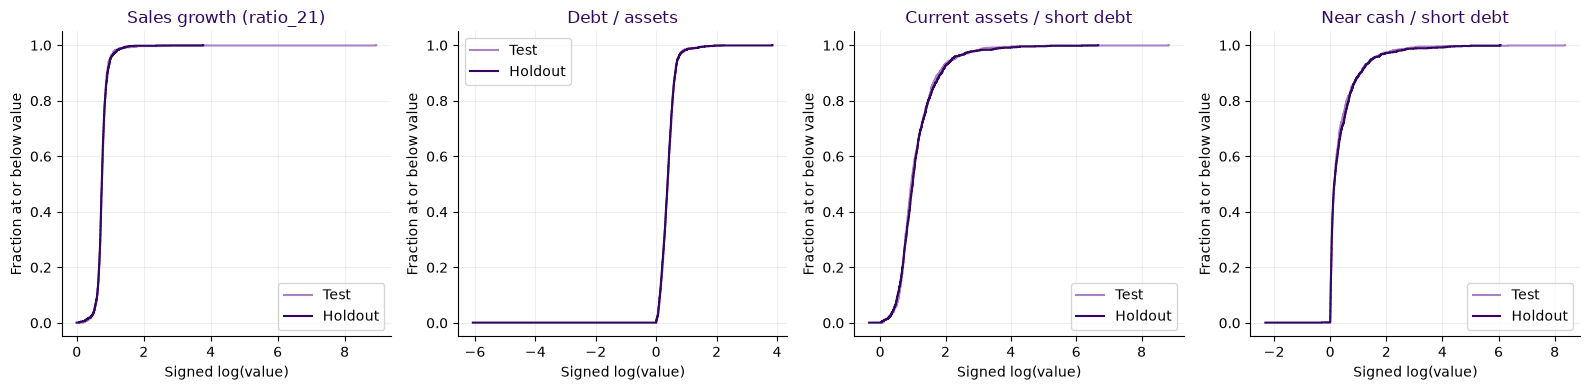

If only the ratio_21 missing share changed, with test group flag rates held fixed, the overall flag rate would change by 1.40 pp.
The actual holdout-minus-test flag-rate difference is 2.17 pp.
This breakdown is descriptive, not causal: other inputs and their relationships also differ.
The missingness signal could reflect distress or data collection. I cannot distinguish those explanations here.
Higher holdout flags alone do not show poorer accuracy. I leave the final model and cutoff unchanged.


In [50]:
# Reliability audit only: no fitting, threshold search or model selection.
audit_frames = {'Train': X_train, 'Test': X_test, 'Holdout': X_hold}
audit_predictions = {'Train': y_train_pred, 'Test': y_test_pred, 'Holdout': y_hold_pred}
audit_raw = {name: frame.drop(columns=['Id', 'Bankrupt'], errors='ignore')
    .replace([np.inf, -np.inf], np.nan) for name, frame in audit_frames.items()}
flag_rows, conditional_rows = [], []
for name, frame in audit_raw.items():
    pred = np.asarray(audit_predictions[name])
    flag_rows.append({'Split': name, 'Rows': len(frame), 'Flagged': int(pred.sum()),
        'Flagged_pct': 100 * pred.mean(),
        'Missing_ratio21_pct': 100 * frame.ratio_21.isna().mean(),
        'Missing_ratio05_pct': 100 * frame.ratio_05.isna().mean()})
    for col in ['ratio_21', 'ratio_05']:
        absent = frame[col].isna().to_numpy()
        for status, mask in [('Missing', absent), ('Observed', ~absent)]:
            conditional_rows.append({'Split': name, 'Feature': col, 'Status': status,
                'Rows': int(mask.sum()), 'Flagged': int(pred[mask].sum()),
                'Flagged_pct': 100 * pred[mask].mean() if mask.any() else np.nan})
flag_table = pd.DataFrame(flag_rows).set_index('Split')
print('Fixed-model flag rates and missingness (percent)')
display(flag_table.round(2))
print('Fixed-model flags within missing and observed groups (no holdout labels used)')
display(pd.DataFrame(conditional_rows).round(2))

missing_shift = pd.DataFrame({name: 100 * frame.isna().mean()
    for name, frame in audit_raw.items()})
missing_shift['Holdout_minus_test_pp'] = missing_shift.Holdout - missing_shift.Test
largest_shifts = missing_shift.Holdout_minus_test_pp.abs().nlargest(6).index.tolist()
review_columns = list(dict.fromkeys(['ratio_21', 'ratio_05'] + largest_shifts))
print('Missingness: focus columns and six largest absolute changes; pp = percentage points')
display(missing_shift.loc[review_columns].round(2))

def audit_financial_values(frame):
    # Row-wise only; no medians, scaling parameters or imputation are learned.
    clean = frame.drop(columns=['Id', 'Bankrupt'], errors='ignore').astype(float)
    clean = clean.replace([np.inf, -np.inf], np.nan)
    assets = clean.total_assets.where(clean.total_assets > 0)
    return pd.DataFrame({'Sales growth (ratio_21)': clean.ratio_21,
        'Interest coverage (ratio_05)': clean.ratio_05,
        'Debt / assets': safe_divide(clean.total_liabilities, assets),
        'Current assets / short debt': safe_divide(clean.num_06, clean.short_term_liabilities),
        'Near cash / short debt': safe_divide(clean.num_12, clean.short_term_liabilities)
    }).replace([np.inf, -np.inf], np.nan)
audit_values = {name: audit_financial_values(frame) for name, frame in audit_frames.items()}
distribution_rows = []
for name, frame in audit_values.items():
    for col in frame:
        values = frame[col].dropna()
        distribution_rows.append({'Feature': col, 'Split': name,
            'Observed': len(values), 'Missing_pct': 100 * frame[col].isna().mean(),
            'P10': values.quantile(.1), 'Median': values.median(), 'P90': values.quantile(.9)})
print('Observed financial distributions; no replacement values included')
display(pd.DataFrame(distribution_rows).set_index(['Feature', 'Split']).round(3))
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
plot_columns = ['Sales growth (ratio_21)', 'Debt / assets',
    'Current assets / short debt', 'Near cash / short debt']
for ax, col in zip(axes, plot_columns):
    for name, color in [('Test', NYU_LIGHT_PURPLE), ('Holdout', NYU_DARK_PURPLE)]:
        values = np.sort(signed_log(audit_values[name][col].dropna().to_numpy()))
        ax.step(values, np.arange(1, len(values)+1)/len(values), where='post',
            color=color, label=name)
    ax.set(title=col, xlabel='Signed log(value)', ylabel='Fraction at or below value')
    ax.legend()
plt.tight_layout(); plt.show()

# A descriptive breakdown of the flag-rate change, not an adjustment to predictions.
test_absent = audit_raw['Test'].ratio_21.isna().to_numpy()
hold_absent = audit_raw['Holdout'].ratio_21.isna().to_numpy()
test_pred = np.asarray(y_test_pred)
test_missing_flag = test_pred[test_absent].mean()
test_observed_flag = test_pred[~test_absent].mean()
hold_mix_only = (hold_absent.mean()*test_missing_flag
    + (1-hold_absent.mean())*test_observed_flag)
mix_effect_pp = 100 * (hold_mix_only-test_pred.mean())
print(f'If only the ratio_21 missing share changed, with test group flag rates held fixed, '
      f'the overall flag rate would change by {mix_effect_pp:.2f} pp.')
print(f'The actual holdout-minus-test flag-rate difference is '
      f'{100*(np.mean(y_hold_pred)-test_pred.mean()):.2f} pp.')
print('This breakdown is descriptive, not causal: other inputs and their relationships also differ.')
print('The missingness signal could reflect distress or data collection. I cannot distinguish those explanations here.')
print('Higher holdout flags alone do not show poorer accuracy. I leave the final model and cutoff unchanged.')


**What I take from this check**

The final model flags 8.82% of test rows and 10.99% of holdout rows. Missing sales growth occurs in 1.14% of test rows and 2.66% of holdout rows. Holding the test-group flag rates fixed, changing only this missing share contributes 1.40 percentage points of the 2.17-point holdout-minus-test difference. Flags among observed-growth rows change from 7.76% to 8.56%. This is descriptive, not a causal explanation.

The test sample and its missing-growth group are small, so group rates may be noisy. I compare financial distributions against the test split and show training numbers for context. Without holdout labels I cannot judge whether additional flags are correct. These checks leave the model and cutoff unchanged.

The final test has 964 companies and 62 bankruptcies. Cost is 77 (0.080 per company), compared with 310 for the majority baseline, using the same 5:1 weights. The selected procedure costs 849/(2*3854) = 0.110 per company across the two grouped arrangements. These reuse extensively explored training companies, so neither this modest validation gain nor one test split provides a precise forecast of future cost.

The final selection procedure uses training validation only, and I do not use the test report or unlabeled holdout diagnostics to choose another model. Eleven test profiles also appear in training under the fixed random split; the sensitivity table reports the same frozen predictions on the remaining profiles.

Missingness may reflect financial distress or data collection. The ratio_21 study cannot establish its cause, and reconstruction of observed values does not verify genuine blanks. The 365 conversion is internally consistent with the supplied ratios, not independent accounting verification. The capacity search is bounded and selects L2 at its lower edge. These limitations remain even though the notebook executes reproducibly.

The notebook displays results in memory and does not export JSON, CSV, figures, models or predictions.